# ATHENA–CAMM Hackathon Day 21
## Readable full analysis: every original trace and four composites

**One experimental pipeline, three independently fitted preference-model families:** stationary choice,
discrete HMM choice, and continuous MAP preference evolution. Image representation is configurable as
handcrafted descriptors, frozen learned-kernel features (`dkl`), or their concatenation.

This revision retains the original Day 20 data-loading section and restores the detailed analysis from
`ATHENA_CAMM_Day21_Detailed_One_Trace_All_Traces`, including the subsequent interpretation and map diagnostics.
New Python code uses one statement per line with no semicolon-separated commands.

**Read the outputs at two levels.** The selected detailed trace has full inline analysis, organized by method.
Every original trace and all four composites receive condensed inline reports. The full diagnostic reports
are also generated and saved for **every** dataset by default, with an HTML index for browsing.

The condensed atlas includes the original image in the top-left, recorded points in **red**, proposed
additional points in **blue**, dense stationary/continuous/HMM reward maps, all K state maps,
**belief-weighted between-state utility variance**, equal-weight state variance, and the HMM next-choice map.
There are no microscopy-image backgrounds beneath reward maps.

No experimental numerical results are prepopulated here. The original data must be loaded to generate them.
The accompanying validation report distinguishes synthetic software tests from experimental execution.

## Opening configuration

Change `feature_mode`, `trace_pairs`, `detailed_trace`, `n_predicted_locations`, and `map_stride` here.
All original traces are always included. The source-ID catalog is printed after loading.
The previous source order is GPT traces 0–2, then simulated traces 0–7, giving IDs 0–10.
The default pairs reuse that numeric ordering, not inferred subject identities.

`map_stride=None` restores the earlier dense spacing of one quarter of the smaller patch dimension.
A value of 2 or 1 evaluates a still denser patch grid. The number of blue points is an upper target,
subject to exclusion around recorded points and minimum separation between proposals.

In [ ]:
CONFIG = {
    # Representation: "descriptors", "dkl", or "combined".
    # "dkl" retains the previous frozen autoencoder + Nystrom approximation.
    "feature_mode": "combined",
    "descriptor_groups": [
        "original",
        "quality",
        "morphology",
        "spatial",
        "topology",
        "novelty",
    ],
    "edge_gradient_threshold": 1.0,
    "embedding_dim": 8,
    "kernel_dim": 12,
    "encoder_epochs": 40,
    "max_encoder_patches": 1800,
    "torch_threads": 2,
    "use_gpu": True,

    # ALL original traces are always analyzed, plus these four composites.
    # Source IDs follow the original trace_files order (shown in the catalog).
    "trace_pairs": [
        (0, 1),
        (2, 3),
        (4, 5),
        (6, 7),
    ],
    "detailed_trace": "composite_0",
    "position_order": "xy",

    # Training and validation. The outer test does not choose K.
    "train_fraction": 0.70,
    "validation_fraction": 0.20,
    "K_values": [1, 2, 3, 4],
    "K_selection": "fixed",  # Change to "validation" to select K automatically.
    "hmm_states": 2,
    "hmm_restarts": 3,
    "hmm_iterations": 60,
    "hmm_tolerance": 1e-5,
    "state_init_scale": 0.6,
    "choice_ridge": 2.0,
    "transition_pseudocount": 0.25,
    "sticky_pseudocount": 2.0,
    "initial_pseudocount": 0.5,
    "optimizer_iterations": 200,
    "continuous_smooth": 20.0,
    "continuous_anchor": 0.5,
    "continuous_iterations": 400,
    "state_js_warning_threshold": 0.001,
    "refit_all_for_descriptive_maps": True,

    # Map density matches the earlier detailed notebook by default.
    # None means max(1, min(patch_height, patch_width) // 4).
    # Set 2 or 1 for a still denser grid, at greater computational cost.
    "map_stride": None,
    "max_map_patches": 100000,
    "map_chunk_size": 512,
    "map_color_percentiles": [2, 98],

    # Additional points: actual red, proposed blue.
    "n_predicted_locations": 40,
    "require_all_recorded_coordinates_for_proposals": True,
    "proposal_model": "HMM",  # "HMM", "Stationary", or "Continuous".
    "min_proposed_separation": None,  # None: half the smaller patch dimension.
    "exclude_measured_radius": None,  # None: half the smaller patch dimension.
    "actual_marker_size": 24,
    "proposed_marker_size": 28,
    "label_proposed_points": False,

    # Output volume. Full reports are saved for every dataset.
    "save_full_reports_for_all": True,
    "show_condensed_for_all": True,
    "show_cross_trace_plots": True,
    "bootstrap_repeats": 100,
    "bootstrap_block_length": None,
    "candidate_mosaic_count": 4,
    "gallery_patches_per_side": 5,
    "figure_dpi": 160,
    "fail_fast": False,
    "seed": 42,
    "output_dir": "day21_readable_full_analysis",
}

## Environment and original data section

The original source cells below are preserved, including the image channel selection, transpose,
normalization, trace-file order, and data illustrations. Their old saved outputs have been cleared so
results cannot be mistaken for a new run. The legacy data overview shows ten traces, but the new analysis
catalog and batch runner include **all** loaded traces.

These source cells use `/content/day_20_data`, as in the supplied Colab notebook. The setup below creates
`/content` and sets the working directory so the original download command has the expected destination.
For a local installation without permission to create `/content`, adjust the original file paths explicitly.
Dependencies are installed only if absent, apart from the original preserved `igor2` installation cell.
Only load pickle files from sources you trust. The Colab button within the preserved block points to the original source notebook, not this revision.

In [ ]:
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "igor2": "igor2",
    "gdown": "gdown",
}
if CONFIG["feature_mode"] in ("dkl", "combined"):
    packages["torch"] = "torch"
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
Path("/content").mkdir(parents=True, exist_ok=True)
os.chdir("/content")

# <font color = "red">**Deciphering the Decision Logic of an AI Agent**</font>

- Can we infer what an AI agent values by observing the sequence of decisions it makes?

- In this challenge, GPT acts as an autonomous microscopy agent that repeatedly selects one measurement location from a set of candidate AFM image patches.

- We record its decisions and then attempt to reverse-engineer the hidden logic behind those choices using visual, statistical, and data-driven methods.

<font color = "blue" size = 6>**Goal**</font>: develop a method that best explains GPT’s behavior and predicts its future decisions on unseen candidate sets.

<a href="https://colab.research.google.com/github/kbarakati/camm_hackathon/blob/k4my4r/docs/day_20_10092026/llm_decision_making.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Imports and reproducibility

In [ ]:
! pip install -q igor2

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from igor2 import binarywave
import pickle

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

import random
np.random.seed(42)


Download data

In [ ]:
! gdown --folder "https://drive.google.com/drive/folders/1Gy7PeI4EhmlNE5hLxvP9p9A4u026QQ_X?usp=sharing"

Retrieving folder contents
Processing file 1yXxUk0024FYLkLyoA6WIQ4uvXF92ixuL gpt_decision_trace_0.pkl
Processing file 1EgGmQ6ebQSmGBSwdOZKxolkaqaZZ3tP5 gpt_decision_trace_1.pkl
Processing file 1NaQDa2C1um9QCqkaJq4EbzTBMRM9ovwa gpt_decision_trace_2.pkl
Processing file 1mW1i1SvAqsXzo-M8tHP0sJ3sNYhD3si5 scan_main_0000.ibw
Processing file 165wGZlrz7b7JI2liWPMWxEkYplBOXoiq simulated_decision_trace_0.pkl
Processing file 11vIU-cPjSqEjJL-Kh3q__8T0fUWgUscU simulated_decision_trace_1.pkl
Processing file 17e-ZgrPYiz-Vr1T2eGd6T2qDOltW-6_p simulated_decision_trace_2.pkl
Processing file 1jZcgZULo6t8h4znMQ_kYtC6AG95j6G9t simulated_decision_trace_3.pkl
Processing file 1lbubf6DqXsRg62oOoxOL8OT3ibV8XqRx simulated_decision_trace_4.pkl
Processing file 12AY4qe-vBsaFV69nJ91B5PizYcaft1Xq simulated_decision_trace_5.pkl
Processing file 1CwsM4nEWCVmtW5g_urBPP-5YdgRFdX3m simulated_decision_trace_6.pkl
Processing file 1bfROW8xeRFRHb0wDErJ9tIJWb9rJIQPT simulated_decision_trace_7.pkl
Retrieving folder contents comp

## load data

In [ ]:
fname = "/content/day_20_data/scan_main_0000.ibw"

ibw = binarywave.load(fname)

wave = ibw["wave"]

data = np.array(
    wave["wData"]
)

img_data = np.moveaxis(data,-1, 0)

channels = [
    "Height",
    "Amplitude1",
    "Amplitude2",
    "Phase1",
    "Phase2",
    "Frequency"
]

print("Channels:", channels)
print("Shape:", img_data.shape)
print("Mode: DART Mode")

Channels: ['Height', 'Amplitude1', 'Amplitude2', 'Phase1', 'Phase2', 'Frequency']
Shape: (6, 256, 256)
Mode: DART Mode


In [ ]:
trace_files = [
    "/content/day_20_data/gpt_decision_trace_0.pkl",
    "/content/day_20_data/gpt_decision_trace_1.pkl",
    "/content/day_20_data/gpt_decision_trace_2.pkl",

    "/content/day_20_data/simulated_decision_trace_0.pkl",
    "/content/day_20_data/simulated_decision_trace_1.pkl",
    "/content/day_20_data/simulated_decision_trace_2.pkl",
    "/content/day_20_data/simulated_decision_trace_3.pkl",
    "/content/day_20_data/simulated_decision_trace_4.pkl",
    "/content/day_20_data/simulated_decision_trace_5.pkl",
    "/content/day_20_data/simulated_decision_trace_6.pkl",
    "/content/day_20_data/simulated_decision_trace_7.pkl",
]


traces = {}

for i, fname in enumerate(trace_files):

    with open(fname, "rb") as f:
        traces[i] = pickle.load(f)

Plot the AFM image

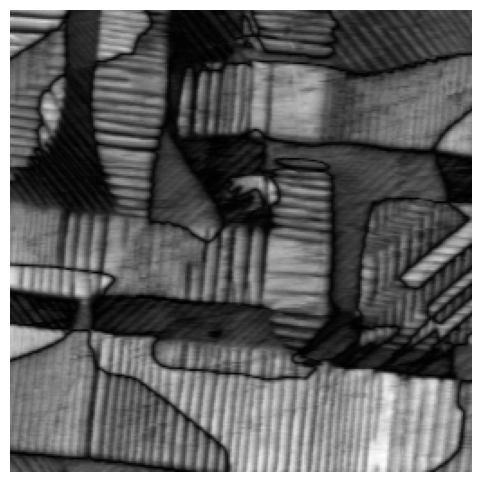

In [ ]:
channel_index = 2 #--> we want amplitude

img = img_data[channel_index].T
img = (img - img.min()) / (img.max() - img.min())

plt.figure(figsize=(6, 6))

plt.imshow(
    img,
    cmap="gray"
)

plt.axis("off")
plt.show()

Each trace contains multiple decision steps.

For every step:

- `patches` contains all candidate image patches available to the agent.
- `selected_candidate` gives the candidate selected by the agent.
- `selected_patch` contains the selected image patch.
- `position` gives the selected location in the original AFM image.
- `score` may be available for some traces.

In [ ]:
TRACE_ID = 4
STEP = 1

trace = traces[TRACE_ID]

step_data = trace[STEP - 1]

print("Selected candidate:",
      step_data["selected_candidate"])

print("Position:",
      step_data["position"])

print("Number of candidates:",
      len(step_data["patches"]))

if "score" in step_data:
    print("Score:",
          step_data["score"])

Selected candidate: 6
Position: (189, 183)
Number of candidates: 20
Score: 1.0


VISUALIZE ONE DECISION STEP

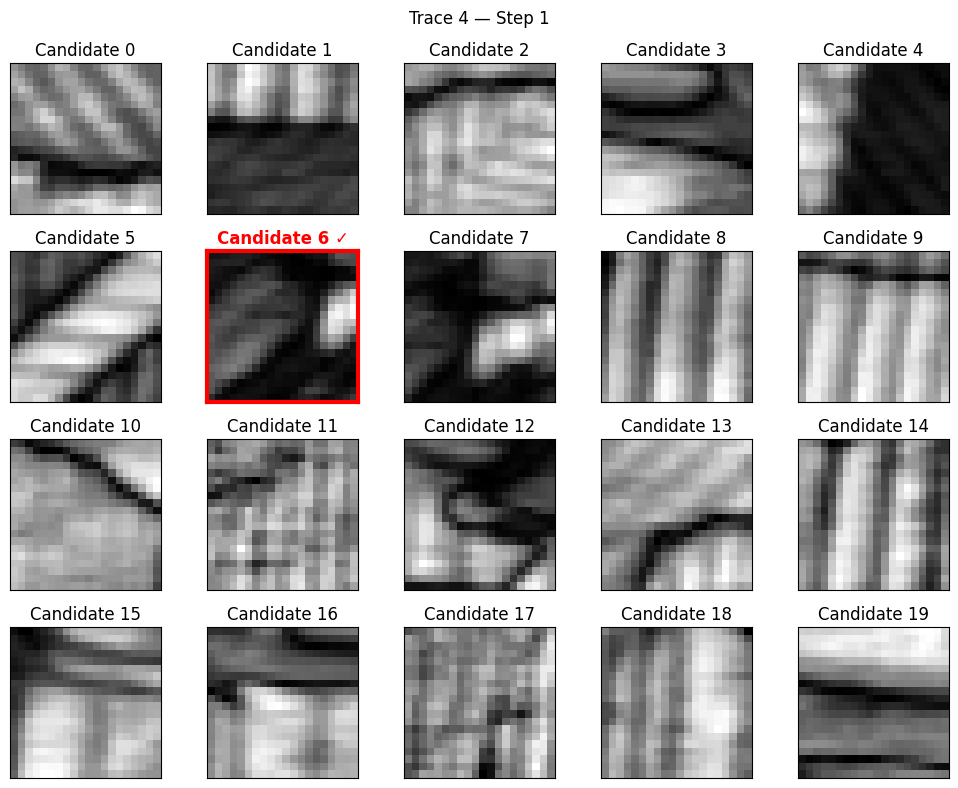

In [ ]:
patches = step_data["patches"]
selected = step_data["selected_candidate"]

n = len(patches)

ncols = 5
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(10, 2 * nrows)
)

axes = np.array(axes).reshape(-1)

for i, ax in enumerate(axes):

    if i >= n:
        ax.axis("off")
        continue

    ax.imshow(
        patches[i],
        cmap="gray"
    )

    if i == selected:

        ax.set_title(
            f"Candidate {i} ✓",
            color="red",
            weight="bold"
        )

        for spine in ax.spines.values():
            spine.set_edgecolor("red")
            spine.set_linewidth(3)

    else:

        ax.set_title(
            f"Candidate {i}"
        )

    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(
    f"Trace {TRACE_ID} — Step {STEP}"
)

plt.tight_layout()
plt.show()

TRACE MAP ON ORIGINAL IMAGE

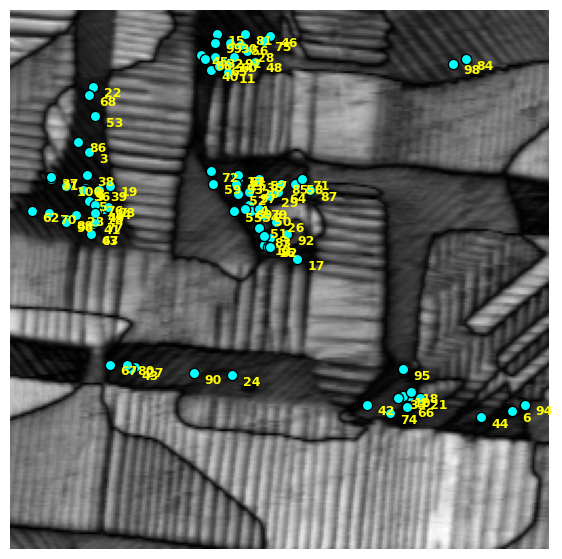

In [ ]:
trace = traces[TRACE_ID]

steps = sorted(trace.keys())

xs = [
    trace[step]["position"][0]
    for step in steps
]

ys = [
    trace[step]["position"][1]
    for step in steps
]


fig, ax = plt.subplots(
    figsize=(7, 7)
)

ax.imshow(
    img,
    cmap="gray"
)


# ------------------------------------------------------------
# Plot all selected locations
# ------------------------------------------------------------

ax.scatter(
    xs,
    ys,
    s=55,
    color="cyan",
    edgecolors="black"
)


# ------------------------------------------------------------
# Label each point by decision step
# ------------------------------------------------------------

for step, x, y in zip(
    steps,
    xs,
    ys
):

    ax.text(
        x + 5,
        y + 5,
        str(step + 1),
        fontsize=9,
        color="yellow",
        weight="bold"
    )


ax.axis("off")

plt.show()

DECISION MAPS FOR 10 TRACES

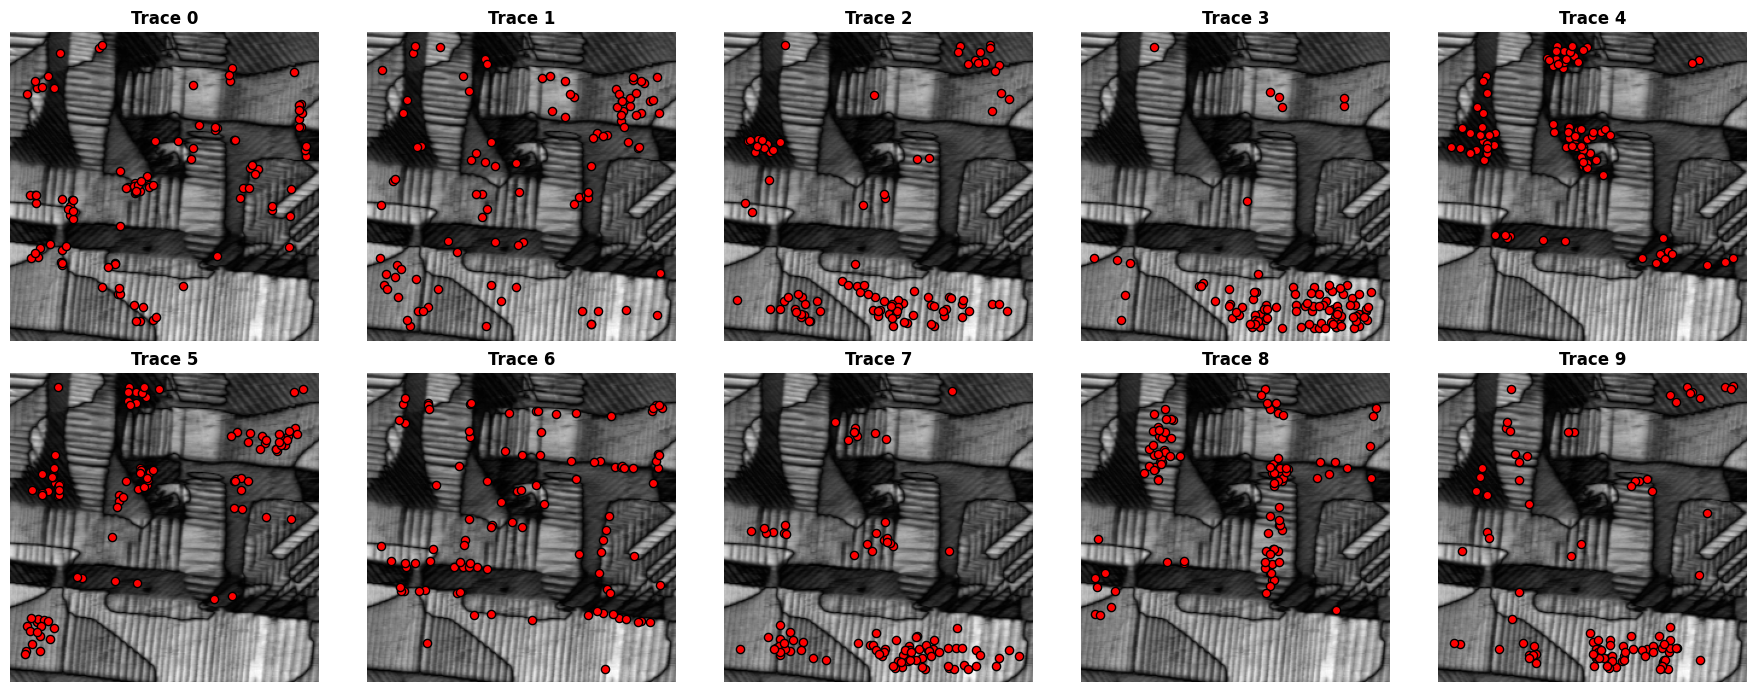

In [ ]:
TRACE_IDS = list(traces.keys())[:10]

fig, axes = plt.subplots(
    2,
    5,
    figsize=(18, 7)
)

axes = axes.flatten()


for ax, trace_id in zip(axes, TRACE_IDS):

    trace = traces[trace_id]

    steps = sorted(trace.keys())

    xs = [
        trace[step]["position"][0]
        for step in steps
    ]

    ys = [
        trace[step]["position"][1]
        for step in steps
    ]


    # Original AFM image
    ax.imshow(
        img,
        cmap="gray"
    )


    # Selected locations
    ax.scatter(
        xs,
        ys,
        s=35,
        color="r",
        edgecolors="black"
    )

    ax.set_title(
        f"Trace {trace_id}",
        fontsize=12,
        weight="bold"
    )

    ax.axis("off")


plt.tight_layout()
plt.show()

# Analysis roadmap and interpretation contract

| Part | What is fitted or displayed | Where it is used |
|---|---|---|
| Representation | 29 available handcrafted descriptors and an optional learned-kernel block | Shared input to each model within a dataset |
| Stationary choice | A single coefficient vector | Baseline prediction, coefficients, bootstrap stability, margins |
| Discrete HMM | K fixed reward functions plus Markov transitions | State definitions, posterior/Viterbi paths, state maps and variance |
| Continuous MAP | A smooth path of coefficient vectors | A separate model with changing preferences, not HMM states |
| Prospective evaluation | Predictions made before each held-out choice | NLL, rank, top-1/top-3, calibration, cumulative gain |
| Descriptive refit | Optional refit on all observations after evaluation | Offline interpretation and dense deployment maps |

For candidates $X_t = \{x_{t,1},\ldots,x_{t,M_t}\}$ and selected index $a_t$, the common observation model is

$$p(a_t=j\mid X_t,z_t=k)=\frac{\exp(w_k^\top h(x_{t,j}))}{\sum_{l=1}^{M_t}\exp(w_k^\top h(x_{t,l}))}.$$

A fixed HMM state has a fixed $w_k$. Its posterior probability changes over time. In the separate continuous
model, $w_t$ itself changes. Plotting these in different figures avoids implying they are the same latent variable.

### Disclosed changes from the compressed version

The edge-density threshold is now fixed across patches, rather than forcing approximately 15 percent in each patch.
The HMM update uses a consistent **summed** choice-loss objective plus explicit penalties. Its ridge setting is
therefore not numerically interchangeable with an earlier **averaged** objective. K comparisons use an inner
chronological validation set, rather than selecting on the final test. Optional continuous online MAP tracking
is distinguished from a frozen forecast. Descriptive full-trace refits are separated from predictive fits.
The map belief is propagated one transition beyond the last observed choice for **next-decision** maps.
None of these changes turn the frozen learned-kernel approximation into a GP posterior.

# 1. Validated traces and four composite sequences

Every original trace is retained. Each composite appends two configured source
traces without reordering decisions. The join is metadata for plotting only.
A source change is not proof of a cognitive-state change. Source identity and
source-decision index are retained so duplicated decisions cannot be counted as
independent held-out observations.

In [ ]:
import copy
import hashlib
import json
import math
import time
import traceback
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.ndimage import binary_erosion
from scipy.ndimage import gaussian_filter
from scipy.ndimage import label
from scipy.ndimage import laplace
from scipy.ndimage import sobel
from scipy.optimize import linear_sum_assignment
from scipy.optimize import minimize
from scipy.spatial.distance import pdist
from scipy.stats import kurtosis
from scipy.stats import rankdata
from scipy.stats import skew
from scipy.stats import spearmanr
from scipy.special import logsumexp
from scipy.special import softmax
from sklearn.decomposition import PCA
from sklearn.kernel_approximation import Nystroem
from sklearn.preprocessing import StandardScaler

OUT = Path(CONFIG["output_dir"]) / CONFIG["feature_mode"]
OUT.mkdir(parents=True, exist_ok=True)


def stable_seed(text):
    digest = hashlib.sha256(str(text).encode("utf-8")).hexdigest()
    return (CONFIG["seed"] + int(digest[:8], 16)) % (2**31 - 1)


def clean_patch(patch):
    array = np.asarray(patch, dtype=float).squeeze()
    if array.ndim != 2 or min(array.shape) < 3:
        raise ValueError(f"Expected a 2D patch at least 3x3, received {array.shape}")
    finite = np.isfinite(array)
    if not finite.any():
        raise ValueError("Patch has no finite measurements")
    replacement = np.median(array[finite])
    return np.where(finite, array, replacement)


def normalize_trace(trace, source_id):
    keys = sorted(trace) if isinstance(trace, dict) else range(len(trace))
    records = []
    for ordinal, key in enumerate(keys):
        record = trace[key]
        patches = [clean_patch(patch) for patch in record["patches"]]
        chosen = int(record["selected_candidate"])
        if len(patches) < 2 or not 0 <= chosen < len(patches):
            raise ValueError(f"Invalid choice in trace {source_id}, decision {key}")
        position = record.get("position")
        if position is not None:
            position = np.asarray(position, dtype=float).ravel()
            if len(position) < 2 or not np.isfinite(position[:2]).all():
                position = None
            else:
                position = position[:2].copy()
                if CONFIG["position_order"] == "yx":
                    position = position[::-1].copy()
        records.append({
            "patches": patches,
            "selected": chosen,
            "position": position,
            "source_id": source_id,
            "source_step": ordinal,
            "source_key": str(key),
            "uid": f"{source_id}:{key}",
        })
    if len(records) < 12:
        raise ValueError(f"Trace {source_id} has fewer than 12 decisions")
    return records


def build_datasets(source_traces):
    originals = {}
    for source_id in sorted(source_traces):
        originals[source_id] = normalize_trace(source_traces[source_id], source_id)
    datasets = {}
    for source_id, records in originals.items():
        name = f"original_{source_id}"
        datasets[name] = {
            "name": name,
            "kind": "original",
            "sources": (source_id,),
            "records": records,
            "boundary": None,
        }
    for index, pair in enumerate(CONFIG["trace_pairs"]):
        if len(pair) != 2:
            raise ValueError("Every composite must specify exactly two source IDs")
        first, second = pair
        if first not in originals or second not in originals:
            raise KeyError(f"Unknown pair {pair}. Available IDs: {list(originals)}")
        left = originals[first]
        right = originals[second]
        name = f"composite_{index}"
        datasets[name] = {
            "name": name,
            "kind": "composite",
            "sources": tuple(pair),
            "records": left + right,
            "boundary": len(left),
        }
    return datasets

# 2. Configurable image representation

**Three feature modes, the same downstream choice models:**
`descriptors` uses interpretable image summaries, `dkl` uses the frozen
autoencoder/Nyström feature block retained from the preceding notebook, and
`combined` concatenates the two. The `dkl` label is retained for compatibility:
it is **not** a jointly trained GP preference posterior and supplies no GP
uncertainty. The representation is fitted independently for each dataset.

## 2.1 Descriptor definitions and a disclosed correction

The original 16 descriptors and the 13 additions are retained. In this revision,
`edge_density` is the fraction of standardized-image gradient magnitudes above
a **fixed configurable threshold**, rather than each patch's own 85th percentile.
The previous definition was almost constant at 15 percent. All other definitions
remain the same. Component densities depend on the stated threshold and pixel
scale. `feature_novelty` is a fixed training-reference distance, not novelty
relative to the previously selected sequence. No causal meaning is inferred
from coefficient signs.

In [ ]:
DESCRIPTOR_GROUPS = {
    "original": [
        "mean", "std", "p05", "p95", "contrast", "skew", "kurtosis",
        "gradient_mean", "gradient_std", "gradient_energy", "laplacian_abs",
        "entropy", "high_frequency", "anisotropy", "corr_x", "corr_y",
    ],
    "quality": ["coherence", "laplacian_rms", "low_frequency"],
    "morphology": ["edge_density", "bright_fraction", "mean_feature_area"],
    "spatial": ["autocorr2", "spectral_peak", "clustering"],
    "topology": ["n_bright_components", "n_dark_components", "boundary_density"],
    "novelty": ["feature_novelty"],
}
BASE_NAMES = [
    name
    for group, names in DESCRIPTOR_GROUPS.items()
    if group != "novelty"
    for name in names
]
DESCRIPTOR_DEFINITIONS = [
    "Mean of raw patch",
    "Standard deviation of raw patch",
    "5th percentile of raw patch",
    "95th percentile of raw patch",
    "95th minus 5th percentile",
    "Skewness of raw intensity distribution",
    "Excess kurtosis of raw intensity distribution",
    "Mean Sobel gradient magnitude of standardized patch",
    "Standard deviation of gradient magnitude",
    "Mean squared gradient magnitude",
    "Mean absolute Laplacian of standardized patch",
    "32-bin entropy on standardized range [-4, 4], divided by log(32)",
    "Fraction of Fourier power at radial frequency > 0.25 cycles/pixel",
    "Mean absolute x gradient minus mean absolute y gradient",
    "Mean standardized pixel product at horizontal lag 1",
    "Mean standardized pixel product at vertical lag 1",
    "Patch-averaged gradient structure-tensor coherence",
    "RMS Laplacian of standardized patch",
    "Fourier power fraction at 0 < radial frequency < 0.1",
    "Fraction of gradient magnitudes above CONFIG edge_gradient_threshold",
    "Fraction of standardized pixels > 0.5",
    "Mean bright-component area divided by patch area",
    "Mean standardized pixel product at horizontal lag 2",
    "Maximum / total Fourier power in radial frequency > 0.03",
    "Variance of a Gaussian-smoothed bright mask",
    "Bright connected-component count divided by patch area",
    "Dark connected-component count divided by patch area",
    "Bright-mask boundary pixel fraction after binary erosion",
    "RMS standardized distance from training centroid in all 28 base descriptors",
]
ALL_DESCRIPTOR_NAMES = BASE_NAMES + ["feature_novelty"]
DESCRIPTOR_TABLE = pd.DataFrame({
    "descriptor": ALL_DESCRIPTOR_NAMES,
    "definition": DESCRIPTOR_DEFINITIONS,
})
FEATURE_CACHE = {}
DENSE_CACHE = {}


def descriptor_vector(patch):
    array = clean_patch(patch)
    key = hashlib.blake2b(array.tobytes(), digest_size=16).hexdigest()
    key = (key, array.shape, CONFIG["edge_gradient_threshold"])
    if key in FEATURE_CACHE:
        return FEATURE_CACHE[key]
    mean = array.mean()
    std = array.std()
    standardized = (array - mean) / (std + 1e-8)
    gradient_x = sobel(standardized, axis=1) / 8
    gradient_y = sobel(standardized, axis=0) / 8
    magnitude = np.hypot(gradient_x, gradient_y)
    laplacian = laplace(standardized)
    power = np.abs(np.fft.fftshift(np.fft.fft2(standardized))) ** 2
    freq_y = np.fft.fftshift(np.fft.fftfreq(array.shape[0]))[:, None]
    freq_x = np.fft.fftshift(np.fft.fftfreq(array.shape[1]))[None, :]
    radius = np.hypot(freq_x, freq_y)
    total_power = power.sum() + 1e-9
    counts = np.histogram(standardized, bins=32, range=(-4, 4))[0]
    probabilities = counts[counts > 0] / max(counts.sum(), 1)
    entropy = -np.sum(probabilities * np.log(probabilities)) / np.log(32)
    coherence = np.hypot(
        np.mean(gradient_x**2 - gradient_y**2),
        2 * np.mean(gradient_x * gradient_y),
    )
    coherence /= np.mean(gradient_x**2 + gradient_y**2) + 1e-8
    bright = standardized > 0.5
    dark = standardized < -0.5
    bright_labels, bright_count = label(bright)
    _, dark_count = label(dark)
    areas = np.bincount(bright_labels.ravel())[1:]
    noncentral_power = power[radius > 0.03]
    spectral_peak = 0.0
    if noncentral_power.size:
        spectral_peak = noncentral_power.max() / (noncentral_power.sum() + 1e-8)
    smoothed_mask = gaussian_filter(
        bright.astype(float),
        max(1, min(array.shape) / 10),
    )
    result = np.array([
        mean,
        std,
        np.percentile(array, 5),
        np.percentile(array, 95),
        np.percentile(array, 95) - np.percentile(array, 5),
        skew(array.ravel()) if std > 1e-8 else 0.0,
        kurtosis(array.ravel()) if std > 1e-8 else 0.0,
        magnitude.mean(),
        magnitude.std(),
        np.mean(magnitude**2),
        np.mean(np.abs(laplacian)),
        entropy,
        power[radius > 0.25].sum() / total_power,
        np.abs(gradient_x).mean() - np.abs(gradient_y).mean(),
        np.mean(standardized[:, :-1] * standardized[:, 1:]),
        np.mean(standardized[:-1] * standardized[1:]),
        coherence,
        np.sqrt(np.mean(laplacian**2)),
        power[(radius > 0) & (radius < 0.1)].sum() / total_power,
        np.mean(magnitude > CONFIG["edge_gradient_threshold"]),
        bright.mean(),
        areas.mean() / array.size if areas.size else 0.0,
        np.mean(standardized[:, :-2] * standardized[:, 2:]),
        spectral_peak,
        np.var(smoothed_mask),
        bright_count / array.size,
        dark_count / array.size,
        np.logical_xor(bright, binary_erosion(bright)).mean(),
    ], dtype=float)
    result = np.nan_to_num(result)
    FEATURE_CACHE[key] = result
    return result

## 2.2 Frozen learned-kernel block

A small convolutional autoencoder is fitted on training candidate patches only.
Each patch is standardized, clipped, and resized to 32 x 32. Eight latent
coordinates are standardized and mapped into an RBF Nyström basis. The defaults
give 12 kernel coordinates. Kernel coefficients have no standalone physical
meaning. Visual prototypes and full reward maps are used to interpret their
combined effect. This block is optional and imports PyTorch only when requested.

In [ ]:
def fit_deep_kernel(patches, seed):
    import torch
    import torch.nn as nn
    import torch.nn.functional as functional

    torch.manual_seed(seed)
    torch.set_num_threads(CONFIG["torch_threads"])
    device = "cuda" if torch.cuda.is_available() and CONFIG["use_gpu"] else "cpu"
    rng = np.random.default_rng(seed)
    count = min(len(patches), CONFIG["max_encoder_patches"])
    indices = rng.choice(len(patches), count, replace=False)

    def tensor_batch(batch):
        resized = []
        for patch in batch:
            array = clean_patch(patch)
            array = (array - array.mean()) / (array.std() + 1e-6)
            array = np.clip(array, -4, 4) / 4
            tensor = torch.tensor(array, dtype=torch.float32)[None, None]
            tensor = functional.interpolate(
                tensor,
                size=(32, 32),
                mode="bilinear",
                align_corners=False,
            )
            resized.append(tensor[0])
        return torch.stack(resized).to(device)

    class PatchAutoencoder(nn.Module):
        def __init__(self, dimension):
            super().__init__()
            self.encoder = nn.Sequential(
                nn.Conv2d(1, 8, 3, 2, 1),
                nn.ReLU(),
                nn.Conv2d(8, 16, 3, 2, 1),
                nn.ReLU(),
                nn.Flatten(),
                nn.Linear(16 * 8 * 8, dimension),
            )
            self.decoder = nn.Sequential(
                nn.Linear(dimension, 16 * 8 * 8),
                nn.ReLU(),
                nn.Unflatten(1, (16, 8, 8)),
                nn.Upsample(scale_factor=2),
                nn.Conv2d(16, 8, 3, padding=1),
                nn.ReLU(),
                nn.Upsample(scale_factor=2),
                nn.Conv2d(8, 1, 3, padding=1),
            )

        def forward(self, tensor):
            latent = self.encoder(tensor)
            return self.decoder(latent), latent

    network = PatchAutoencoder(CONFIG["embedding_dim"]).to(device)
    optimizer = torch.optim.Adam(network.parameters(), lr=0.002)
    tensor = tensor_batch([patches[index] for index in indices])
    history = []
    for epoch in range(CONFIG["encoder_epochs"]):
        network.train()
        total = 0.0
        permutation = torch.randperm(len(tensor), device=device)
        for batch_indices in permutation.split(128):
            reconstruction, _ = network(tensor[batch_indices])
            loss = functional.mse_loss(reconstruction, tensor[batch_indices])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(batch_indices)
        history.append(total / len(tensor))
    network.eval()

    def embed(batch):
        outputs = []
        with torch.no_grad():
            for start in range(0, len(batch), 128):
                _, latent = network(tensor_batch(batch[start:start + 128]))
                outputs.append(latent.cpu().numpy())
        return np.concatenate(outputs, axis=0)

    training_latent = embed([patches[index] for index in indices])
    scaler = StandardScaler().fit(training_latent)
    standardized = scaler.transform(training_latent)
    distances = pdist(standardized[:min(500, len(standardized))], metric="sqeuclidean")
    nonzero = distances[distances > 1e-9]
    gamma = 1 / np.median(nonzero) if nonzero.size else 1.0
    kernel = Nystroem(
        kernel="rbf",
        gamma=gamma,
        n_components=min(CONFIG["kernel_dim"], len(standardized)),
        random_state=seed,
    )
    kernel.fit(standardized)

    def transform(batch):
        return kernel.transform(scaler.transform(embed(batch)))

    return {
        "transform": transform,
        "network": network,
        "embedding_scaler": scaler,
        "kernel": kernel,
        "history": history,
        "dimension": kernel.components_.shape[0],
        "training_patch_count": count,
    }

## 2.3 Splits, scaling, feature caching, and provenance

The outer split reserves the final configured fraction for prospective scoring.
An inner chronological split selects K without consulting the outer test labels.
Representation learning and scaling use only the inner training prefix so that
even the inner validation images do not determine the learned representation.
The final predictive models use the outer training prefix. If a source decision
repeats in an appended sequence, only its first unseen test occurrence counts
toward generalization metrics. Repeated observations remain in the chronological
filtering sequence and are explicitly marked in the exported table.

In [ ]:
def prepare_dataset(info):
    records = info["records"]
    total = len(records)
    cut = int(total * CONFIG["train_fraction"])
    cut = min(total - 2, max(8, cut))
    inner_cut = int(cut * (1 - CONFIG["validation_fraction"]))
    inner_cut = min(cut - 2, max(6, inner_cut))
    shapes = {patch.shape for record in records for patch in record["patches"]}
    if len(shapes) != 1:
        raise ValueError(f"Mixed patch geometries in {info['name']}: {shapes}")
    patch_shape = next(iter(shapes))
    training_patches = [
        patch
        for record in records[:inner_cut]
        for patch in record["patches"]
    ]
    selected_names = [
        name
        for group in CONFIG["descriptor_groups"]
        for name in DESCRIPTOR_GROUPS[group]
    ]
    base_scaler = StandardScaler().fit(
        np.stack([descriptor_vector(patch) for patch in training_patches])
    )
    deep = None
    if CONFIG["feature_mode"] in ("dkl", "combined"):
        deep = fit_deep_kernel(training_patches, stable_seed(info["name"]))

    def raw_features(patches):
        blocks = []
        if CONFIG["feature_mode"] in ("descriptors", "combined"):
            base = np.stack([descriptor_vector(patch) for patch in patches])
            novelty = np.linalg.norm(base_scaler.transform(base), axis=1)
            novelty /= np.sqrt(len(BASE_NAMES))
            all_values = np.column_stack([base, novelty])
            indices = [ALL_DESCRIPTOR_NAMES.index(name) for name in selected_names]
            blocks.append(all_values[:, indices])
        if deep is not None:
            blocks.append(deep["transform"](patches))
        if not blocks:
            raise ValueError("At least one feature group must be enabled")
        return np.concatenate(blocks, axis=1)

    flattened = [patch for record in records for patch in record["patches"]]
    raw = raw_features(flattened)
    counts = [len(record["patches"]) for record in records]
    representation_rows = sum(counts[:inner_cut])
    feature_scaler = StandardScaler().fit(raw[:representation_rows])
    standardized = feature_scaler.transform(raw)
    groups = []
    offset = 0
    for count in counts:
        groups.append(standardized[offset:offset + count])
        offset += count
    names = []
    if CONFIG["feature_mode"] in ("descriptors", "combined"):
        names.extend(selected_names)
    if deep is not None:
        names.extend([f"DKL_kernel_{index}" for index in range(deep["dimension"])])
    seen = {record["uid"] for record in records[:cut]}
    eligible = np.zeros(total, dtype=bool)
    for index in range(cut, total):
        uid = records[index]["uid"]
        eligible[index] = uid not in seen
        seen.add(uid)
    labels = np.array([record["selected"] for record in records], dtype=int)
    result = dict(info)
    result.update({
        "X": groups,
        "y": labels,
        "cut": cut,
        "inner_cut": inner_cut,
        "eligible_test": eligible,
        "names": names,
        "patch_shape": patch_shape,
        "raw_features": raw_features,
        "scaler": feature_scaler,
        "deep_kernel": deep,
    })
    return result

# 3. Stationary preference model

A candidate receives utility R(x) = w^T h(x). A single choice set contributes
log p(a | X) = R(x_a) - log(sum_j exp(R(x_j))). No artificial 0/1 regression
labels are assigned to rejected images. L2 regularization constrains the fitted
coefficients. Coefficients are associations conditional on this representation,
not demonstrated physical or psychological causes.

In [ ]:
def pack_choices(groups, labels):
    count = len(groups)
    dimension = groups[0].shape[1]
    maximum = max(len(group) for group in groups)
    tensor = np.zeros((count, maximum, dimension))
    mask = np.zeros((count, maximum), dtype=bool)
    for index, group in enumerate(groups):
        tensor[index, :len(group)] = group
        mask[index, :len(group)] = True
    return tensor, mask, np.asarray(labels, dtype=int)


def logistic_objective(weights, packed, sample_weights, ridge, anchor=None):
    tensor, mask, labels = packed
    logits = np.einsum("tmd,d->tm", tensor, weights)
    logits = np.where(mask, logits, -np.inf)
    probabilities = softmax(logits, axis=1)
    chosen_features = tensor[np.arange(len(labels)), labels]
    losses = logsumexp(logits, axis=1) - logits[np.arange(len(labels)), labels]
    gradient_rows = np.einsum("tm,tmd->td", probabilities, tensor) - chosen_features
    anchor = np.zeros_like(weights) if anchor is None else anchor
    difference = weights - anchor
    loss = np.dot(sample_weights, losses) + 0.5 * ridge * np.dot(difference, difference)
    gradient = sample_weights @ gradient_rows + ridge * difference
    return float(loss), gradient


def fit_choice(groups, labels, sample_weights=None, start=None, ridge=None, anchor=None):
    packed = pack_choices(groups, labels)
    dimension = groups[0].shape[1]
    if sample_weights is None:
        sample_weights = np.ones(len(groups))
    if start is None:
        start = np.zeros(dimension)
    if ridge is None:
        ridge = CONFIG["choice_ridge"]
    history = []

    def objective(weights):
        return logistic_objective(weights, packed, sample_weights, ridge, anchor)

    def callback(weights):
        history.append(objective(weights)[0])

    solution = minimize(
        objective,
        start,
        jac=True,
        method="L-BFGS-B",
        callback=callback,
        options={"maxiter": CONFIG["optimizer_iterations"], "ftol": 1e-9},
    )
    if not np.isfinite(solution.x).all():
        raise FloatingPointError("Nonfinite stationary fit")
    return {
        "weights": solution.x,
        "history": history,
        "converged": bool(solution.success),
        "message": str(solution.message),
        "objective": float(solution.fun),
    }

# 4. Discrete HMM preference model

The HMM has K fixed preference vectors, a transition matrix A, and an initial
distribution pi. Its emission probability is the softmax probability of the
observed selected candidate conditional on each state. Forward-backward computes
the marginal likelihood and posterior state probabilities. Viterbi gives one
most probable complete trajectory, not the pointwise posterior maximum.

Generalized EM alternates these state responsibilities with weighted choice fits.
A modest persistence prior and multiple random restarts are explicit. The plotted
penalized objective, not necessarily the unpenalized likelihood, is optimized.
K=1 uses A=[1] exactly. Redundant states are diagnosed rather than forced apart.

In [ ]:
def emission_logs(groups, labels, weights):
    tensor, mask, chosen = pack_choices(groups, labels)
    logits = np.einsum("tmd,kd->tmk", tensor, weights)
    logits = np.where(mask[:, :, None], logits, -np.inf)
    selected = logits[np.arange(len(chosen)), chosen]
    return selected - logsumexp(logits, axis=1)


def forward_backward(emissions, transition, initial):
    count, states = emissions.shape
    log_transition = np.log(np.clip(transition, 1e-300, 1))
    forward = np.empty_like(emissions)
    backward = np.zeros_like(emissions)
    forward[0] = np.log(np.clip(initial, 1e-300, 1)) + emissions[0]
    for index in range(1, count):
        forward[index] = emissions[index] + logsumexp(
            forward[index - 1, :, None] + log_transition,
            axis=0,
        )
    log_likelihood = logsumexp(forward[-1])
    for index in range(count - 2, -1, -1):
        backward[index] = logsumexp(
            log_transition + emissions[index + 1][None, :] + backward[index + 1][None, :],
            axis=1,
        )
    gamma = softmax(forward + backward, axis=1)
    xi_sum = np.zeros((states, states))
    switch_probability = np.zeros(count)
    for index in range(count - 1):
        log_xi = (
            forward[index, :, None]
            + log_transition
            + emissions[index + 1][None, :]
            + backward[index + 1][None, :]
        )
        xi = np.exp(log_xi - logsumexp(log_xi))
        xi_sum += xi
        switch_probability[index + 1] = 1 - np.trace(xi)
    return float(log_likelihood), gamma, xi_sum, switch_probability


def viterbi_path(emissions, transition, initial):
    count, states = emissions.shape
    log_transition = np.log(np.clip(transition, 1e-300, 1))
    delta = np.empty_like(emissions)
    pointers = np.zeros((count, states), dtype=int)
    delta[0] = np.log(np.clip(initial, 1e-300, 1)) + emissions[0]
    for index in range(1, count):
        candidates = delta[index - 1, :, None] + log_transition
        pointers[index] = candidates.argmax(axis=0)
        delta[index] = emissions[index] + candidates.max(axis=0)
    path = np.zeros(count, dtype=int)
    path[-1] = delta[-1].argmax()
    for index in range(count - 2, -1, -1):
        path[index] = pointers[index + 1, path[index + 1]]
    return path


def hmm_penalty(weights, transition, initial, transition_counts, initial_counts):
    penalty = 0.5 * CONFIG["choice_ridge"] * np.sum(weights**2)
    penalty -= np.sum(transition_counts * np.log(np.clip(transition, 1e-300, 1)))
    penalty -= np.sum(initial_counts * np.log(np.clip(initial, 1e-300, 1)))
    return penalty


def fit_hmm(groups, labels, states, seed, base=None):
    if states < 1 or not isinstance(states, (int, np.integer)):
        raise ValueError("K must be a positive integer")
    if base is None:
        base = fit_choice(groups, labels)["weights"]
    rng = np.random.default_rng(seed)
    transition_counts = np.full((states, states), CONFIG["transition_pseudocount"])
    transition_counts += np.eye(states) * CONFIG["sticky_pseudocount"]
    initial_counts = np.full(states, CONFIG["initial_pseudocount"])
    runs = []
    number_restarts = 1 if states == 1 else CONFIG["hmm_restarts"]
    for restart in range(number_restarts):
        weights = np.tile(base, (states, 1))
        if states > 1:
            weights += rng.normal(0, CONFIG["state_init_scale"], weights.shape)
            transition = np.full((states, states), 0.1 / (states - 1))
            np.fill_diagonal(transition, 0.9)
        else:
            transition = np.ones((1, 1))
        initial = np.full(states, 1 / states)
        history = []
        converged_subfits = True
        for iteration in range(CONFIG["hmm_iterations"]):
            emissions = emission_logs(groups, labels, weights)
            likelihood, gamma, xi_sum, switches = forward_backward(emissions, transition, initial)
            objective = likelihood - hmm_penalty(
                weights, transition, initial, transition_counts, initial_counts,
            )
            history.append({"iteration": iteration, "log_likelihood": likelihood, "objective": objective})
            if len(history) > 2:
                difference = abs(history[-1]["objective"] - history[-2]["objective"])
                if difference < CONFIG["hmm_tolerance"]:
                    break
            counts = xi_sum + transition_counts
            transition = counts / counts.sum(axis=1, keepdims=True)
            initial = gamma[0] + initial_counts
            initial /= initial.sum()
            updated = []
            for state in range(states):
                fitted = fit_choice(
                    groups,
                    labels,
                    sample_weights=gamma[:, state],
                    start=weights[state],
                )
                updated.append(fitted["weights"])
                converged_subfits = converged_subfits and fitted["converged"]
            weights = np.stack(updated)
        emissions = emission_logs(groups, labels, weights)
        likelihood, gamma, xi_sum, switches = forward_backward(emissions, transition, initial)
        objective = likelihood - hmm_penalty(
            weights, transition, initial, transition_counts, initial_counts,
        )
        history.append({"iteration": len(history), "log_likelihood": likelihood, "objective": objective})
        path = viterbi_path(emissions, transition, initial)
        runs.append({
            "W": weights,
            "A": transition,
            "pi": initial,
            "gamma": gamma,
            "viterbi": path,
            "switch_probability": switches,
            "history": pd.DataFrame(history),
            "log_likelihood": likelihood,
            "objective": objective,
            "restart": restart,
            "subfits_converged": converged_subfits,
        })
    best = max(runs, key=lambda run: run["objective"])
    best["restarts"] = pd.DataFrame([
        {
            "restart": run["restart"],
            "log_likelihood": run["log_likelihood"],
            "objective": run["objective"],
            "subfits_converged": run["subfits_converged"],
        }
        for run in runs
    ])
    best["restart_weights"] = [run["W"] for run in runs]
    return best

# 5. Continuous preference model — independent of the HMM

Here the latent variable is a continuously varying coefficient vector w_t.
The objective combines choice loss, a random-walk smoothness penalty, and a weak
initial anchor to the stationary vector. There are **no discrete state labels**.
The fitted path is a MAP point estimate, not a posterior credible interval.

Two prospective evaluations are retained: a frozen terminal-training vector and
a causal local-MAP tracker. The latter predicts before observing a test choice,
then updates its vector. It is an approximate point-state tracker, not an exact
Bayesian filter. Offline smoothed trajectories are never scored as forecasts.

In [ ]:
def fit_continuous(groups, labels, base):
    tensor, mask, chosen = pack_choices(groups, labels)
    count = len(groups)
    dimension = len(base)
    initial = np.tile(base, (count, 1))
    history = []

    def objective(vector):
        path = vector.reshape(count, dimension)
        logits = np.einsum("tmd,td->tm", tensor, path)
        logits = np.where(mask, logits, -np.inf)
        probabilities = softmax(logits, axis=1)
        loss = np.sum(logsumexp(logits, axis=1) - logits[np.arange(count), chosen])
        gradient = np.einsum("tm,tmd->td", probabilities, tensor)
        gradient -= tensor[np.arange(count), chosen]
        differences = np.diff(path, axis=0)
        smooth = CONFIG["continuous_smooth"]
        loss += 0.5 * smooth * np.sum(differences**2)
        gradient[:-1] -= smooth * differences
        gradient[1:] += smooth * differences
        initial_difference = path[0] - base
        anchor = CONFIG["continuous_anchor"]
        loss += 0.5 * anchor * np.sum(initial_difference**2)
        gradient[0] += anchor * initial_difference
        return float(loss), gradient.ravel()

    def callback(vector):
        history.append(objective(vector)[0])

    solution = minimize(
        objective,
        initial.ravel(),
        jac=True,
        method="L-BFGS-B",
        callback=callback,
        options={"maxiter": CONFIG["continuous_iterations"], "ftol": 1e-9},
    )
    return {
        "path": solution.x.reshape(count, dimension),
        "history": history,
        "converged": bool(solution.success),
        "message": str(solution.message),
    }


def update_continuous(previous, group, selected):
    updated = fit_choice(
        [group],
        [selected],
        start=previous,
        ridge=CONFIG["continuous_smooth"],
        anchor=previous,
    )
    return updated["weights"]

# 6. Prospective scoring, K selection, and descriptive refitting

**Prediction:** every held-out probability is evaluated before the corresponding
selected candidate is assimilated. The HMM uses a prior belief and the continuous
online model uses its previous point estimate. All metrics use the same eligible
decisions and include uniform-choice baselines.

**Interpretation:** after evaluation, an optional all-observation refit creates
offline state definitions, temporal trajectories, and maps for deployment.
Those descriptive refits cannot supply held-out performance claims. Their files
and figures explicitly say `descriptive`. The outer test never chooses K.

In [ ]:
def filtered_beliefs(groups, labels, hmm):
    priors = []
    posteriors = []
    posterior = hmm["pi"].copy()
    for index, (group, selected) in enumerate(zip(groups, labels)):
        prior = posterior @ hmm["A"] if index > 0 else posterior
        log_likelihood = emission_logs([group], [selected], hmm["W"])[0]
        posterior = softmax(np.log(np.clip(prior, 1e-300, 1)) + log_likelihood)
        priors.append(prior)
        posteriors.append(posterior)
    return np.stack(priors), np.stack(posteriors)


def choice_diagnostic(probabilities, selected):
    order = np.argsort(-probabilities, kind="stable")
    rank = int(np.flatnonzero(order == selected)[0] + 1)
    best_rejected = np.max(np.delete(probabilities, selected))
    log_probabilities = np.log(np.clip(probabilities, 1e-300, 1))
    log_margin = log_probabilities[selected] - np.max(np.delete(log_probabilities, selected))
    return {
        "predicted": int(order[0]),
        "selected_probability": float(probabilities[selected]),
        "rank": rank,
        "top1": int(order[0] == selected),
        "top3": int(selected in order[:min(3, len(order))]),
        "confidence": float(probabilities.max()),
        "nll": float(-log_probabilities[selected]),
        "probability_margin": float(probabilities[selected] - best_rejected),
        "log_probability_margin": float(log_margin),
    }


def evaluate_models(prepared, models):
    groups = prepared["X"]
    labels = prepared["y"]
    cut = prepared["cut"]
    hmm = models["hmm"]
    priors, posteriors = filtered_beliefs(groups[:cut], labels[:cut], hmm)
    posterior = posteriors[-1]
    online = models["continuous"]["path"][-1].copy()
    frozen = online.copy()
    rows = []
    candidates = []
    belief_rows = []
    online_rows = []
    for index in range(cut, len(groups)):
        group = groups[index]
        selected = labels[index]
        prior = posterior @ hmm["A"]
        state_probabilities = np.stack([softmax(group @ weight) for weight in hmm["W"]])
        probabilities = {
            "Stationary": softmax(group @ models["stationary"]["weights"]),
            "HMM": prior @ state_probabilities,
            "Continuous frozen": softmax(group @ frozen),
            "Continuous online MAP": softmax(group @ online),
        }
        record = prepared["records"][index]
        for name, probability in probabilities.items():
            row = {
                "step": index + 1,
                "model": name,
                "actual": int(selected),
                "candidate_count": len(group),
                "eligible": bool(prepared["eligible_test"][index]),
                "source_id": record["source_id"],
                "source_step": record["source_step"],
                "uid": record["uid"],
            }
            row.update(choice_diagnostic(probability, selected))
            rows.append(row)
            for candidate, value in enumerate(probability):
                candidates.append({
                    "step": index + 1,
                    "model": name,
                    "candidate": candidate,
                    "probability": float(value),
                    "actual": candidate == selected,
                })
        log_likelihood = emission_logs([group], [selected], hmm["W"])[0]
        posterior = softmax(np.log(np.clip(prior, 1e-300, 1)) + log_likelihood)
        belief_rows.append({
            "step": index + 1,
            **{f"prior_{state}": prior[state] for state in range(len(prior))},
            **{f"posterior_{state}": posterior[state] for state in range(len(prior))},
        })
        online_rows.append(online.copy())
        online = update_continuous(online, group, selected)
    diagnostics = pd.DataFrame(rows)
    eligible = diagnostics[diagnostics["eligible"]]
    metrics = eligible.groupby("model", sort=False).agg(
        decisions=("step", "size"),
        nll=("nll", "mean"),
        top1=("top1", "mean"),
        top3=("top3", "mean"),
        mean_rank=("rank", "mean"),
        selected_probability=("selected_probability", "mean"),
    ).reset_index()
    return {
        "diagnostics": diagnostics,
        "candidate_probabilities": pd.DataFrame(candidates),
        "beliefs": pd.DataFrame(belief_rows),
        "online_prior_path": np.stack(online_rows),
        "metrics": metrics,
    }


def compare_state_counts(prepared):
    split = prepared["inner_cut"]
    end = prepared["cut"]
    groups = prepared["X"]
    labels = prepared["y"]
    base = fit_choice(groups[:split], labels[:split])["weights"]
    rows = []
    for states in sorted(set(CONFIG["K_values"] + [CONFIG["hmm_states"]])):
        hmm = fit_hmm(groups[:split], labels[:split], states, stable_seed(f"{prepared['name']}_K{states}"), base)
        _, posterior = filtered_beliefs(groups[:split], labels[:split], hmm)
        belief = posterior[-1]
        values = []
        seen = {record["uid"] for record in prepared["records"][:split]}
        for index in range(split, end):
            prior = belief @ hmm["A"]
            probabilities = np.stack([softmax(groups[index] @ weight) for weight in hmm["W"]])
            mixture = prior @ probabilities
            uid = prepared["records"][index]["uid"]
            if uid not in seen:
                values.append(choice_diagnostic(mixture, labels[index]))
            seen.add(uid)
            likelihood = emission_logs([groups[index]], [labels[index]], hmm["W"])[0]
            belief = softmax(np.log(np.clip(prior, 1e-300, 1)) + likelihood)
        frame = pd.DataFrame(values)
        rows.append({
            "K": states,
            "validation_count": len(frame),
            "validation_nll": frame["nll"].mean() if len(frame) else np.nan,
            "validation_top1": frame["top1"].mean() if len(frame) else np.nan,
            "validation_top3": frame["top3"].mean() if len(frame) else np.nan,
            "fit_objective": hmm["objective"],
        })
    comparison = pd.DataFrame(rows)
    if CONFIG["K_selection"] == "validation":
        valid = comparison.dropna(subset=["validation_nll"])
        if valid.empty:
            raise ValueError("No nonduplicated inner-validation choices for K selection")
        selected = int(valid.sort_values(["validation_nll", "K"]).iloc[0]["K"])
    else:
        selected = CONFIG["hmm_states"]
    return comparison, selected


def fit_model_family(groups, labels, states, seed):
    stationary = fit_choice(groups, labels)
    hmm = fit_hmm(groups, labels, states, seed, stationary["weights"])
    continuous = fit_continuous(groups, labels, stationary["weights"])
    return {"stationary": stationary, "hmm": hmm, "continuous": continuous}

In [ ]:
def analyze_dataset(info):
    start = time.perf_counter()
    prepared = prepare_dataset(info)
    comparison, states = compare_state_counts(prepared)
    cut = prepared["cut"]
    predictive = fit_model_family(
        prepared["X"][:cut],
        prepared["y"][:cut],
        states,
        stable_seed(info["name"]),
    )
    evaluation = evaluate_models(prepared, predictive)
    if CONFIG["refit_all_for_descriptive_maps"]:
        descriptive = fit_model_family(
            prepared["X"],
            prepared["y"],
            states,
            stable_seed(info["name"] + "_descriptive"),
        )
        fit_count = len(prepared["y"])
        fit_label = "Descriptive refit on all observations"
    else:
        descriptive = predictive
        fit_count = cut
        fit_label = "Training-only fit"
    _, posteriors = filtered_beliefs(prepared["X"], prepared["y"], descriptive["hmm"])
    next_belief = posteriors[-1] @ descriptive["hmm"]["A"]
    result = {
        "prepared": prepared,
        "predictive": predictive,
        "descriptive": descriptive,
        "evaluation": evaluation,
        "K_comparison": comparison,
        "K": states,
        "fit_count": fit_count,
        "fit_label": fit_label,
        "next_belief": next_belief,
        "terminal_belief": posteriors[-1],
        "seconds": time.perf_counter() - start,
    }
    return result

# 7. Dense full-image maps and genuinely additional locations

The default stride reproduces the earlier detailed notebook: one quarter of the
smaller patch dimension, rounded down and bounded below by one pixel. An explicit
`map_stride` overrides it. Every map value is evaluated on an actual image patch,
not obtained by merely stretching a coarse map. Coordinate edges are computed
from the patch centers, including a possibly shorter final grid step.

The original image is shown only in the top-left panel. Recorded locations are
red. Proposed additional locations are blue. Proposals exclude a configurable
radius around recorded locations and around already proposed points. If 40
feasible points do not exist, the report says so instead of relaxing constraints.
These are a ranked spatially separated batch, not simulated future observations.

## Between-state utility variance is a required condensed output

For state maps R_k and next-step belief b, the mean is sum_k b_k R_k and the
variance is sum_k b_k (R_k - mean)^2. The variance can be small because the maps
agree OR because b is concentrated. We therefore also save equal-weight variance
and state-choice probability disagreement. Utility variance has squared-utility
units, is sensitive to utility scales, and is NOT GP uncertainty. State utilities
use a common zero-mean training reference but are not calibrated across traces.

The HMM choice map mixes state-conditioned softmax probabilities. It is not the
softmax of the averaged utility map. All probabilities depend on this full grid
of alternatives and need not be calibrated for a human viewing a different menu.

In [ ]:
 , window, stride):
    if window > length:
        raise ValueError("A candidate patch is larger than the parent image")
    starts = list(range(0, length - window + 1, stride))
    if starts[-1] != length - window:
        starts.append(length - window)
    return np.asarray(starts, dtype=int)


def centers_to_edges(centers, limit, singleton_width):
    centers = np.asarray(centers, dtype=float)
    if len(centers) == 1:
        edges = [centers[0] - singleton_width / 2, centers[0] + singleton_width / 2]
        return np.clip(edges, 0, limit)
    middle = (centers[:-1] + centers[1:]) / 2
    left = centers[0] - (centers[1] - centers[0]) / 2
    right = centers[-1] + (centers[-1] - centers[-2]) / 2
    return np.clip(np.r_[left, middle, right], 0, limit)


def dense_geometry(parent, patch_shape):
    height, width = parent.shape
    patch_height, patch_width = patch_shape
    stride = CONFIG["map_stride"]
    if stride is None:
        stride = max(1, min(patch_shape) // 4)
    stride = int(stride)
    if stride < 1:
        raise ValueError("Map stride must be a positive integer")
    x_starts = axis_starts(width, patch_width, stride)
    y_starts = axis_starts(height, patch_height, stride)
    count = len(x_starts) * len(y_starts)
    if count > CONFIG["max_map_patches"]:
        raise ValueError(
            f"Dense grid has {count} patches. Increase max_map_patches or map_stride explicitly."
        )
    identity = hashlib.blake2b(parent.tobytes(), digest_size=12).hexdigest()
    key = (identity, patch_shape, stride)
    if key not in DENSE_CACHE:
        patches = [
            parent[y:y + patch_height, x:x + patch_width]
            for y in y_starts
            for x in x_starts
        ]
        DENSE_CACHE[key] = patches
    center_x = x_starts.astype(float) + patch_width / 2
    center_y = y_starts.astype(float) + patch_height / 2
    mesh_x, mesh_y = np.meshgrid(center_x, center_y)
    return {
        "patches": DENSE_CACHE[key],
        "grid_x": center_x,
        "grid_y": center_y,
        "edge_x": centers_to_edges(center_x, width, patch_width),
        "edge_y": centers_to_edges(center_y, height, patch_height),
        "starts_x": x_starts,
        "starts_y": y_starts,
        "centers": np.column_stack([mesh_x.ravel(), mesh_y.ravel()]),
        "shape": (len(center_y), len(center_x)),
        "stride": stride,
    }


def snapshot_indices(count, boundary):
    indices = {0, count // 2, count - 1}
    if boundary is not None:
        indices.add(max(0, min(count - 1, boundary - 1)))
        indices.add(max(0, min(count - 1, boundary)))
    return np.asarray(sorted(indices), dtype=int)


def calculate_spatial_maps(result, parent):
    prepared = result["prepared"]
    geometry = dense_geometry(parent, prepared["patch_shape"])
    transformed = []
    chunk_size = CONFIG["map_chunk_size"]
    for start in range(0, len(geometry["patches"]), chunk_size):
        patches = geometry["patches"][start:start + chunk_size]
        raw = prepared["raw_features"](patches)
        transformed.append(prepared["scaler"].transform(raw))
    features = np.vstack(transformed)
    models = result["descriptive"]
    shape = geometry["shape"]
    state_maps = (features @ models["hmm"]["W"].T).T.reshape(-1, *shape)
    belief = result["next_belief"]
    expected = np.einsum("k,kij->ij", belief, state_maps)
    variance = np.einsum("k,kij->ij", belief, (state_maps - expected[None])**2)
    equal_variance = state_maps.var(axis=0)
    state_probabilities = softmax(state_maps.reshape(len(state_maps), -1), axis=1)
    mixture = belief @ state_probabilities
    probability_variance = np.sum(
        belief[:, None] * (state_probabilities - mixture[None])**2,
        axis=0,
    )
    log_ratio = np.log(np.clip(state_probabilities, 1e-300, 1))
    log_ratio -= np.log(np.clip(mixture[None], 1e-300, 1))
    information_map = np.sum(belief[:, None] * state_probabilities * log_ratio, axis=0)
    continuous_path = models["continuous"]["path"]
    times = snapshot_indices(len(continuous_path), prepared["boundary"])
    stationary = (features @ models["stationary"]["weights"]).reshape(shape)
    continuous = (features @ continuous_path[-1]).reshape(shape)
    maps = {
        "stationary": stationary,
        "continuous": continuous,
        "hmm_states": state_maps,
        "hmm_expected": expected,
        "between_state_utility_variance": np.maximum(variance, 0),
        "equal_weight_utility_variance": np.maximum(equal_variance, 0),
        "state_choice_probability_variance": probability_variance.reshape(shape),
        "state_information_contribution": np.maximum(information_map, 0).reshape(shape),
        "hmm_choice_probability": mixture.reshape(shape),
        "stationary_choice_probability": softmax(stationary.ravel()).reshape(shape),
        "continuous_choice_probability": softmax(continuous.ravel()).reshape(shape),
        "continuous_snapshot_steps": times + 1,
        "continuous_snapshot_maps": (features @ continuous_path[times].T).T.reshape(-1, *shape),
        "belief_next": belief,
        "belief_terminal": result["terminal_belief"],
        "grid_x": geometry["grid_x"],
        "grid_y": geometry["grid_y"],
        "edge_x": geometry["edge_x"],
        "edge_y": geometry["edge_y"],
        "patch_shape": np.asarray(prepared["patch_shape"]),
        "map_stride": np.asarray(geometry["stride"]),
    }
    result["geometry"] = geometry
    result["spatial_features"] = features
    result["maps"] = maps
    return maps


def recorded_locations(prepared, parent_shape):
    height, width = parent_shape
    rows = []
    for index, record in enumerate(prepared["records"]):
        position = record["position"]
        if position is None:
            continue
        x, y = position
        valid = 0 <= x <= width and 0 <= y <= height
        rows.append({
            "step": index + 1,
            "x": float(x),
            "y": float(y),
            "valid": valid,
            "source_id": record["source_id"],
            "source_step": record["source_step"],
        })
    return pd.DataFrame(rows, columns=["step", "x", "y", "valid", "source_id", "source_step"])

In [ ]:
def propose_additional_locations(result, parent_shape, model="HMM"):
    keys = {
        "HMM": "hmm_choice_probability",
        "Stationary": "stationary_choice_probability",
        "Continuous": "continuous_choice_probability",
    }
    scores = result["maps"][keys[model]].ravel()
    centers = result["geometry"]["centers"]
    prepared = result["prepared"]
    records = recorded_locations(prepared, parent_shape)
    measured = records.loc[records["valid"], ["x", "y"]].to_numpy(dtype=float)
    separation = CONFIG["min_proposed_separation"]
    if separation is None:
        separation = min(prepared["patch_shape"]) / 2
    exclusion = CONFIG["exclude_measured_radius"]
    if exclusion is None:
        exclusion = min(prepared["patch_shape"]) / 2
    requested = CONFIG["n_predicted_locations"]
    complete_coordinates = len(measured) == len(prepared["records"])
    if requested > 0 and not complete_coordinates:
        if CONFIG["require_all_recorded_coordinates_for_proposals"]:
            warnings.warn(
                f"{prepared['name']}: some recorded coordinates are absent or invalid. "
                "No additional locations are proposed because exclusion cannot be guaranteed."
            )
            return pd.DataFrame(columns=[
                "rank", "x", "y", "full_grid_probability",
                "distance_to_nearest_recorded", "grid_index", "model",
            ])
        warnings.warn(
            f"{prepared['name']}: proposal exclusion uses only the available coordinates."
        )
    selected = []
    for index in np.argsort(-scores, kind="stable"):
        if len(selected) >= requested:
            break
        if not np.isfinite(scores[index]):
            continue
        point = centers[index]
        if len(measured):
            distance_to_measured = np.min(np.linalg.norm(measured - point, axis=1))
            if distance_to_measured <= max(1e-9, exclusion):
                continue
        else:
            distance_to_measured = np.nan
        if selected:
            existing = np.asarray([[item["x"], item["y"]] for item in selected])
            if np.min(np.linalg.norm(existing - point, axis=1)) < separation:
                continue
        selected.append({
            "rank": len(selected) + 1,
            "x": float(point[0]),
            "y": float(point[1]),
            "full_grid_probability": float(scores[index]),
            "distance_to_nearest_recorded": float(distance_to_measured),
            "grid_index": int(index),
            "model": model,
        })
    columns = [
        "rank", "x", "y", "full_grid_probability", "distance_to_nearest_recorded",
        "grid_index", "model",
    ]
    proposals = pd.DataFrame(selected, columns=columns)
    if len(proposals) < requested:
        warnings.warn(
            f"{prepared['name']}, {model}: {len(proposals)}/{requested} additional points fit the constraints."
        )
    return proposals

# 8. Quantitative state definitions, redundancy, and temporal summaries

HMM state definitions remain fixed vectors. The state table lists signed
descriptor associations, kernel-block contribution, occupancy, expected dwell
time, and the next-decision belief. Each continuous-model snapshot has its own
coefficient definition in a **different** table. Learned-kernel coordinates are
described as a joint representation, not assigned invented physical names.

State similarity compares choice distributions on the same candidate sets using
Jensen-Shannon divergence and top-choice agreement. A label-switching-invariant
assignment also compares random restarts. High utility variance alone is not
evidence of different choices. Uniform-weight variance helps distinguish similar
maps from a near-certain state belief. State numbers are local to each trace.

In [ ]:
def signed_definition(weights, names, count=4):
    physical = [index for index, name in enumerate(names) if not name.startswith("DKL_kernel_")]
    positive = sorted(physical, key=lambda index: -weights[index])
    negative = sorted(physical, key=lambda index: weights[index])
    increases = [f"{names[index]} ({weights[index]:+.3f})" for index in positive if weights[index] > 1e-8]
    decreases = [f"{names[index]} ({weights[index]:+.3f})" for index in negative if weights[index] < -1e-8]
    kernel_indices = [index for index, name in enumerate(names) if name.startswith("DKL_kernel_")]
    kernel_norm = np.linalg.norm(weights[kernel_indices]) if kernel_indices else 0.0
    no_descriptors = "No handcrafted descriptors in this representation"
    return {
        "higher_values_favored": ", ".join(increases[:count]) if physical else no_descriptors,
        "higher_values_disfavored": ", ".join(decreases[:count]) if physical else no_descriptors,
        "kernel_coefficient_norm": float(kernel_norm),
    }


def describe_states(result):
    models = result["descriptive"]
    prepared = result["prepared"]
    names = prepared["names"]
    hmm = models["hmm"]
    rows = []
    for state, weights in enumerate(hmm["W"]):
        persistence = hmm["A"][state, state]
        dwell = np.inf if 1 - persistence < 1e-12 else 1 / (1 - persistence)
        row = {
            "state": state,
            "occupancy": float(hmm["gamma"][:, state].mean()),
            "expected_dwell_decisions": dwell,
            "next_belief": float(result["next_belief"][state]),
            "fit_scope": result["fit_label"],
        }
        row.update(signed_definition(weights, names))
        rows.append(row)
    return pd.DataFrame(rows)


def continuous_definitions(result):
    path = result["descriptive"]["continuous"]["path"]
    prepared = result["prepared"]
    indices = snapshot_indices(len(path), prepared["boundary"])
    rows = []
    for index in indices:
        row = {"decision": index + 1, "fit_scope": result["fit_label"]}
        row.update(signed_definition(path[index], prepared["names"]))
        rows.append(row)
    return pd.DataFrame(rows)


def js_divergence(first, second):
    mean = (first + second) / 2
    first_term = np.sum(first * (np.log(np.clip(first, 1e-300, 1)) - np.log(np.clip(mean, 1e-300, 1))))
    second_term = np.sum(second * (np.log(np.clip(second, 1e-300, 1)) - np.log(np.clip(mean, 1e-300, 1))))
    return max(0.0, float((first_term + second_term) / 2))


def state_similarity(result):
    prepared = result["prepared"]
    groups = prepared["X"][:result["fit_count"]]
    weights = result["descriptive"]["hmm"]["W"]
    states = len(weights)
    divergence = np.zeros((states, states))
    agreement = np.eye(states)
    rows = []
    distributions = [[softmax(group @ vector) for group in groups] for vector in weights]
    for first in range(states):
        for second in range(first + 1, states):
            values = [js_divergence(a, b) for a, b in zip(distributions[first], distributions[second])]
            matches = [int(a.argmax() == b.argmax()) for a, b in zip(distributions[first], distributions[second])]
            divergence[first, second] = np.mean(values)
            divergence[second, first] = divergence[first, second]
            agreement[first, second] = np.mean(matches)
            agreement[second, first] = agreement[first, second]
            rows.append({
                "state_i": first,
                "state_j": second,
                "mean_js_nats": np.mean(values),
                "top1_agreement": np.mean(matches),
                "weight_distance": np.linalg.norm(weights[first] - weights[second]),
                "low_js_flag": np.mean(values) < CONFIG["state_js_warning_threshold"],
            })
    columns = ["state_i", "state_j", "mean_js_nats", "top1_agreement", "weight_distance", "low_js_flag"]
    return pd.DataFrame(rows, columns=columns), divergence, agreement


def restart_alignment(result):
    hmm = result["descriptive"]["hmm"]
    groups = result["prepared"]["X"][:result["fit_count"]]
    reference = hmm["W"]
    rows = []
    for restart, weights in enumerate(hmm["restart_weights"]):
        cost = np.zeros((len(reference), len(weights)))
        for first in range(len(reference)):
            for second in range(len(weights)):
                cost[first, second] = np.mean([
                    js_divergence(softmax(group @ reference[first]), softmax(group @ weights[second]))
                    for group in groups
                ])
        first_indices, second_indices = linear_sum_assignment(cost)
        rows.append({
            "restart": restart,
            "matched_mean_js": float(cost[first_indices, second_indices].mean()),
            "assignment_to_best": str(dict(zip(first_indices.tolist(), second_indices.tolist()))),
        })
    return pd.DataFrame(rows)


def finite_spearman(first, second):
    first = np.asarray(first).ravel()
    second = np.asarray(second).ravel()
    finite = np.isfinite(first) & np.isfinite(second)
    first = first[finite]
    second = second[finite]
    if len(first) < 3 or np.ptp(first) < 1e-12 or np.ptp(second) < 1e-12:
        return np.nan
    return float(spearmanr(first, second)[0])


def coefficient_bootstrap(result):
    prepared = result["prepared"]
    groups = prepared["X"][:prepared["cut"]]
    labels = prepared["y"][:prepared["cut"]]
    base = result["predictive"]["stationary"]["weights"]
    count = len(groups)
    block = CONFIG["bootstrap_block_length"]
    if block is None:
        block = max(1, int(round(count**(1 / 3))))
    block = min(block, count)
    rng = np.random.default_rng(stable_seed(prepared["name"] + "_bootstrap"))
    samples = []
    for repeat in range(CONFIG["bootstrap_repeats"]):
        indices = []
        while len(indices) < count:
            start = rng.integers(0, count - block + 1)
            indices.extend(range(start, start + block))
        indices = np.asarray(indices[:count])
        fitted = fit_choice([groups[index] for index in indices], labels[indices], start=base)
        samples.append(fitted["weights"])
    if not samples:
        return pd.DataFrame({"feature": prepared["names"], "weight": base, "low": np.nan, "high": np.nan})
    lower, upper = np.quantile(samples, [0.025, 0.975], axis=0)
    return pd.DataFrame({
        "feature": prepared["names"],
        "weight": base,
        "low": lower,
        "high": upper,
    })

# 9. Plotting helpers and full diagnostic library

All plotting functions receive the fitted result explicitly. There is no reuse
of another trace's global state weights or coordinates. Figures adapt to K=1
and larger K. Missing correlations for constant maps remain NaN, not invented
zeros. Raw utility, probability, and variance maps receive separate colorbars.
The HMM's states share one utility scale within a trace.

In [ ]:
def make_axes(count, columns=3, panel_size=(5.0, 4.2)):
    columns = min(columns, max(1, count))
    rows = math.ceil(count / columns)
    figure, axes = plt.subplots(
        rows,
        columns,
        figsize=(columns * panel_size[0], rows * panel_size[1]),
        squeeze=False,
    )
    flattened = axes.ravel()
    for axis in flattened[count:]:
        axis.set_visible(False)
    return figure, flattened


def finish_figure(figure, folder, name, show=False):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    figure.tight_layout()
    figure.savefig(folder / name, dpi=CONFIG["figure_dpi"], bbox_inches="tight")
    if show:
        plt.show()
    plt.close(figure)


def annotate_time(axis, prepared, show_split=True):
    if show_split:
        axis.axvline(prepared["cut"] + 0.5, linestyle="--", label="Outer train/test split")
    if prepared["boundary"] is not None:
        axis.axvline(prepared["boundary"] + 0.5, linestyle=":", linewidth=2, label="Source join (not fitted)")


def color_limits(values, nonnegative=False):
    finite = np.asarray(values)[np.isfinite(values)]
    if finite.size == 0:
        return (0.0, 1.0)
    lower, upper = np.percentile(finite, CONFIG["map_color_percentiles"])
    if nonnegative:
        lower = 0.0
    if upper <= lower:
        upper = lower + max(1e-8, abs(lower) * 1e-6)
    return float(lower), float(upper)


def draw_original(axis, result, parent, proposals):
    height, width = parent.shape
    axis.imshow(parent, origin="upper", cmap="gray", extent=(0, width, height, 0))
    locations = recorded_locations(result["prepared"], parent.shape)
    valid = locations[locations["valid"]]
    if len(valid):
        axis.scatter(
            valid["x"],
            valid["y"],
            s=CONFIG["actual_marker_size"],
            facecolors="none",
            edgecolors="red",
            linewidths=1.2,
            label=f"Recorded ({len(valid)})",
        )
    if len(proposals):
        axis.scatter(
            proposals["x"],
            proposals["y"],
            s=CONFIG["proposed_marker_size"],
            marker="x",
            color="blue",
            linewidths=1.1,
            label=f"Additional ({len(proposals)}/{CONFIG['n_predicted_locations']})",
        )
        if CONFIG["label_proposed_points"]:
            for item in proposals.itertuples():
                axis.annotate(str(item.rank), (item.x, item.y), fontsize=6, color="blue")
    if not len(valid):
        axis.text(0.5, 0.05, "No valid recorded coordinates", transform=axis.transAxes, ha="center")
    axis.set_xlim(0, width)
    axis.set_ylim(height, 0)
    axis.set_title(f"Original image: actual red, proposed blue\nProposals: {CONFIG['proposal_model']}")
    axis.set_xlabel("x (pixels)")
    axis.set_ylabel("y (pixels)")
    if len(valid) or len(proposals):
        axis.legend(fontsize=7, loc="best")


def draw_reward(axis, result, parent_shape, values, title, limits=None, units="Utility"):
    height, width = parent_shape
    maps = result["maps"]
    if values.shape != (len(maps["grid_y"]), len(maps["grid_x"])):
        raise ValueError(f"Map shape mismatch: {title}")
    if limits is None:
        limits = color_limits(values)
    # No microscopy image is drawn on this axis.
    artist = axis.pcolormesh(
        maps["edge_x"],
        maps["edge_y"],
        np.ma.masked_invalid(values),
        shading="flat",
        vmin=limits[0],
        vmax=limits[1],
        rasterized=True,
    )
    axis.set_xlim(0, width)
    axis.set_ylim(height, 0)
    axis.set_aspect("equal")
    axis.set_title(title)
    axis.set_xlabel("x (pixels)")
    axis.set_ylabel("y (pixels)")
    axis.figure.colorbar(artist, ax=axis, fraction=0.045, pad=0.03, label=units)
    return artist


def display_state_definitions(result, folder, show=True):
    state_table = describe_states(result)
    continuous_table = continuous_definitions(result)
    stationary = signed_definition(
        result["descriptive"]["stationary"]["weights"],
        result["prepared"]["names"],
    )
    state_table.to_csv(Path(folder) / "state_interpretation.csv", index=False)
    continuous_table.to_csv(Path(folder) / "continuous_snapshot_definitions.csv", index=False)
    if show:
        display(Markdown(f"### {result['prepared']['name']} — definitions before maps"))
        display(Markdown(f"**Fit scope:** {result['fit_label']}. Predictive scores are from separate training-only fits."))
        display(Markdown("**Stationary model:** one fixed preference function."))
        display(pd.DataFrame([stationary]))
        display(Markdown("**Discrete HMM:** fixed definitions, changing state probabilities."))
        display(state_table)
        display(Markdown("**Separate continuous model:** coefficients evolve, no discrete state labels."))
        display(continuous_table)
        display(Markdown(
            "Signs are conditional statistical associations. Kernel coordinates have no individual physical names. "
            "State labels are not aligned across traces. Variance below is between HMM utilities, not GP uncertainty."
        ))
    return state_table, continuous_table


def plot_representation(result, folder, show=False):
    prepared = result["prepared"]
    training = np.vstack(prepared["X"][:prepared["inner_cut"]])
    chosen = np.vstack([
        group[selected]
        for group, selected in zip(prepared["X"][:prepared["cut"]], prepared["y"][:prepared["cut"]])
    ])
    figure, axes = make_axes(2, columns=2, panel_size=(8, 6))
    correlation = pd.DataFrame(training).corr().to_numpy()
    artist = axes[0].imshow(correlation, vmin=-1, vmax=1, aspect="auto")
    axes[0].set_xticks(range(len(prepared["names"])), prepared["names"], rotation=90, fontsize=6)
    axes[0].set_yticks(range(len(prepared["names"])), prepared["names"], fontsize=6)
    axes[0].set_title("Training representation: feature correlations")
    figure.colorbar(artist, ax=axes[0], fraction=0.04)
    axes[1].plot(training.mean(axis=0), label="Representation-training candidates")
    axes[1].plot(chosen.mean(axis=0), label="Selected patches in outer training")
    axes[1].set_xticks(range(len(prepared["names"])), prepared["names"], rotation=90, fontsize=6)
    axes[1].set_ylabel("Mean standardized feature")
    axes[1].set_title("Descriptive feature contrast, not an independent-choice test")
    axes[1].legend(fontsize=8)
    finish_figure(figure, folder, "feature_diagnostics.png", show)
    if prepared["deep_kernel"] is not None:
        figure, axis = plt.subplots(figsize=(8, 4))
        axis.plot(np.arange(len(prepared["deep_kernel"]["history"])) + 1, prepared["deep_kernel"]["history"])
        axis.set_title("Frozen learned-kernel encoder: reconstruction training")
        axis.set_xlabel("Epoch")
        axis.set_ylabel("Reconstruction MSE")
        finish_figure(figure, folder, "encoder_training.png", show)

In [ ]:
def plot_stationary_diagnostics(result, folder, show=False):
    prepared = result["prepared"]
    coefficients = coefficient_bootstrap(result)
    coefficients.to_csv(Path(folder) / "stationary_bootstrap_intervals.csv", index=False)
    order = np.argsort(-np.abs(coefficients["weight"].to_numpy()))
    ordered = coefficients.iloc[order]
    figure, axis = plt.subplots(figsize=(11, max(6, 0.22 * len(order))))
    positions = np.arange(len(order))
    axis.hlines(positions, ordered["low"], ordered["high"], linewidth=2)
    axis.scatter(ordered["weight"], positions, s=22)
    axis.axvline(0, linestyle=":")
    axis.set_yticks(positions, ordered["feature"], fontsize=8)
    axis.invert_yaxis()
    axis.set_xlabel("Standardized-feature coefficient")
    axis.set_title("Stationary: training-fit weights and exploratory block-bootstrap intervals")
    finish_figure(figure, folder, "stationary_weights.png", show)
    weights = result["predictive"]["stationary"]["weights"]
    margins = []
    for group, selected in zip(prepared["X"], prepared["y"]):
        utilities = group @ weights
        margins.append(utilities[selected] - np.max(np.delete(utilities, selected)))
    margins = np.asarray(margins)
    figure, axes = make_axes(2, columns=2, panel_size=(7, 4))
    steps = np.arange(len(margins)) + 1
    axes[0].plot(steps, margins, ".-")
    axes[0].axhline(0, linestyle=":")
    annotate_time(axes[0], prepared)
    axes[0].set_title("Stationary: chosen utility minus best rejected utility")
    axes[0].set_xlabel("Decision")
    axes[0].set_ylabel("Utility margin")
    axes[0].legend(fontsize=7)
    cut = prepared["cut"]
    bins = np.histogram_bin_edges(margins, bins=20)
    axes[1].hist(margins[:cut], bins=bins, alpha=0.5, density=True, label="Training")
    axes[1].hist(margins[cut:], bins=bins, alpha=0.5, density=True, label="Future test")
    axes[1].axvline(0, linestyle=":")
    axes[1].set_title("Training and test margins shown separately")
    axes[1].set_xlabel("Utility margin")
    axes[1].legend()
    finish_figure(figure, folder, "stationary_margins.png", show)
    figure, axis = plt.subplots(figsize=(7, 4))
    axis.plot(result["predictive"]["stationary"]["history"])
    axis.set_title("Stationary optimizer: penalized training objective")
    axis.set_xlabel("Iteration")
    axis.set_ylabel("Objective (lower is better)")
    finish_figure(figure, folder, "stationary_training.png", show)


def plot_hmm_diagnostics(result, folder, show=False, condensed=False):
    prepared = result["prepared"]
    hmm = result["descriptive"]["hmm"]
    states = len(hmm["W"])
    state_table = describe_states(result)
    figure, axes = make_axes(4, columns=2, panel_size=(8, 4.5))
    limit = max(1e-8, np.max(np.abs(hmm["W"])))
    artist = axes[0].imshow(hmm["W"], aspect="auto", vmin=-limit, vmax=limit)
    axes[0].set_xticks(range(len(prepared["names"])), prepared["names"], rotation=90, fontsize=6)
    axes[0].set_yticks(range(states), [f"State {state}" for state in range(states)])
    axes[0].set_title("HMM ONLY: fixed state definitions")
    figure.colorbar(artist, ax=axes[0], fraction=0.04, label="Coefficient")
    steps = np.arange(len(hmm["gamma"])) + 1
    for state in range(states):
        axes[1].plot(steps, hmm["gamma"][:, state], label=f"State {state}")
    annotate_time(axes[1], prepared)
    axes[1].set_ylim(0, 1)
    axes[1].set_title("HMM ONLY: offline smoothed state probabilities")
    axes[1].set_xlabel("Decision")
    axes[1].legend(fontsize=7)
    axes[2].step(steps, hmm["viterbi"], where="mid", label="Viterbi complete path")
    axes[2].plot(steps, hmm["gamma"].argmax(axis=1), ".", label="Marginal posterior maximum")
    annotate_time(axes[2], prepared)
    axes[2].set_yticks(range(states))
    axes[2].set_title("HMM ONLY: inferred paths, not chosen cognitive labels")
    axes[2].set_xlabel("Decision")
    axes[2].legend(fontsize=7)
    artist = axes[3].imshow(hmm["A"], vmin=0, vmax=1)
    axes[3].set_xticks(range(states))
    axes[3].set_yticks(range(states))
    axes[3].set_xlabel("Next state")
    axes[3].set_ylabel("Current state")
    axes[3].set_title("HMM ONLY: transition probabilities")
    if states <= 8:
        for row in range(states):
            for column in range(states):
                axes[3].text(column, row, f"{hmm['A'][row, column]:.2f}", ha="center", va="center")
    figure.colorbar(artist, ax=axes[3], fraction=0.04)
    figure.suptitle(f"{prepared['name']} — {result['fit_label']}")
    finish_figure(figure, folder, "hmm_definitions_and_evolution.png", show)
    similarity, divergence, agreement = state_similarity(result)
    similarity.to_csv(Path(folder) / "state_similarity.csv", index=False)
    alignment = restart_alignment(result)
    alignment.to_csv(Path(folder) / "restart_alignment.csv", index=False)
    figure, axes = make_axes(3, columns=3, panel_size=(5, 4))
    artist = axes[0].imshow(divergence, vmin=0, vmax=max(1e-9, divergence.max()))
    axes[0].set_title("State policy JS divergence (nats)")
    figure.colorbar(artist, ax=axes[0], fraction=0.045)
    artist = axes[1].imshow(agreement, vmin=0, vmax=1)
    axes[1].set_title("State top-choice agreement")
    figure.colorbar(artist, ax=axes[1], fraction=0.045)
    axes[2].bar(state_table["state"], state_table["occupancy"], label="Descriptive occupancy")
    axes[2].plot(state_table["state"], state_table["next_belief"], "o-", label="Next-decision belief")
    axes[2].set_ylim(0, 1)
    axes[2].set_title("Occupancy vs next-decision belief")
    axes[2].legend(fontsize=7)
    for axis in axes:
        axis.set_xticks(range(states))
    axes[0].set_yticks(range(states))
    axes[1].set_yticks(range(states))
    finish_figure(figure, folder, "hmm_identifiability.png", show)
    if condensed:
        return
    figure, axes = make_axes(4, columns=2, panel_size=(7, 4))
    for name, model in [("Training only", result["predictive"]["hmm"]), ("Descriptive", hmm)]:
        history = model["history"]
        axes[0].plot(history["iteration"], history["log_likelihood"], label=name)
        axes[1].plot(history["iteration"], history["objective"], label=name)
    axes[0].set_title("Unpenalized log likelihood")
    axes[1].set_title("Penalized EM objective (higher is better)")
    for axis in axes[:2]:
        axis.set_xlabel("EM iteration")
        axis.legend(fontsize=7)
    comparison = result["K_comparison"]
    axes[2].plot(comparison["K"], comparison["validation_nll"], "o-")
    axes[2].set_xticks(comparison["K"])
    axes[2].set_title("K comparison: inner future-choice NLL")
    axes[2].set_xlabel("K, selected without outer test")
    finite_dwell = state_table["expected_dwell_decisions"].replace(np.inf, np.nan)
    axes[3].bar(state_table["state"], finite_dwell)
    axes[3].set_xticks(range(states))
    axes[3].set_title("Expected residence time 1 / (1 - A[k,k])")
    axes[3].set_ylabel("Decisions")
    if states == 1:
        axes[3].text(0.5, 0.5, "K = 1: infinite dwell by definition", transform=axes[3].transAxes, ha="center")
    finish_figure(figure, folder, "hmm_training_K_dwell.png", show)
    beliefs = result["evaluation"]["beliefs"]
    figure, axis = plt.subplots(figsize=(10, 4))
    for state in range(states):
        axis.plot(beliefs["step"], beliefs[f"prior_{state}"], label=f"State {state}")
    axis.set_title("HMM: causal state belief BEFORE each test choice")
    axis.set_xlabel("Decision")
    axis.set_ylabel("Prior probability")
    annotate_time(axis, prepared)
    axis.legend(fontsize=7)
    finish_figure(figure, folder, "hmm_predictive_beliefs.png", show)

In [ ]:
def plot_continuous_diagnostics(result, folder, show=False, condensed=False):
    prepared = result["prepared"]
    fitted = result["descriptive"]["continuous"]
    path = fitted["path"]
    names = prepared["names"]
    steps = np.arange(len(path)) + 1
    figure, axes = make_axes(2 if condensed else 4, columns=2, panel_size=(8, 4.8))
    limit = max(np.abs(path).max(), 1e-8)
    artist = axes[0].imshow(
        path.T,
        origin="lower",
        aspect="auto",
        extent=(0.5, len(path) + 0.5, -0.5, len(names) - 0.5),
        vmin=-limit,
        vmax=limit,
    )
    axes[0].set_yticks(range(len(names)), names, fontsize=6)
    axes[0].set_xlabel("Decision")
    axes[0].set_title("CONTINUOUS MODEL ONLY: evolving coefficients")
    annotate_time(axes[0], prepared)
    figure.colorbar(artist, ax=axes[0], fraction=0.04, label="Coefficient")
    changes = np.r_[0, np.linalg.norm(np.diff(path, axis=0), axis=1)]
    axes[1].plot(steps, changes)
    axes[1].set_title("CONTINUOUS MODEL ONLY: step-to-step change")
    axes[1].set_xlabel("Decision")
    axes[1].set_ylabel("Coefficient-vector change norm")
    annotate_time(axes[1], prepared)
    if not condensed:
        selected = np.argsort(-path.std(axis=0))[:min(6, len(names))]
        for index in selected:
            axes[2].plot(steps, path[:, index], label=names[index])
        axes[2].set_title("Most time-varying preference coefficients")
        axes[2].set_xlabel("Decision")
        annotate_time(axes[2], prepared)
        axes[2].legend(fontsize=6)
        components = min(2, path.shape[0], path.shape[1])
        if np.linalg.norm(path - path.mean(axis=0)) < 1e-12:
            projection = np.zeros((len(path), 2))
        else:
            projection = PCA(n_components=components).fit_transform(path)
            if components == 1:
                projection = np.column_stack([projection, np.zeros(len(path))])
        axes[3].plot(projection[:, 0], projection[:, 1])
        artist = axes[3].scatter(projection[:, 0], projection[:, 1], c=steps, s=12)
        for index in snapshot_indices(len(path), prepared["boundary"]):
            axes[3].annotate(str(index + 1), projection[index], fontsize=8)
        axes[3].set_title("PCA of continuous coefficients, not HMM states")
        axes[3].set_xlabel("PC 1")
        axes[3].set_ylabel("PC 2")
        figure.colorbar(artist, ax=axes[3], label="Decision")
    figure.suptitle(f"{prepared['name']} — separate continuous model — {result['fit_label']}")
    filename = "continuous_condensed.png" if condensed else "continuous_full_diagnostics.png"
    finish_figure(figure, folder, filename, show)
    if not condensed:
        figure, axis = plt.subplots(figsize=(8, 4))
        axis.plot(fitted["history"])
        axis.set_title("Continuous MAP optimizer objective")
        axis.set_xlabel("Iteration")
        axis.set_ylabel("Objective (lower is better)")
        finish_figure(figure, folder, "continuous_training.png", show)


def plot_prediction_diagnostics(result, folder, show=False, condensed=False):
    prepared = result["prepared"]
    frame = result["evaluation"]["diagnostics"]
    frame = frame[frame["eligible"]].copy()
    if frame.empty:
        if show:
            display(Markdown("No nonduplicated held-out choices. Predictive plots are not reported."))
        return
    figure, axes = make_axes(4, columns=2, panel_size=(7, 4))
    for name, group in frame.groupby("model", sort=False):
        axes[0].plot(group["step"], group["rank"], ".-", label=name)
        axes[1].plot(group["step"], group["selected_probability"], ".-", label=name)
        axes[2].plot(group["step"], group["nll"].cumsum(), label=name)
    unique = frame.drop_duplicates("step")
    axes[0].plot(unique["step"], (unique["candidate_count"] + 1) / 2, "--", label="Uniform expected rank")
    axes[1].plot(unique["step"], 1 / unique["candidate_count"], "--", label="Uniform probability")
    axes[2].plot(unique["step"], np.log(unique["candidate_count"]).cumsum(), "--", label="Uniform log loss")
    axes[0].set_title("Human/agent-selected candidate rank (lower better)")
    axes[1].set_title("Probability assigned to the recorded choice")
    axes[2].set_title("Cumulative prospective negative log likelihood")
    for axis in axes[:3]:
        axis.set_xlabel("Decision")
        annotate_time(axis, prepared)
        axis.legend(fontsize=6)
    metrics = result["evaluation"]["metrics"].set_index("model")
    metrics[["top1", "top3"]].plot.bar(ax=axes[3], rot=20)
    axes[3].set_title("Held-out top-1 / top-3 accuracy")
    axes[3].set_ylim(0, 1)
    axes[3].legend(fontsize=7)
    finish_figure(figure, folder, "shared_prediction_diagnostics.png", show)
    if condensed:
        return
    pivot = frame.pivot(index="step", columns="model", values="nll")
    figure, axis = plt.subplots(figsize=(10, 4))
    for name in pivot.columns:
        if name != "Stationary":
            axis.plot(pivot.index, (pivot["Stationary"] - pivot[name]).cumsum(), label=name)
    axis.axhline(0, linestyle=":")
    axis.set_title("Cumulative predictive log-likelihood gain over stationary")
    axis.set_xlabel("Decision")
    axis.set_ylabel("Gain (nats, higher better)")
    annotate_time(axis, prepared)
    axis.legend(fontsize=7)
    finish_figure(figure, folder, "prediction_gain_over_stationary.png", show)
    figure, axis = plt.subplots(figsize=(7, 5))
    reliability_rows = []
    for name, group in frame.groupby("model", sort=False):
        group = group.copy()
        group["bin"] = pd.cut(group["confidence"], np.linspace(0, 1, 6), include_lowest=True)
        reliability = group.groupby("bin", observed=True).agg(
            confidence=("confidence", "mean"),
            accuracy=("top1", "mean"),
            count=("top1", "size"),
        )
        axis.plot(reliability["confidence"], reliability["accuracy"], "o-", label=name)
        for item in reliability.itertuples():
            axis.annotate(f"n={item.count}", (item.confidence, item.accuracy), fontsize=6)
        reliability["model"] = name
        reliability_rows.append(reliability.reset_index())
    axis.plot([0, 1], [0, 1], "--")
    axis.set_xlim(0, 1)
    axis.set_ylim(0, 1)
    axis.set_xlabel("Mean maximum predicted probability")
    axis.set_ylabel("Observed top-1 accuracy")
    axis.set_title("Reliability: bin counts shown, small-sample diagnostic")
    axis.legend(fontsize=7)
    finish_figure(figure, folder, "confidence_reliability.png", show)
    pd.concat(reliability_rows).to_csv(Path(folder) / "reliability_bins.csv", index=False)
    figure, axis = plt.subplots(figsize=(10, 4))
    for name, group in frame.groupby("model", sort=False):
        axis.plot(group["step"], group["log_probability_margin"], ".-", label=name)
    axis.axhline(0, linestyle=":")
    axis.set_title("Common choice-space margin: log p(actual) - log p(best rejected)")
    axis.set_xlabel("Decision")
    axis.set_ylabel("Log-probability margin")
    annotate_time(axis, prepared)
    axis.legend(fontsize=7)
    finish_figure(figure, folder, "all_model_choice_margins.png", show)

In [ ]:
def plot_candidate_mosaics(result, folder, show=False):
    prepared = result["prepared"]
    frame = result["evaluation"]["diagnostics"]
    frame = frame[frame["eligible"]]
    hmm_rows = frame[frame["model"] == "HMM"]
    if hmm_rows.empty:
        return
    steps = []
    correct = hmm_rows[hmm_rows["top1"] == 1]
    incorrect = hmm_rows[hmm_rows["top1"] == 0]
    if not correct.empty:
        steps.append(int(correct.sort_values("confidence").iloc[-1]["step"]))
    if not incorrect.empty:
        steps.append(int(incorrect.sort_values("confidence").iloc[-1]["step"]))
    differences = frame.groupby("step")["predicted"].nunique()
    steps.append(int(differences.idxmax()))
    if prepared["boundary"] is not None:
        available = hmm_rows["step"].to_numpy()
        steps.append(int(available[np.argmin(abs(available - (prepared["boundary"] + 1)))]))
    if not steps:
        steps.append(int(hmm_rows.iloc[0]["step"]))
    unique_steps = list(dict.fromkeys(steps))[:CONFIG["candidate_mosaic_count"]]
    probabilities = result["evaluation"]["candidate_probabilities"]
    model_order = ["Stationary", "HMM", "Continuous frozen", "Continuous online MAP"]
    for step in unique_steps:
        record = prepared["records"][step - 1]
        patches = record["patches"]
        table = probabilities[probabilities["step"] == step].pivot(index="candidate", columns="model", values="probability")
        figure, axes = make_axes(len(patches), columns=5, panel_size=(2.4, 2.6))
        predictions = table.idxmax()
        for candidate, (axis, patch) in enumerate(zip(axes, patches)):
            axis.imshow(patch, cmap="gray")
            label_text = f"Candidate {candidate}"
            if candidate == record["selected"]:
                label_text += "  ACTUAL"
                for spine in axis.spines.values():
                    spine.set_edgecolor("red")
                    spine.set_linewidth(2)
            values = " / ".join(f"{table.loc[candidate, model]:.2f}" for model in model_order)
            flags = ",".join(model for model in model_order if predictions[model] == candidate)
            axis.set_title(label_text, fontsize=8)
            axis.set_xlabel(values + (f"\nTop: {flags}" if flags else ""), fontsize=6)
            axis.set_xticks([])
            axis.set_yticks([])
        figure.suptitle(
            f"{prepared['name']} — future decision {step}\n"
            "Probabilities: stationary / HMM / continuous frozen / continuous online"
        )
        finish_figure(figure, folder, f"candidate_mosaic_step_{step:04d}.png", show)


def plot_reward_atlas(result, parent, folder, show=False):
    maps = result["maps"]
    states = len(maps["hmm_states"])
    proposals = result["proposals"][CONFIG["proposal_model"]]
    items = [
        ("Stationary utility", maps["stationary"], "utility"),
        ("Separate continuous model: terminal utility", maps["continuous"], "utility"),
        ("HMM: next-belief mean utility", maps["hmm_expected"], "hmm"),
    ]
    for state in range(states):
        items.append((f"HMM state {state}: fixed utility", maps["hmm_states"][state], "hmm"))
    items.extend([
        ("Between-state utility variance\nnext-decision belief", maps["between_state_utility_variance"], "variance"),
        ("Between-state utility variance\nequal state weights", maps["equal_weight_utility_variance"], "variance"),
        ("HMM next-choice probability\non this full candidate grid", maps["hmm_choice_probability"], "probability"),
    ])
    figure, axes = make_axes(len(items) + 1, columns=3, panel_size=(5.2, 4.7))
    draw_original(axes[0], result, parent, proposals)
    hmm_limits = color_limits(maps["hmm_states"])
    for axis, (title, values, kind) in zip(axes[1:], items):
        limits = hmm_limits if kind == "hmm" else color_limits(values, kind in ("variance", "probability"))
        units = {"variance": "Utility squared", "probability": "Probability"}.get(kind, "Utility")
        draw_reward(axis, result, parent.shape, values, title, limits, units)
    figure.suptitle(
        f"{result['prepared']['name']} — {result['fit_label']}\n"
        f"Dense grid stride: {int(maps['map_stride'])} pixels. Reward panels contain no image background."
    )
    finish_figure(figure, folder, "condensed_reward_atlas.png", show)


def plot_continuous_spatial_snapshots(result, parent, folder, show=False):
    maps = result["maps"]
    snapshots = maps["continuous_snapshot_maps"]
    steps = maps["continuous_snapshot_steps"]
    figure, axes = make_axes(len(snapshots) + 1, columns=3, panel_size=(5.0, 4.4))
    draw_original(axes[0], result, parent, result["proposals"]["Continuous"])
    axes[0].set_title("Actual red, additional blue\nSeparate continuous-model proposals")
    limits = color_limits(snapshots)
    for axis, step, values in zip(axes[1:], steps, snapshots):
        draw_reward(axis, result, parent.shape, values, f"Continuous model: decision {step}", limits)
    figure.suptitle(f"{result['prepared']['name']} — continuous model only — offline snapshots")
    finish_figure(figure, folder, "continuous_reward_snapshots.png", show)


def plot_spatial_comparisons(result, parent, folder, show=False):
    maps = result["maps"]
    names = ["Stationary", "Continuous terminal", "HMM mean"]
    values = [maps["stationary"], maps["continuous"], maps["hmm_expected"]]
    for state, field in enumerate(maps["hmm_states"]):
        names.append(f"HMM state {state}")
        values.append(field)
    correlation = np.empty((len(values), len(values)))
    for first in range(len(values)):
        for second in range(len(values)):
            correlation[first, second] = finite_spearman(values[first], values[second])
    pd.DataFrame(correlation, index=names, columns=names).to_csv(Path(folder) / "spatial_rank_correlations.csv")
    figure, axis = plt.subplots(figsize=(max(7, len(names) * 0.8), max(6, len(names) * 0.7)))
    artist = axis.imshow(np.ma.masked_invalid(correlation), vmin=-1, vmax=1)
    axis.set_xticks(range(len(names)), names, rotation=70, ha="right")
    axis.set_yticks(range(len(names)), names)
    axis.set_title("Spatial ranking similarity (NaN for constant maps)")
    figure.colorbar(artist, ax=axis, label="Spearman correlation")
    finish_figure(figure, folder, "spatial_rank_correlations.png", show)
    figure, axes = make_axes(3, columns=3, panel_size=(5, 4.5))
    diagnostic_maps = [
        ("Utility disagreement", maps["between_state_utility_variance"], "Utility squared"),
        ("Choice-probability disagreement", maps["state_choice_probability_variance"], "Probability squared"),
        ("Contribution to state-choice information", maps["state_information_contribution"], "Nats per candidate"),
    ]
    for axis, (title, field, units) in zip(axes, diagnostic_maps):
        draw_reward(axis, result, parent.shape, field, title, color_limits(field, True), units)
    figure.suptitle("These are different disagreement diagnostics, not GP posterior uncertainty")
    finish_figure(figure, folder, "spatial_disagreement_diagnostics.png", show)

In [ ]:
def plot_visual_state_definitions(result, folder, show=False):
    # Each image shown here is an actual candidate patch, never a generated example.
    prepared = result["prepared"]
    groups = prepared["X"][:result["fit_count"]]
    features = np.vstack(groups)
    patches = [patch for record in prepared["records"][:result["fit_count"]] for patch in record["patches"]]
    models = result["descriptive"]
    definitions = [("Stationary", models["stationary"]["weights"])]
    definitions.extend([(f"HMM_state_{state}", weights) for state, weights in enumerate(models["hmm"]["W"])])
    definitions.append(("Continuous_terminal", models["continuous"]["path"][-1]))
    count = CONFIG["gallery_patches_per_side"]
    for name, weights in definitions:
        utility = features @ weights
        indices = []
        for descending in (True, False):
            order = np.argsort(-utility if descending else utility)
            hashes = set()
            subset = []
            for index in order:
                digest = hashlib.blake2b(patches[index].tobytes(), digest_size=12).digest()
                if digest in hashes:
                    continue
                hashes.add(digest)
                subset.append(index)
                if len(subset) == count:
                    break
            indices.append(subset)
        figure, axes = plt.subplots(2, count, figsize=(2.4 * count, 5), squeeze=False)
        for row, subset in enumerate(indices):
            for column in range(count):
                axis = axes[row, column]
                if column >= len(subset):
                    axis.set_visible(False)
                    continue
                index = subset[column]
                axis.imshow(patches[index], cmap="gray")
                qualifier = "High utility" if row == 0 else "Low utility"
                axis.set_title(f"{qualifier}: {utility[index]:+.2f}", fontsize=8)
                axis.set_xticks([])
                axis.set_yticks([])
        figure.suptitle(f"{prepared['name']} — {name}: actual candidate exemplars, model-ranked")
        finish_figure(figure, folder, f"visual_definition_{name}.png", show)
    weights = models["hmm"]["W"]
    for first in range(len(weights)):
        for second in range(first + 1, len(weights)):
            candidates = []
            for index, group in enumerate(groups):
                first_probability = softmax(group @ weights[first])
                second_probability = softmax(group @ weights[second])
                first_choice = first_probability.argmax()
                second_choice = second_probability.argmax()
                if first_choice != second_choice:
                    candidates.append((js_divergence(first_probability, second_probability), index, first_choice, second_choice))
            if not candidates:
                continue
            divergence, index, first_choice, second_choice = max(candidates)
            figure, axes = make_axes(2, columns=2, panel_size=(4, 4))
            for axis, state, choice in zip(axes, [first, second], [first_choice, second_choice]):
                axis.imshow(prepared["records"][index]["patches"][choice], cmap="gray")
                axis.set_title(f"State {state} selects candidate {choice}")
                axis.set_xticks([])
                axis.set_yticks([])
            figure.suptitle(f"Same decision {index + 1}: contrasting state choices, JS={divergence:.4f}")
            finish_figure(figure, folder, f"contrastive_states_{first}_{second}.png", show)

# 10. Exports, condensed reports, and full reports

**Every original trace and all four composites are analyzed.** Each receives
state definitions, model-separated temporal evolution, between-state utility
variance, a dense atlas, actual/proposed locations, and prospective metrics.
The full plotting library is also run for every dataset by default and saved to
disk. Only the chosen detailed trace expands every figure inline. This retains
all diagnostics without flooding the notebook with hundreds of expanded figures.

Per-trace HTML reports show definitions before maps and link all saved figures.
CSV/NPZ exports preserve predictions, coordinates, coefficients, probabilities,
and map grids. No empirical data or measured points are synthesized if loading
fails. The batch status table includes every attempted dataset and exceptions.

In [ ]:
import html


def export_result(result, parent, folder):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    prepared = result["prepared"]
    models = result["descriptive"]
    result["folder"] = folder
    result["K_comparison"].to_csv(folder / "K_comparison_inner_validation.csv", index=False)
    evaluation = result["evaluation"]
    evaluation["metrics"].to_csv(folder / "heldout_metrics.csv", index=False)
    evaluation["diagnostics"].to_csv(folder / "decision_predictions.csv", index=False)
    evaluation["candidate_probabilities"].to_csv(folder / "candidate_choice_probabilities.csv", index=False)
    evaluation["beliefs"].to_csv(folder / "hmm_test_prior_and_posterior.csv", index=False)
    pd.DataFrame(evaluation["online_prior_path"], columns=prepared["names"]).assign(
        decision=np.arange(prepared["cut"], len(prepared["y"])) + 1,
    ).to_csv(folder / "continuous_online_prechoice_weights.csv", index=False)
    pd.DataFrame(models["hmm"]["W"], columns=prepared["names"]).assign(
        state=np.arange(result["K"]),
        occupancy=models["hmm"]["gamma"].mean(axis=0),
        next_belief=result["next_belief"],
    ).to_csv(folder / "state_definitions.csv", index=False)
    state_evolution = pd.DataFrame(
        models["hmm"]["gamma"],
        columns=[f"state_{state}" for state in range(result["K"])],
    )
    state_evolution["decision"] = np.arange(len(state_evolution)) + 1
    state_evolution["viterbi"] = models["hmm"]["viterbi"]
    state_evolution["marginal_state"] = models["hmm"]["gamma"].argmax(axis=1)
    state_evolution["switch_probability"] = models["hmm"]["switch_probability"]
    state_evolution["fit_scope"] = result["fit_label"]
    state_evolution.to_csv(folder / "state_evolution.csv", index=False)
    pd.DataFrame(models["continuous"]["path"], columns=prepared["names"]).assign(
        decision=np.arange(len(models["continuous"]["path"])) + 1,
        fit_scope=result["fit_label"],
    ).to_csv(folder / "continuous_evolution.csv", index=False)
    pd.DataFrame({
        "feature": prepared["names"],
        "training_weight": result["predictive"]["stationary"]["weights"],
        "descriptive_weight": models["stationary"]["weights"],
    }).to_csv(folder / "stationary_definition.csv", index=False)
    provenance = pd.DataFrame([
        {
            "decision": index + 1,
            "source_id": record["source_id"],
            "source_step": record["source_step"],
            "source_key": record["source_key"],
            "uid": record["uid"],
            "outer_partition": "train" if index < prepared["cut"] else "test",
            "eligible_unique_test": bool(prepared["eligible_test"][index]),
        }
        for index, record in enumerate(prepared["records"])
    ])
    provenance.to_csv(folder / "decision_provenance.csv", index=False)
    locations = recorded_locations(prepared, parent.shape)
    locations.to_csv(folder / "recorded_locations.csv", index=False)
    np.savez_compressed(folder / "spatial_maps.npz", **result["maps"])
    proposals = {}
    for model in ["Stationary", "HMM", "Continuous"]:
        proposals[model] = propose_additional_locations(result, parent.shape, model)
        proposals[model].to_csv(folder / f"proposed_additional_{model.lower()}.csv", index=False)
    result["proposals"] = proposals
    parameters = {
        "feature_names": np.asarray(prepared["names"]),
        "feature_mean": prepared["scaler"].mean_,
        "feature_scale": prepared["scaler"].scale_,
        "predictive_stationary_weights": result["predictive"]["stationary"]["weights"],
        "predictive_hmm_weights": result["predictive"]["hmm"]["W"],
        "predictive_hmm_transition": result["predictive"]["hmm"]["A"],
        "predictive_hmm_initial": result["predictive"]["hmm"]["pi"],
        "descriptive_stationary_weights": models["stationary"]["weights"],
        "descriptive_hmm_weights": models["hmm"]["W"],
        "descriptive_hmm_transition": models["hmm"]["A"],
        "descriptive_hmm_initial": models["hmm"]["pi"],
        "descriptive_continuous_path": models["continuous"]["path"],
    }
    np.savez_compressed(folder / "model_parameters.npz", **parameters)
    if prepared["deep_kernel"] is not None:
        import torch
        deep = prepared["deep_kernel"]
        torch.save(deep["network"].state_dict(), folder / "encoder_state_dict.pt")
        np.savez_compressed(
            folder / "deep_kernel_parameters.npz",
            embedding_mean=deep["embedding_scaler"].mean_,
            embedding_scale=deep["embedding_scaler"].scale_,
            kernel_components=deep["kernel"].components_,
            kernel_normalization=deep["kernel"].normalization_,
            kernel_gamma=np.asarray(deep["kernel"].gamma),
        )
    convergence = []
    for scope, fitted in [("predictive", result["predictive"]), ("descriptive", models)]:
        for model in ["stationary", "continuous"]:
            convergence.append({
                "fit_scope": scope,
                "model": model,
                "converged": fitted[model]["converged"],
                "message": fitted[model]["message"],
            })
        fitted["hmm"]["restarts"].to_csv(folder / f"hmm_restarts_{scope}.csv", index=False)
        fitted["hmm"]["history"].to_csv(folder / f"hmm_training_{scope}.csv", index=False)
    pd.DataFrame(convergence).to_csv(folder / "optimizer_status.csv", index=False)
    metadata = {
        "dataset": prepared["name"],
        "kind": prepared["kind"],
        "source_ids": list(prepared["sources"]),
        "decisions": len(prepared["y"]),
        "train_count": prepared["cut"],
        "representation_fit_count": prepared["inner_cut"],
        "join_after_decision": prepared["boundary"],
        "unique_eligible_test_count": int(prepared["eligible_test"].sum()),
        "K": result["K"],
        "map_fit_scope": result["fit_label"],
        "map_stride": int(result["maps"]["map_stride"]),
        "map_grid_shape": list(result["maps"]["stationary"].shape),
        "positions": "Recorded positions used as xy centers. Dense centers = patch start + half patch extent.",
        "probability_reference": "All dense-grid candidates, before proposal exclusions",
        "variance": "Between fitted HMM utilities under next-step belief, not GP uncertainty",
        "analysis_seconds_before_plotting": result["seconds"],
    }
    (folder / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    DESCRIPTOR_TABLE.to_csv(folder / "descriptor_dictionary.csv", index=False)
    if prepared["boundary"] is not None:
        boundary = prepared["boundary"]
        gamma = models["hmm"]["gamma"]
        rows = []
        for state in range(result["K"]):
            rows.append({
                "state": state,
                "first_source_occupancy": gamma[:min(boundary, len(gamma)), state].mean(),
                "second_source_occupancy": gamma[boundary:, state].mean() if boundary < len(gamma) else np.nan,
                "join_is_only_metadata": True,
            })
        pd.DataFrame(rows).to_csv(folder / "source_segment_occupancy.csv", index=False)


def write_trace_html(result):
    folder = result["folder"]
    prepared = result["prepared"]
    definitions = describe_states(result)
    continuous = continuous_definitions(result)
    metrics = result["evaluation"]["metrics"]
    preferred_order = [
        "hmm_definitions_and_evolution.png",
        "hmm_identifiability.png",
        "continuous_condensed.png",
        "continuous_full_diagnostics.png",
        "condensed_reward_atlas.png",
        "continuous_reward_snapshots.png",
        "shared_prediction_diagnostics.png",
    ]
    files_available = [path.name for path in folder.glob("*.png")]
    image_order = [name for name in preferred_order if name in files_available]
    image_order.extend(sorted(set(files_available) - set(image_order)))
    parts = [
        "<!doctype html><html><head><meta charset='utf-8'>",
        "<style>body{font-family:Arial,sans-serif;margin:30px auto;max-width:1500px;line-height:1.5}",
        "img{max-width:100%;height:auto}table{border-collapse:collapse;font-size:13px}",
        "td,th{padding:6px;border:1px solid #ddd;text-align:left}h2{margin-top:32px}</style></head><body>",
        f"<h1>{html.escape(prepared['name'])}</h1>",
        f"<p>{html.escape(result['fit_label'])}. Source IDs: {html.escape(str(prepared['sources']))}.</p>",
        "<p>HMM states and continuous coefficients are different models. Utilities are not physical rewards.",
        " Between-state utility variance is not GP uncertainty. Actual locations are red and additional proposals blue.</p>",
        "<h2>HMM fixed state definitions</h2>",
        definitions.to_html(index=False, float_format=lambda value: f"{value:.4g}"),
        "<h2>Separate continuous model: snapshot definitions</h2>",
        continuous.to_html(index=False, float_format=lambda value: f"{value:.4g}"),
        "<h2>Training-only prospective evaluation</h2>",
        metrics.to_html(index=False, float_format=lambda value: f"{value:.4g}"),
    ]
    for name in image_order:
        parts.append(f"<h2>{html.escape(name.replace('_', ' ').replace('.png', ''))}</h2>")
        parts.append(f"<img loading='lazy' src='{html.escape(name)}' alt='{html.escape(name)}'>")
    parts.append("<h2>Data files</h2><ul>")
    for path in sorted(folder.iterdir()):
        if path.suffix in (".csv", ".npz", ".json"):
            parts.append(f"<li><a href='{html.escape(path.name)}'>{html.escape(path.name)}</a></li>")
    parts.append("</ul></body></html>")
    (folder / "report.html").write_text("\n".join(parts), encoding="utf-8")

In [ ]:
def condensed_report(result, parent, show=False):
    folder = result["folder"]
    display_state_definitions(result, folder, show)
    plot_hmm_diagnostics(result, folder, show, condensed=True)
    plot_continuous_diagnostics(result, folder, show, condensed=True)
    plot_reward_atlas(result, parent, folder, show)
    plot_prediction_diagnostics(result, folder, show, condensed=True)
    if show:
        display(result["evaluation"]["metrics"])
        display(Markdown(
            f"Requested additional locations: **{CONFIG['n_predicted_locations']}**. "
            f"Feasible for {CONFIG['proposal_model']}: **{len(result['proposals'][CONFIG['proposal_model']])}**. "
            "The two variance panels distinguish belief-weighted disagreement from equal-weight state spread."
        ))
    write_trace_html(result)


def full_report(result, parent, show=False):
    folder = result["folder"]
    plot_representation(result, folder, show)
    plot_stationary_diagnostics(result, folder, show)
    plot_hmm_diagnostics(result, folder, show, condensed=False)
    plot_continuous_diagnostics(result, folder, show, condensed=False)
    plot_prediction_diagnostics(result, folder, show, condensed=False)
    plot_candidate_mosaics(result, folder, show)
    plot_visual_state_definitions(result, folder, show)
    display_state_definitions(result, folder, show)
    plot_reward_atlas(result, parent, folder, show)
    if show:
        display(Markdown("### Separate continuous-model definitions for the following snapshots"))
        display(continuous_definitions(result))
    plot_continuous_spatial_snapshots(result, parent, folder, show)
    plot_spatial_comparisons(result, parent, folder, show)
    write_trace_html(result)


def initialize_analysis(source_traces, parent):
    if CONFIG["feature_mode"] not in ("descriptors", "dkl", "combined"):
        raise ValueError("Choose descriptors, dkl, or combined")
    if len(CONFIG["trace_pairs"]) != 4:
        raise ValueError("Exactly four composite pairs are required")
    if CONFIG["position_order"] not in ("xy", "yx"):
        raise ValueError("position_order must be xy or yx")
    if CONFIG["K_selection"] not in ("validation", "fixed"):
        raise ValueError("K_selection must be validation or fixed")
    if CONFIG["n_predicted_locations"] < 0:
        raise ValueError("Number of additional points cannot be negative")
    if CONFIG["proposal_model"] not in ("Stationary", "HMM", "Continuous"):
        raise ValueError("Unknown proposal model")
    if not 0 < CONFIG["train_fraction"] < 1:
        raise ValueError("train_fraction must be between zero and one")
    if not 0 < CONFIG["validation_fraction"] < 1:
        raise ValueError("validation_fraction must be between zero and one")
    unknown = set(CONFIG["descriptor_groups"]) - set(DESCRIPTOR_GROUPS)
    if unknown:
        raise ValueError(f"Unknown descriptor groups: {unknown}")
    if len(CONFIG["descriptor_groups"]) != len(set(CONFIG["descriptor_groups"])):
        raise ValueError("Descriptor groups must not be repeated")
    if not CONFIG["descriptor_groups"] and CONFIG["feature_mode"] == "descriptors":
        raise ValueError("Choose at least one descriptor group")
    for states in CONFIG["K_values"] + [CONFIG["hmm_states"]]:
        if not isinstance(states, int) or states < 1:
            raise ValueError("All K values must be positive integers")
    parent = np.asarray(parent, dtype=float).squeeze()
    if parent.ndim != 2 or not np.isfinite(parent).all():
        raise ValueError("Parent image must be finite and two-dimensional")
    datasets = build_datasets(source_traces)
    catalog = pd.DataFrame([
        {
            "dataset": name,
            "kind": info["kind"],
            "sources": str(info["sources"]),
            "decisions": len(info["records"]),
            "join_after_decision": info["boundary"],
        }
        for name, info in datasets.items()
    ])
    catalog.to_csv(OUT / "dataset_catalog.csv", index=False)
    (OUT / "configuration.json").write_text(json.dumps(CONFIG, indent=2), encoding="utf-8")
    return datasets, catalog, parent


def cross_trace_summary(results, statuses):
    metric_rows = []
    for name, result in results.items():
        frame = result["evaluation"]["metrics"].copy()
        frame["dataset"] = name
        frame["kind"] = result["prepared"]["kind"]
        frame["K"] = result["K"]
        metric_rows.append(frame)
    status = pd.DataFrame(statuses)
    status.to_csv(OUT / "run_status.csv", index=False)
    if not metric_rows:
        return pd.DataFrame(), status
    metrics = pd.concat(metric_rows, ignore_index=True)
    metrics.to_csv(OUT / "all_trace_metrics.csv", index=False)
    for metric in ("nll", "top1", "top3", "mean_rank"):
        pivot = metrics.pivot(index="dataset", columns="model", values=metric)
        figure, axis = plt.subplots(figsize=(max(10, 0.7 * len(pivot)), 5))
        pivot.plot.bar(ax=axis, rot=60)
        axis.set_title(f"All original traces AND four composites: held-out {metric}")
        axis.set_ylabel(metric)
        axis.legend(fontsize=7)
        finish_figure(figure, OUT, f"all_datasets_{metric}.png", CONFIG["show_cross_trace_plots"])
    # Compare raw maps only when the same spatial coordinates and geometry apply.
    for key in ["stationary", "continuous", "hmm_expected"]:
        names = list(results)
        correlation = np.full((len(names), len(names)), np.nan)
        for first, first_name in enumerate(names):
            first_maps = results[first_name]["maps"]
            for second, second_name in enumerate(names):
                second_maps = results[second_name]["maps"]
                same_grid = np.array_equal(first_maps["grid_x"], second_maps["grid_x"])
                same_grid = same_grid and np.array_equal(first_maps["grid_y"], second_maps["grid_y"])
                if same_grid:
                    correlation[first, second] = finite_spearman(first_maps[key], second_maps[key])
        pd.DataFrame(correlation, index=names, columns=names).to_csv(OUT / f"cross_trace_{key}_correlation.csv")
        figure, axis = plt.subplots(figsize=(max(8, 0.6 * len(names)), max(7, 0.6 * len(names))))
        artist = axis.imshow(np.ma.masked_invalid(correlation), vmin=-1, vmax=1)
        axis.set_xticks(range(len(names)), names, rotation=90, fontsize=7)
        axis.set_yticks(range(len(names)), names, fontsize=7)
        axis.set_title(f"Spatial rankings across datasets: {key}")
        figure.colorbar(artist, ax=axis, label="Spearman correlation")
        finish_figure(figure, OUT, f"cross_trace_{key}_correlation.png", CONFIG["show_cross_trace_plots"])
    lines = [
        "<!doctype html><html><head><meta charset='utf-8'></head><body>",
        "<h1>ATHENA–CAMM Day 21: all traces and four composites</h1>",
        "<p>Each dataset is fitted independently. Composites reuse source decisions and are not independent replication.</p>",
        status.to_html(index=False),
        metrics.to_html(index=False),
        "<h2>Per-dataset reports</h2><ul>",
    ]
    for name in results:
        lines.append(f"<li><a href='{name}/report.html'>{name}</a></li>")
    lines.append("</ul></body></html>")
    (OUT / "index.html").write_text("\n".join(lines), encoding="utf-8")
    return metrics, status

# 11. Initialize the catalog and fit the detailed trace

The default loaded sources give **11 originals + 4 composites = 15 datasets**. If the original data
section loads a different number of traces, all of those are included automatically, plus four composites.

The table below records exactly what will be analyzed. This cell starts the detailed fit and creates
its numerical exports. The next cells expose the detailed results in method order. Changing configuration
requires rerunning initialization and downstream cells so stale fitted objects are not reused.

In [ ]:
DATA, CATALOG, PARENT_IMAGE = initialize_analysis(traces, img)
display(CATALOG)
print("Original traces:", sum(info["kind"] == "original" for info in DATA.values()))
print("Composite traces:", sum(info["kind"] == "composite" for info in DATA.values()))
if CONFIG["detailed_trace"] not in DATA:
    raise KeyError(f"Unknown detailed_trace: {CONFIG['detailed_trace']}. Available: {list(DATA)}")
RESULTS = {}
RUN_STATUS = []
DETAILED_NAME = CONFIG["detailed_trace"]
DETAIL = analyze_dataset(DATA[DETAILED_NAME])
calculate_spatial_maps(DETAIL, PARENT_IMAGE)
export_result(DETAIL, PARENT_IMAGE, OUT / DETAILED_NAME)
RESULTS[DETAILED_NAME] = DETAIL
print("Detailed dataset:", DETAILED_NAME)
print("Feature dimension:", len(DETAIL["prepared"]["names"]))
print("Selected K:", DETAIL["K"])
print("Grid:", DETAIL["maps"]["stationary"].shape)
print("Actual map stride:", int(DETAIL["maps"]["map_stride"]))
display(DESCRIPTOR_TABLE)

,dataset,kind,sources,decisions,join_after_decision
0,original_0,original,"(0,)",100,NaN
1,original_1,original,"(1,)",100,NaN
2,original_2,original,"(2,)",100,NaN
3,original_3,original,"(3,)",100,NaN
4,original_4,original,"(4,)",100,NaN
5,original_5,original,"(5,)",100,NaN
6,original_6,original,"(6,)",100,NaN
7,original_7,original,"(7,)",100,NaN
8,original_8,original,"(8,)",100,NaN
9,original_9,original,"(9,)",100,NaN


Original traces: 11
Composite traces: 4
Detailed dataset: composite_0
Feature dimension: 41
Selected K: 2
Grid: (49, 49)
Actual map stride: 5


,descriptor,definition
0,mean,Mean of raw patch
1,std,Standard deviation of raw patch
2,p05,5th percentile of raw patch
3,p95,95th percentile of raw patch
4,contrast,95th minus 5th percentile
5,skew,Skewness of raw intensity distribution
6,kurtosis,Excess kurtosis of raw intensity distribution
7,gradient_mean,Mean Sobel gradient magnitude of standardized ...
8,gradient_std,Standard deviation of gradient magnitude
9,gradient_energy,Mean squared gradient magnitude


## 11.1 Representation diagnostics

Correlations identify redundant descriptors. The selected-versus-candidate feature contrast is descriptive,
not a collection of independent significance tests. The encoder plot, when enabled, measures image reconstruction
only. It does not show human-choice training or GP uncertainty.

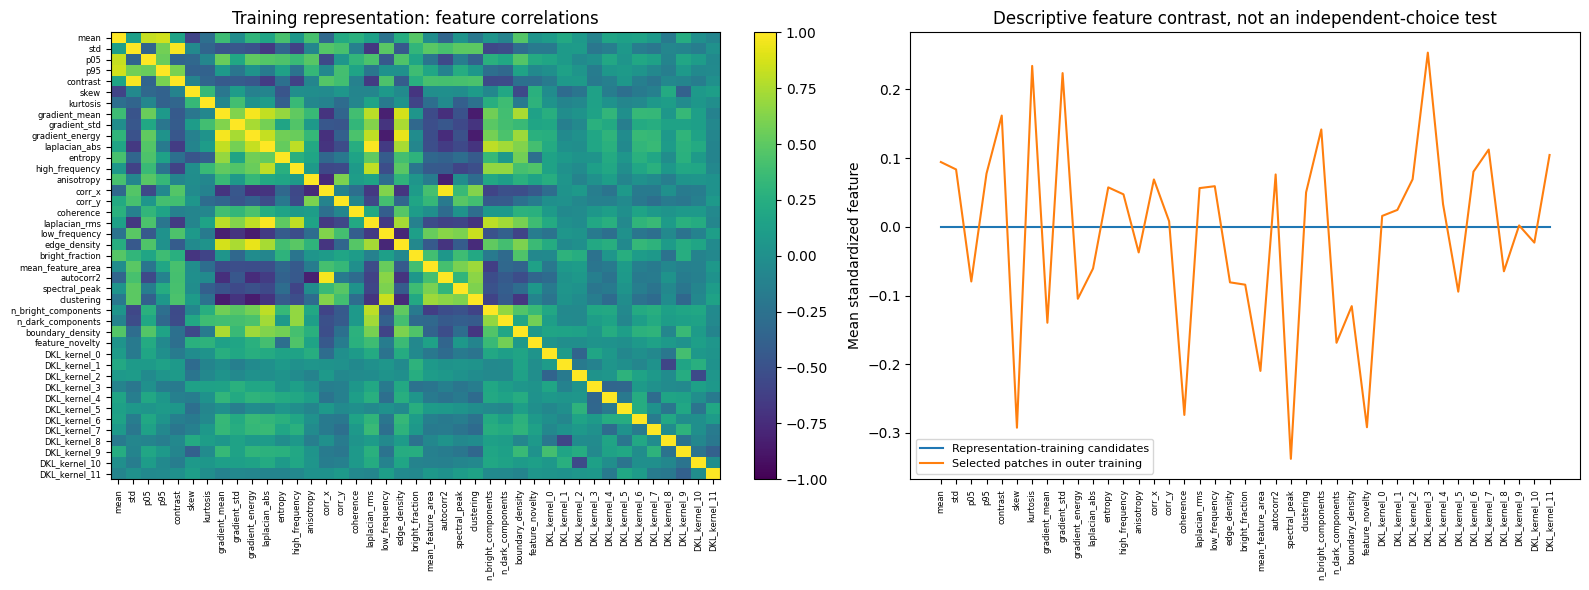

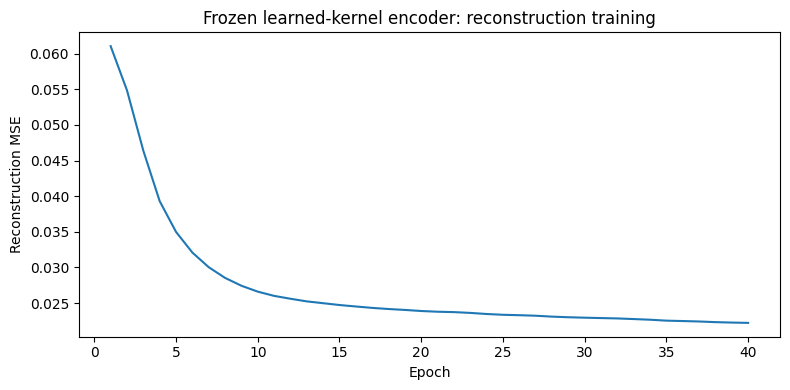

In [ ]:
plot_representation(DETAIL, DETAIL["folder"], show=True)

## 11.2 Stationary model — definition, stability, and decision margins

The plot shows training-fit coefficients and exploratory 95% percentile intervals from **moving-block**
bootstrap refits. Blocks preserve short-range ordering within each sampled block, not arbitrary long-range
nonstationarity. Intervals are drawn at their actual endpoints, even when the point estimate lies outside them.
Highly correlated features can make individual coefficients unstable despite stable predictions.

The decision margin is
$$\Delta_t = R(x_{t,a_t}) - \max_{j\ne a_t}R(x_{t,j}).$$
A positive margin means a unique top-ranked match. Zero includes ties. Train and test margin distributions
are plotted separately. An HMM mixture does not have one linear utility vector, so cross-model margins later
use **log probabilities**, not averages of state utilities.

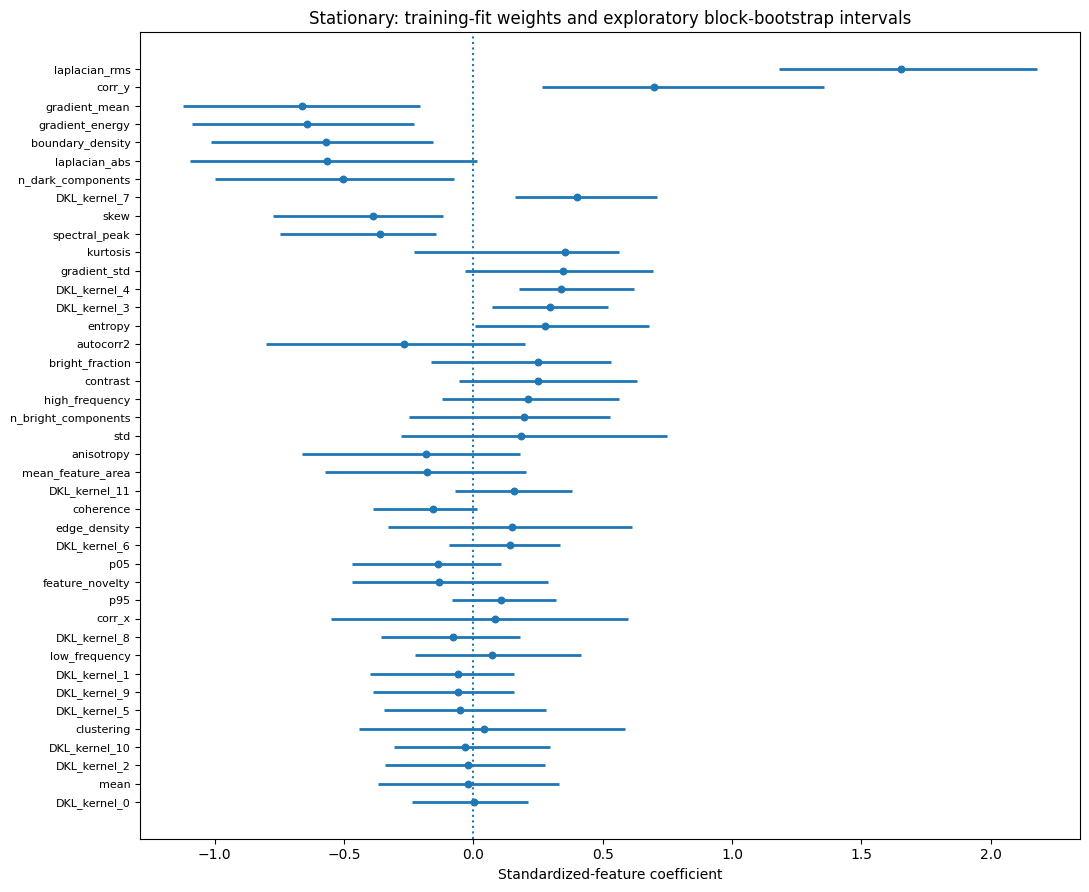

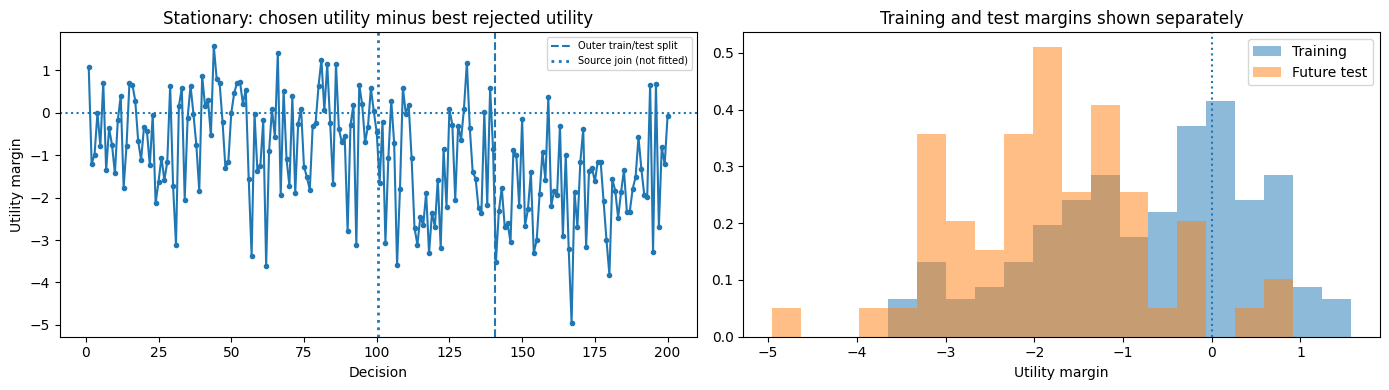

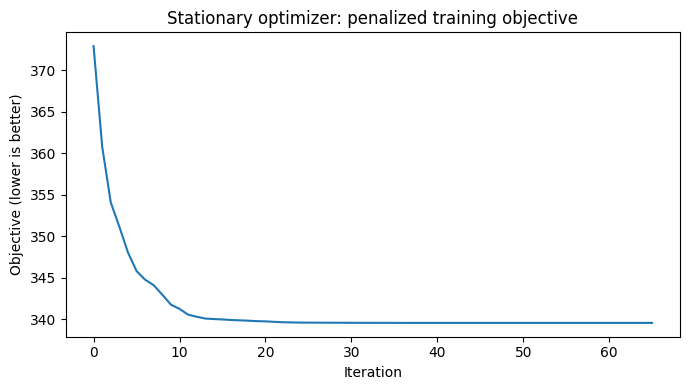

In [ ]:
plot_stationary_diagnostics(DETAIL, DETAIL["folder"], show=True)

## 11.3 Discrete HMM — definitions, evolution, distinguishability, and K

This section contains only the discrete HMM: coefficients, posterior probabilities, Viterbi and marginal
paths, transitions, occupancy, dwell times, pairwise policy JS divergence, choice agreement, causal test beliefs,
training objectives, and inner-validation K comparison. A low-JS flag is a diagnostic threshold, not a claim
that a statistically determined number of cognitive states has been discovered.

Offline paths use the stated descriptive fitting scope. They must not be substituted for the prechoice
beliefs used in prospective scoring. Dwell times at K=1 are infinite by definition.

,state,occupancy,expected_dwell_decisions,next_belief,fit_scope,higher_values_favored,higher_values_disfavored,kernel_coefficient_norm
0,0,0.499108,81.500607,0.003101,Descriptive refit on all observations,"laplacian_rms (+1.693), corr_y (+1.011), gradi...","n_dark_components (-0.763), p05 (-0.673), lapl...",0.916176
1,1,0.500892,396.257041,0.996899,Descriptive refit on all observations,"feature_novelty (+0.536), mean (+0.412), aniso...","skew (-1.077), gradient_energy (-0.695), gradi...",0.692943


,K,validation_count,validation_nll,validation_top1,validation_top3,fit_objective
0,1,28,3.941200,0.107143,0.214286,-244.673186
1,2,28,2.955421,0.142857,0.392857,-221.882097
2,3,28,3.553495,0.071429,0.285714,-219.899040
3,4,28,3.118668,0.142857,0.214286,-222.537304


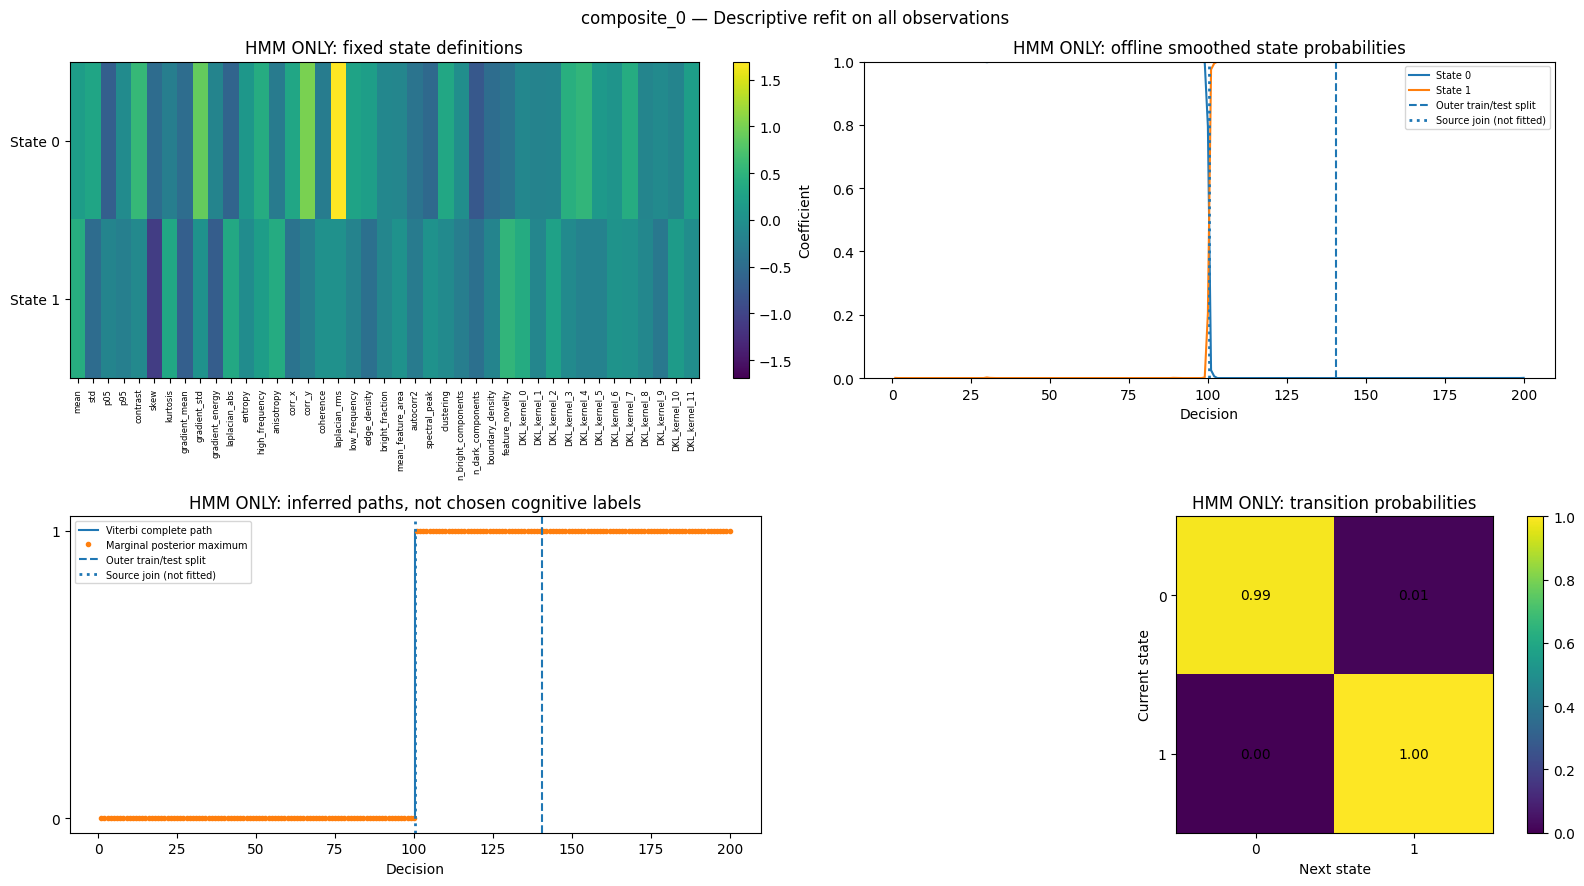

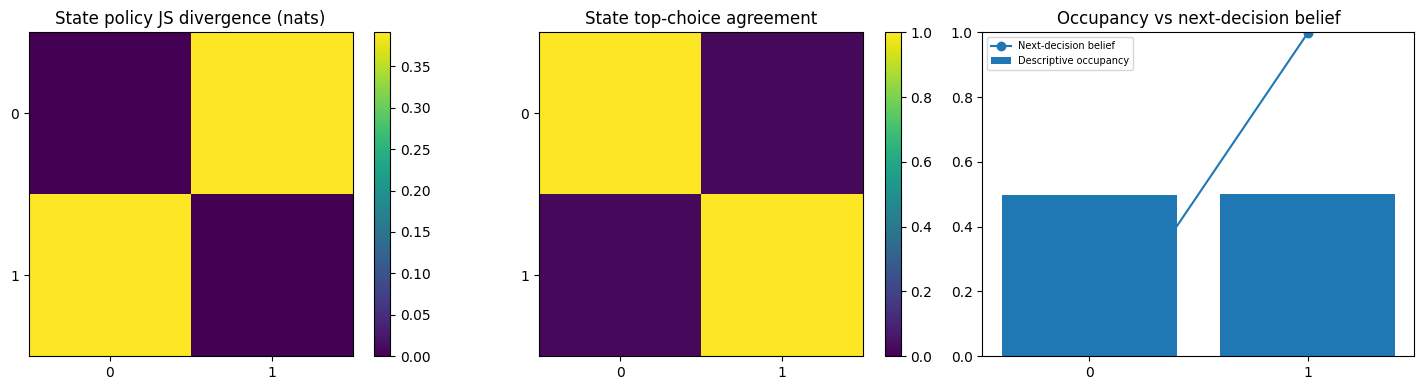

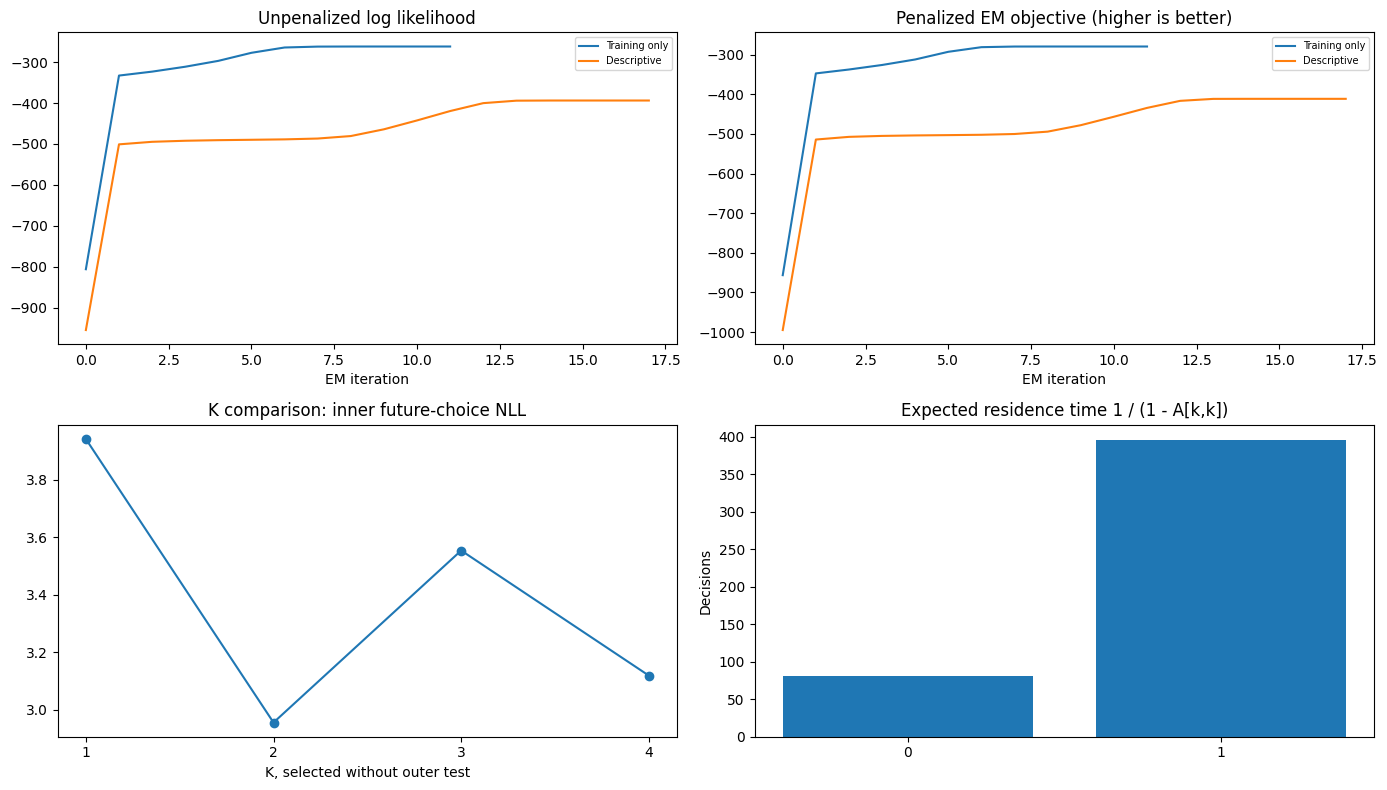

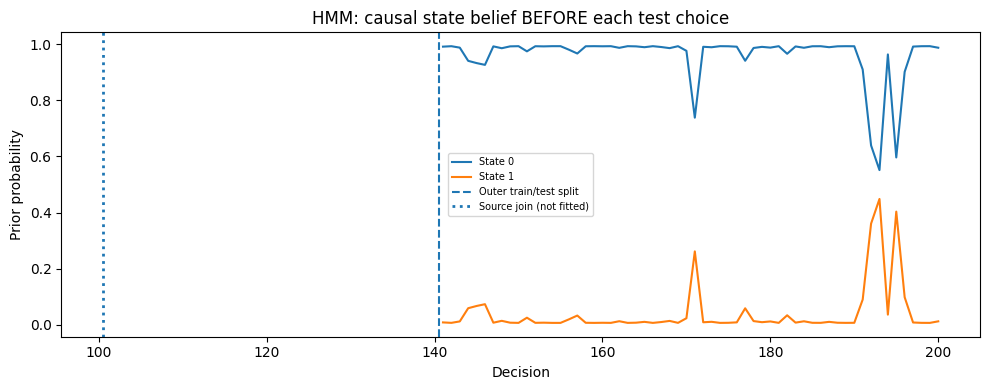

,state_i,state_j,mean_js_nats,top1_agreement,weight_distance,low_js_flag
0,0,1,0.390984,0.02,3.681313,False


,restart,matched_mean_js,assignment_to_best
0,0,1.979991e-09,"{0: 0, 1: 1}"
1,1,0.000000e+00,"{0: 0, 1: 1}"
2,2,1.447497e-09,"{0: 1, 1: 0}"


In [ ]:
display(describe_states(DETAIL))
display(DETAIL["K_comparison"])
plot_hmm_diagnostics(DETAIL, DETAIL["folder"], show=True)
state_pairs, _, _ = state_similarity(DETAIL)
display(state_pairs)
display(restart_alignment(DETAIL))

## 11.4 Continuous model — separate temporal preferences

This section contains no HMM state labels. It shows the full coefficient-time heatmap, the most variable
coefficients, the magnitude of successive changes, and a two-dimensional PCA view of the coefficient path.
The PCA is a visualization of fitted coefficients, not a discovered physical latent space. The maps in
Section 11.7 will show the corresponding preferences at several times and on either side of a source join.

,decision,fit_scope,higher_values_favored,higher_values_disfavored,kernel_coefficient_norm
0,1,Descriptive refit on all observations,"laplacian_rms (+2.904), gradient_std (+1.237),...","p05 (-1.028), laplacian_abs (-0.991), feature_...",1.538129
1,100,Descriptive refit on all observations,"laplacian_rms (+3.114), corr_y (+0.876), mean ...","gradient_energy (-1.954), laplacian_abs (-1.19...",0.796051
2,101,Descriptive refit on all observations,"laplacian_rms (+3.102), corr_y (+0.822), mean ...","gradient_energy (-1.980), autocorr2 (-1.175), ...",0.807924
3,200,Descriptive refit on all observations,"feature_novelty (+1.327), high_frequency (+0.6...","gradient_energy (-2.254), skew (-2.220), autoc...",2.222303


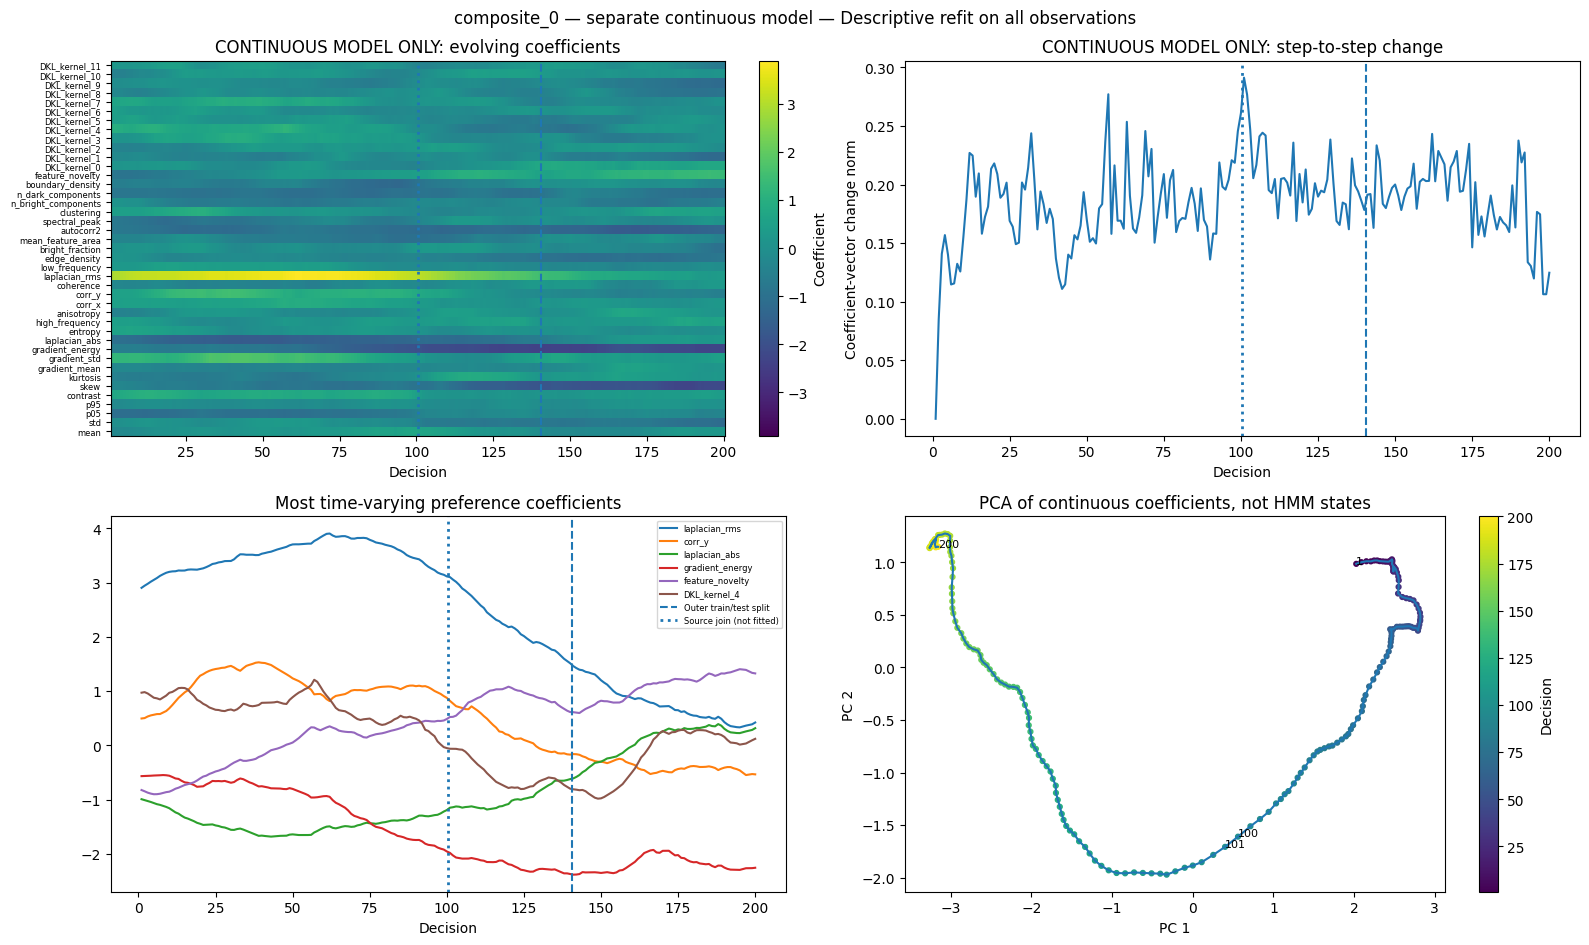

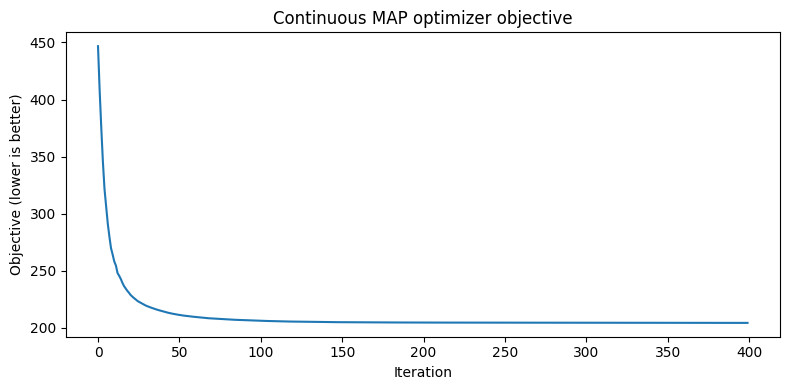

In [ ]:
display(continuous_definitions(DETAIL))
plot_continuous_diagnostics(DETAIL, DETAIL["folder"], show=True)

## 11.5 Predictive comparison — what the models actually anticipate

Four curves compare three families: stationary, HMM, continuous frozen, and continuous online MAP.
All use the same chronological held-out choices. The HMM is updated only **after** predicting the current
choice. The online continuous tracker follows the same causal order. Repeated source decisions are excluded
from aggregate generalization metrics, with their status retained in the exported per-decision table.

Lower NLL and lower rank are better. Higher top-1/top-3 accuracy and selected-choice probability are better.
For M candidates, uniform references are log(M), (M+1)/2, 1/M, and min(3,M)/M as appropriate.
The cumulative log-likelihood gain over stationary is
$$G_n = \sum_{t\le n}\left[\log p_{\mathrm{model}}(a_t)-\log p_{\mathrm{stationary}}(a_t)\right].$$
Reliability diagrams include the number of observations in each bin. Small test sets do not establish
calibration merely because a line lies close to the diagonal.

,model,decisions,nll,top1,top3,mean_rank,selected_probability
0,Stationary,60,3.291033,0.050000,0.216667,9.016667,0.060390
1,HMM,60,2.699935,0.250000,0.500000,6.133333,0.191214
2,Continuous frozen,60,4.275563,0.183333,0.466667,6.266667,0.196143
3,Continuous online MAP,60,3.450870,0.233333,0.466667,5.816667,0.205416


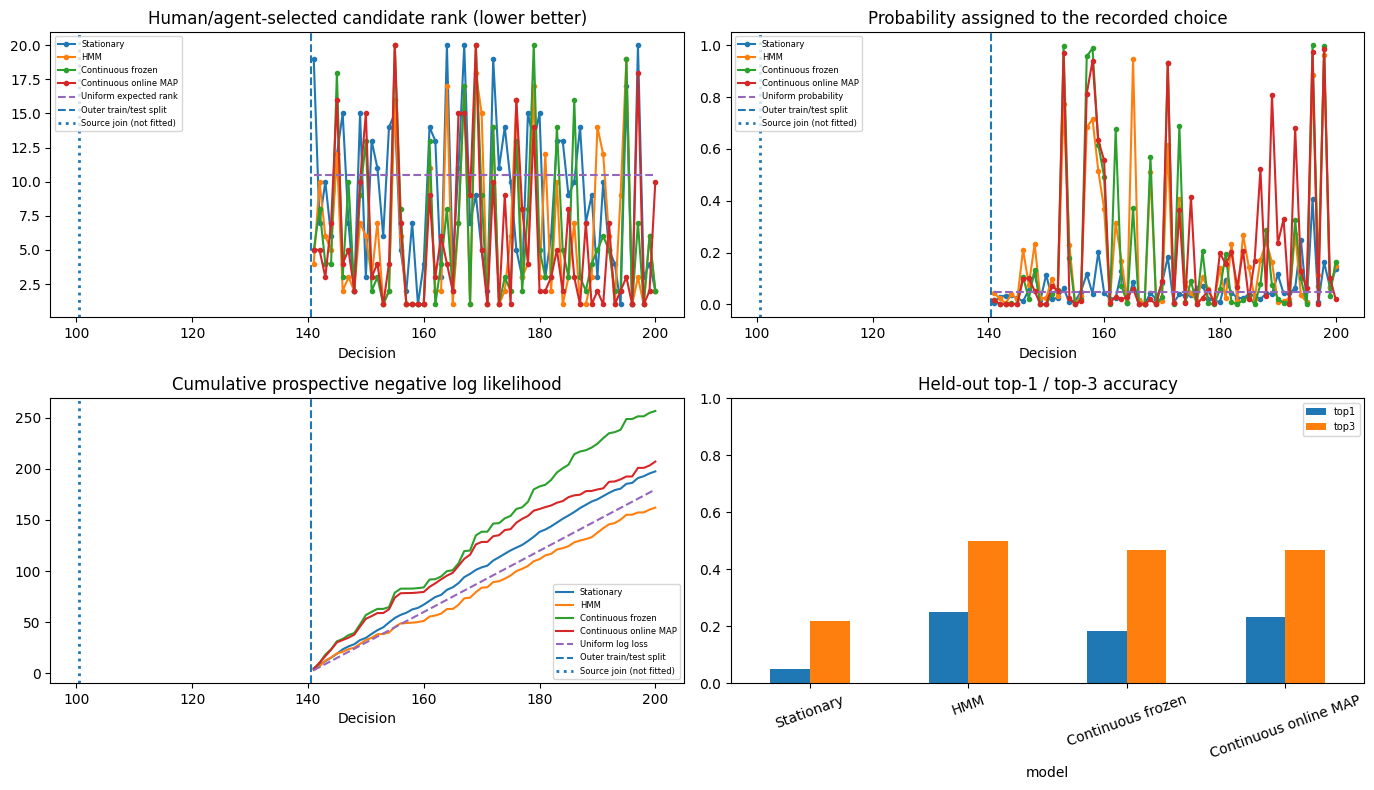

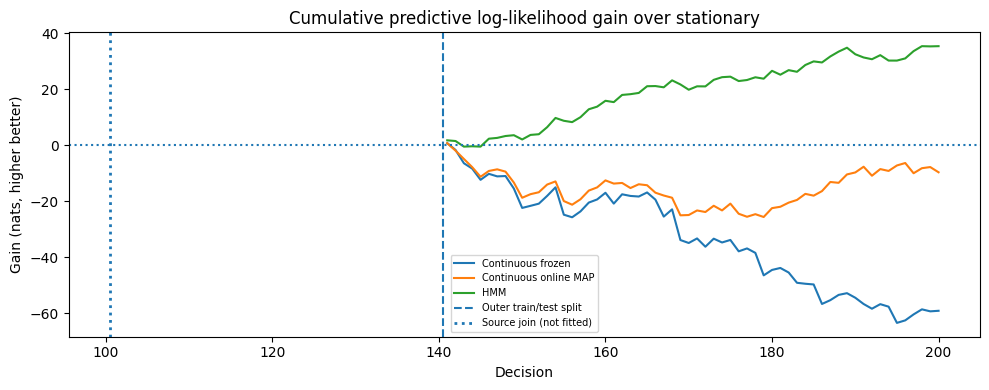

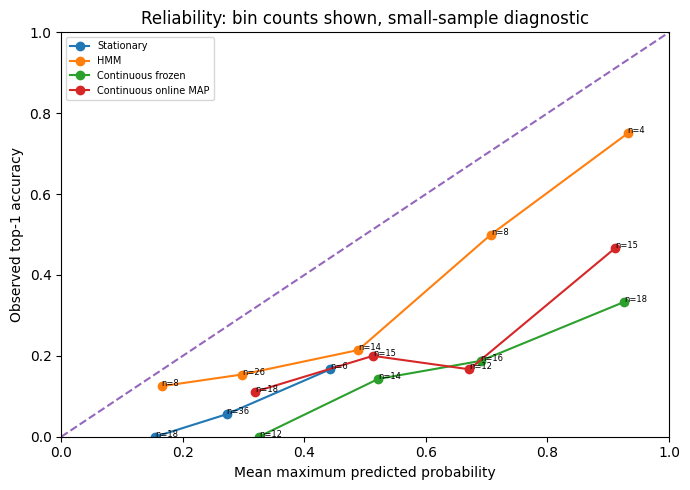

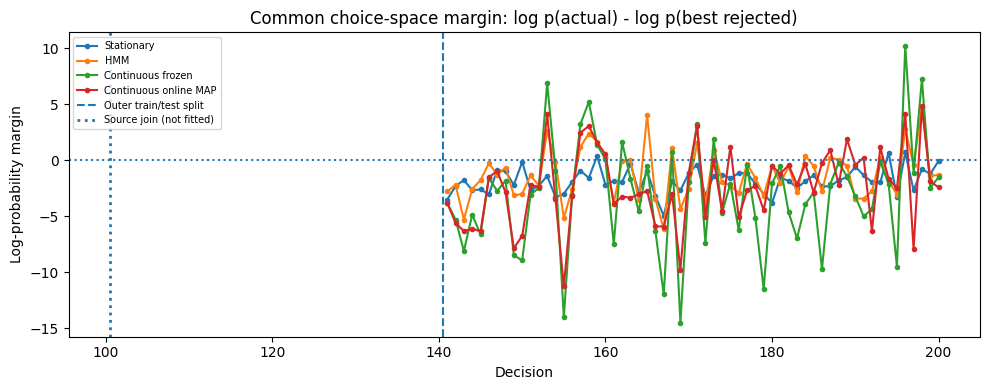

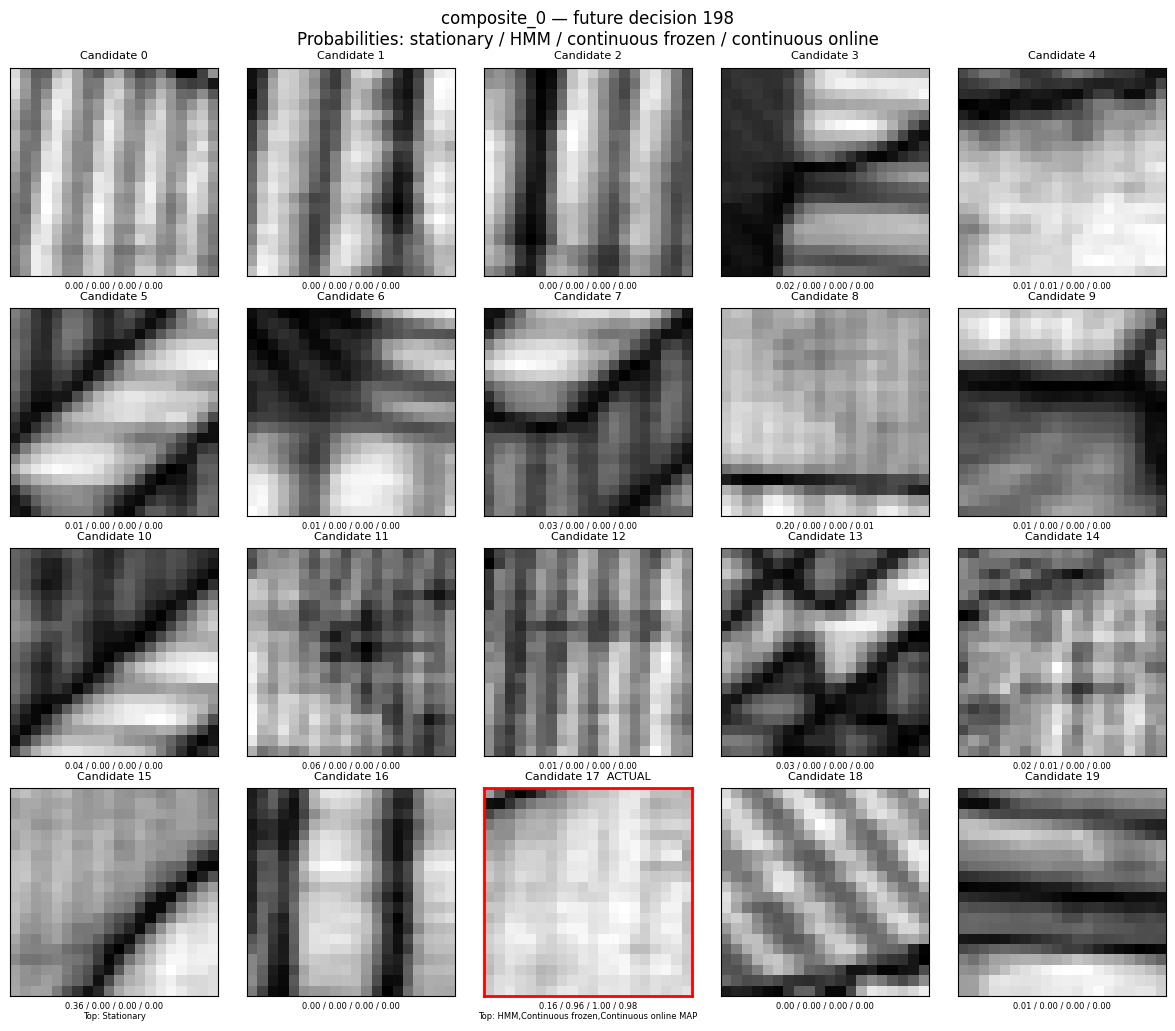

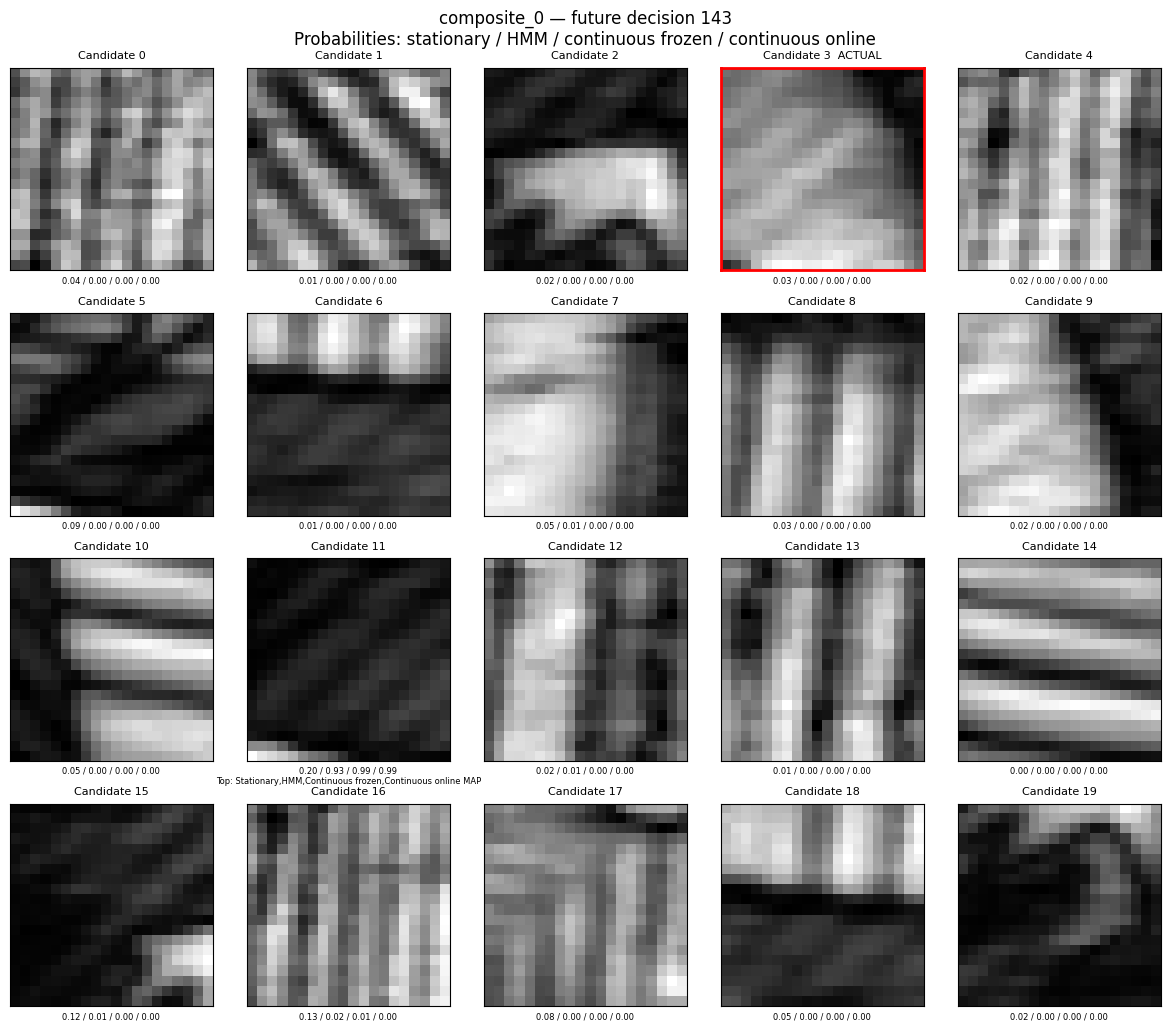

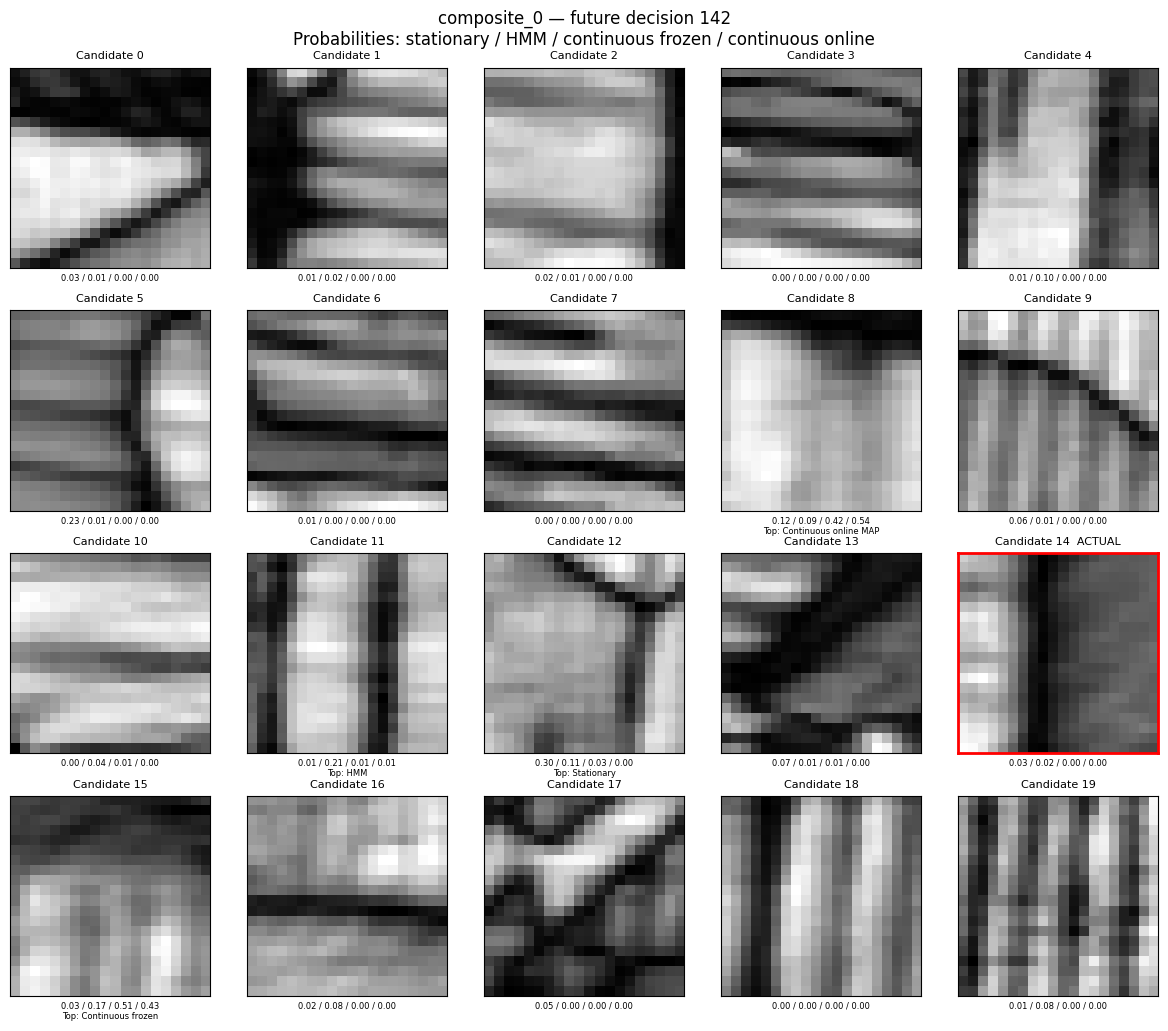

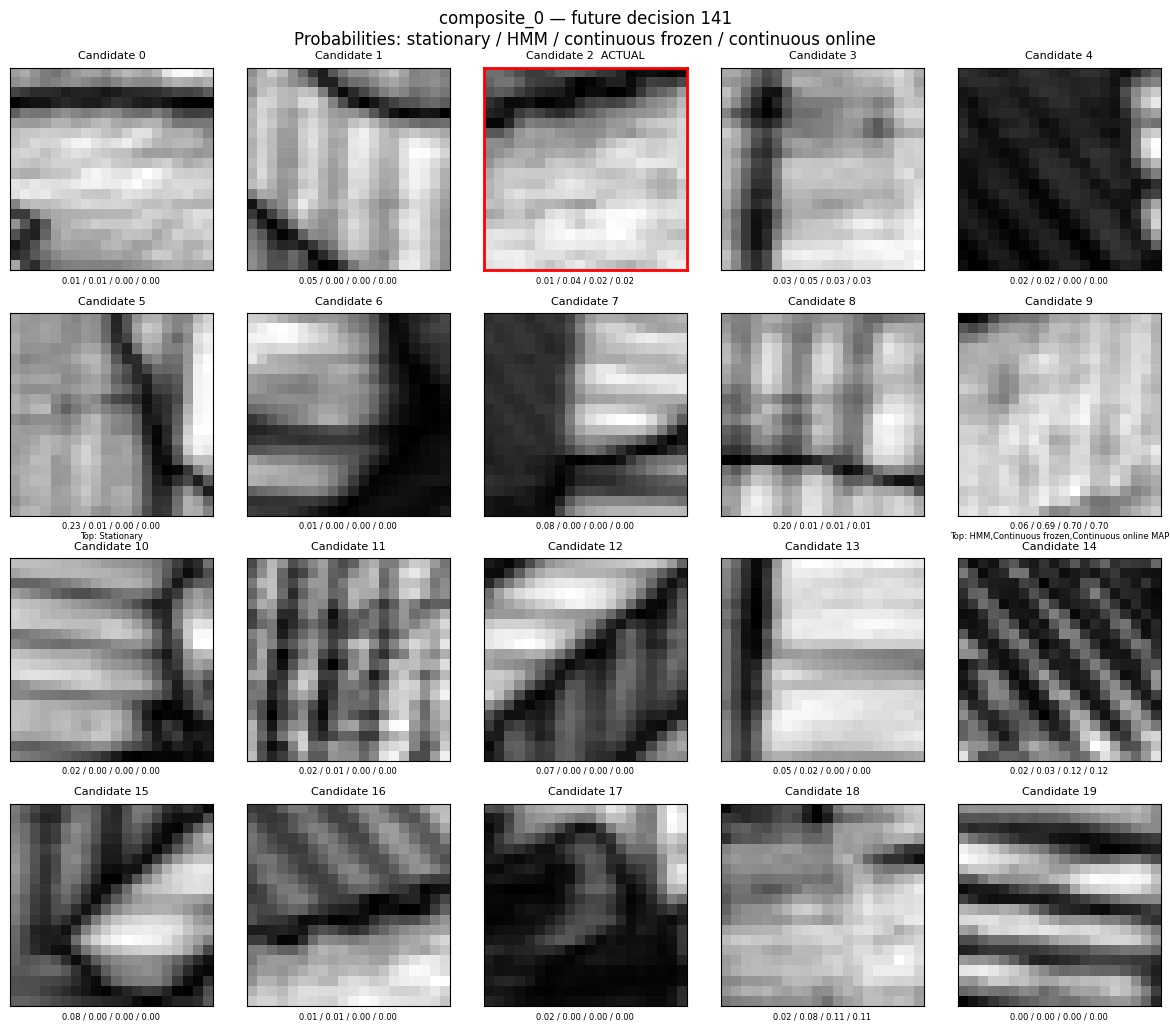

In [ ]:
display(DETAIL["evaluation"]["metrics"])
plot_prediction_diagnostics(DETAIL, DETAIL["folder"], show=True)
plot_candidate_mosaics(DETAIL, DETAIL["folder"], show=True)

## 11.6 Visual state definitions using actual candidate patches

High- and low-utility galleries complement coefficient tables, particularly for the learned-kernel block.
These are real patches from the supplied trace, ranked by the fitted model. “Low utility” does not mean
“experimentally bad” or “always rejected.” Contrasting-state pairs are drawn from the **same candidate set**.
When two states always choose the same top candidate, no artificial discriminative pair is created.

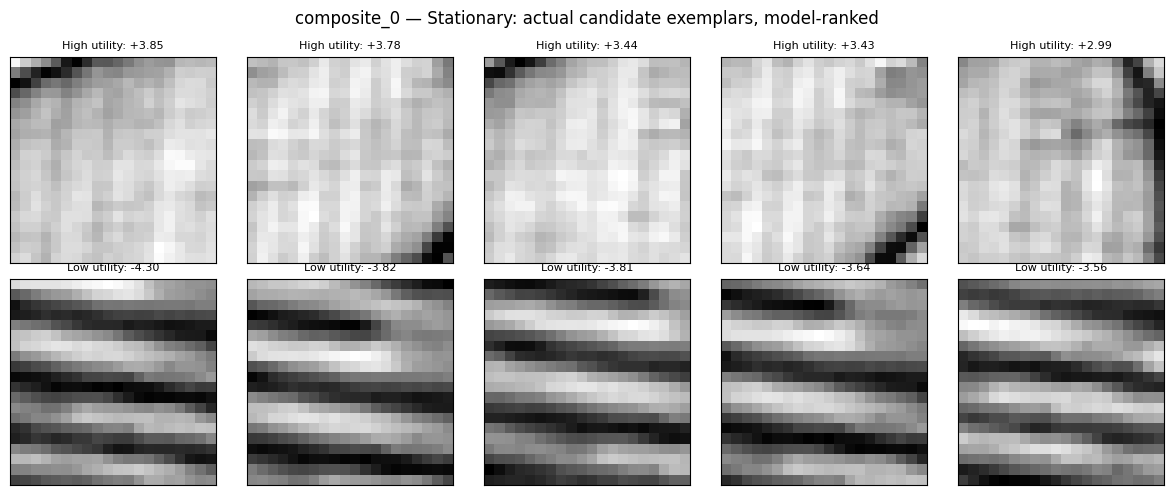

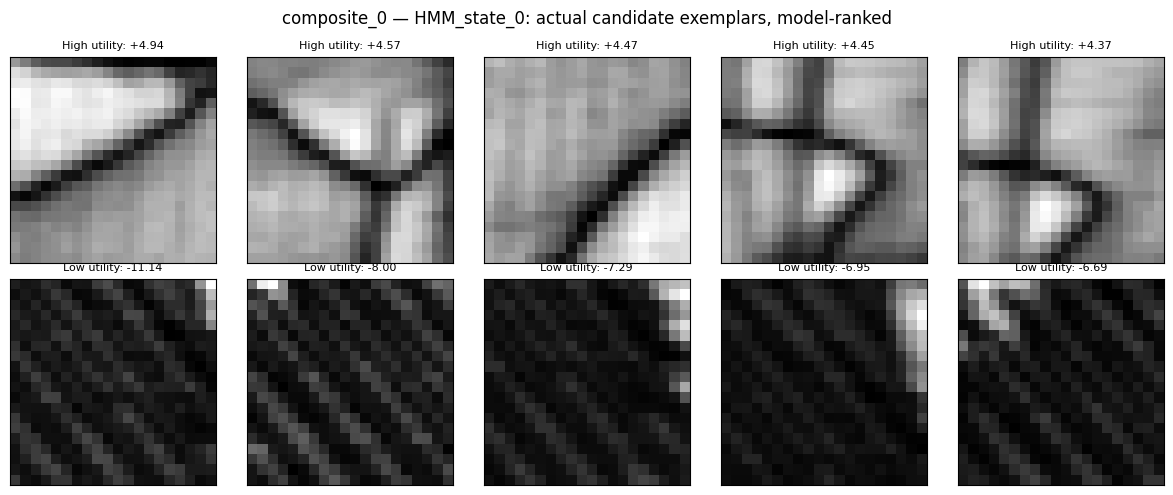

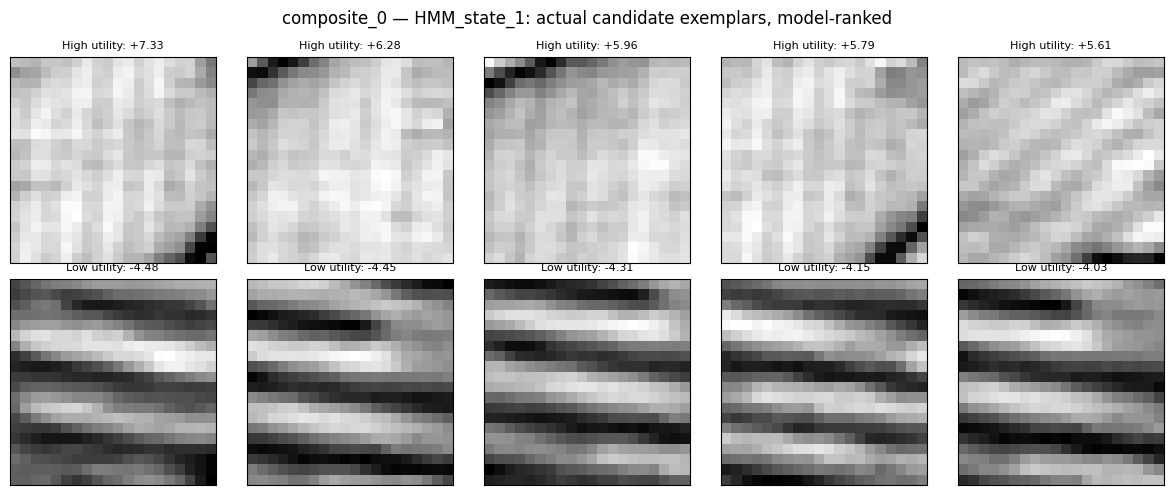

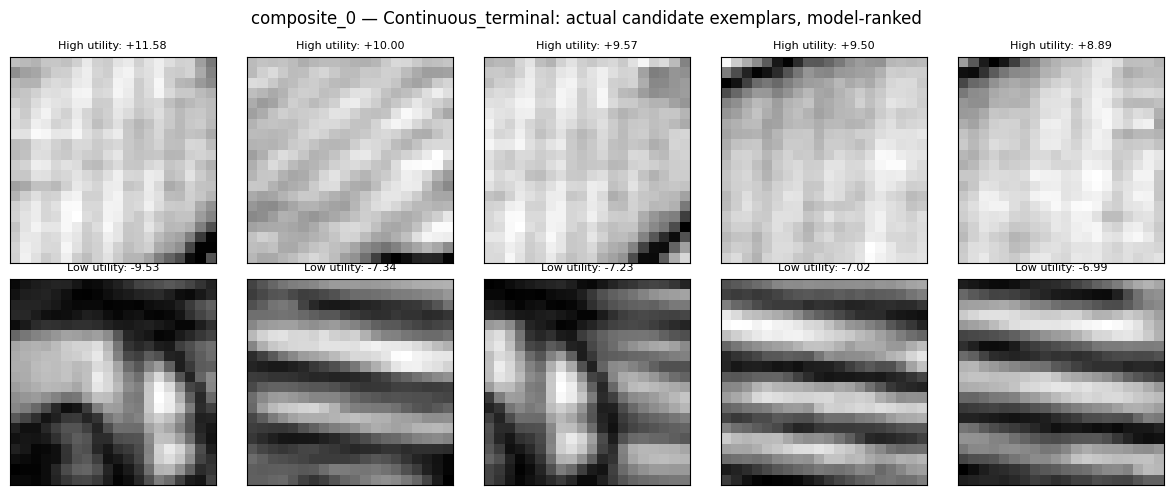

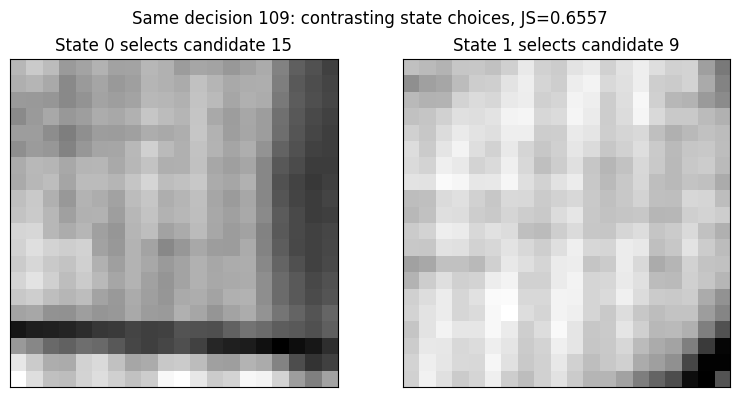

In [ ]:
plot_visual_state_definitions(DETAIL, DETAIL["folder"], show=True)

## 11.7 Dense reward atlas and time-specific maps

Definitions appear before the maps. The top-left panel contains the only original microscopy image,
with recorded points in red and proposed additional points in blue. All other panels show reward,
probability, or disagreement fields alone. The HMM state maps share a scale. Other models and variance
maps have separately labeled scales. Percentile color limits can clip extremes for display only, and
all raw values are saved unchanged.

For next-step belief $b$, the between-state utility variance is
$$\bar R(\mathbf r)=\sum_k b_k R_k(\mathbf r),\qquad
V(\mathbf r)=\sum_k b_k[R_k(\mathbf r)-\bar R(\mathbf r)]^2.$$
Equal-weight variance is also shown because a concentrated belief can conceal differences between states.
A shared additive shift changes neither choices nor this variance, but state-specific offsets can affect
utility variance without affecting choices. We use a common training feature reference and also report
behavioral state disagreement. Neither variance estimates within-state reward-parameter uncertainty.

The blue points exclude recorded-location neighborhoods. If there are fewer feasible points than requested,
the report gives the actual number. These points come from a frozen ranked map and are not a rollout that
pretends to receive future human choices or microscope feedback.

### composite_0 — definitions before maps

**Fit scope:** Descriptive refit on all observations. Predictive scores are from separate training-only fits.

**Stationary model:** one fixed preference function.

,higher_values_favored,higher_values_disfavored,kernel_coefficient_norm
0,"laplacian_rms (+1.188), corr_y (+0.385), kurto...","gradient_energy (-0.755), skew (-0.657), autoc...",0.526001


**Discrete HMM:** fixed definitions, changing state probabilities.

,state,occupancy,expected_dwell_decisions,next_belief,fit_scope,higher_values_favored,higher_values_disfavored,kernel_coefficient_norm
0,0,0.499108,81.500607,0.003101,Descriptive refit on all observations,"laplacian_rms (+1.693), corr_y (+1.011), gradi...","n_dark_components (-0.763), p05 (-0.673), lapl...",0.916176
1,1,0.500892,396.257041,0.996899,Descriptive refit on all observations,"feature_novelty (+0.536), mean (+0.412), aniso...","skew (-1.077), gradient_energy (-0.695), gradi...",0.692943


**Separate continuous model:** coefficients evolve, no discrete state labels.

,decision,fit_scope,higher_values_favored,higher_values_disfavored,kernel_coefficient_norm
0,1,Descriptive refit on all observations,"laplacian_rms (+2.904), gradient_std (+1.237),...","p05 (-1.028), laplacian_abs (-0.991), feature_...",1.538129
1,100,Descriptive refit on all observations,"laplacian_rms (+3.114), corr_y (+0.876), mean ...","gradient_energy (-1.954), laplacian_abs (-1.19...",0.796051
2,101,Descriptive refit on all observations,"laplacian_rms (+3.102), corr_y (+0.822), mean ...","gradient_energy (-1.980), autocorr2 (-1.175), ...",0.807924
3,200,Descriptive refit on all observations,"feature_novelty (+1.327), high_frequency (+0.6...","gradient_energy (-2.254), skew (-2.220), autoc...",2.222303


Signs are conditional statistical associations. Kernel coordinates have no individual physical names. State labels are not aligned across traces. Variance below is between HMM utilities, not GP uncertainty.

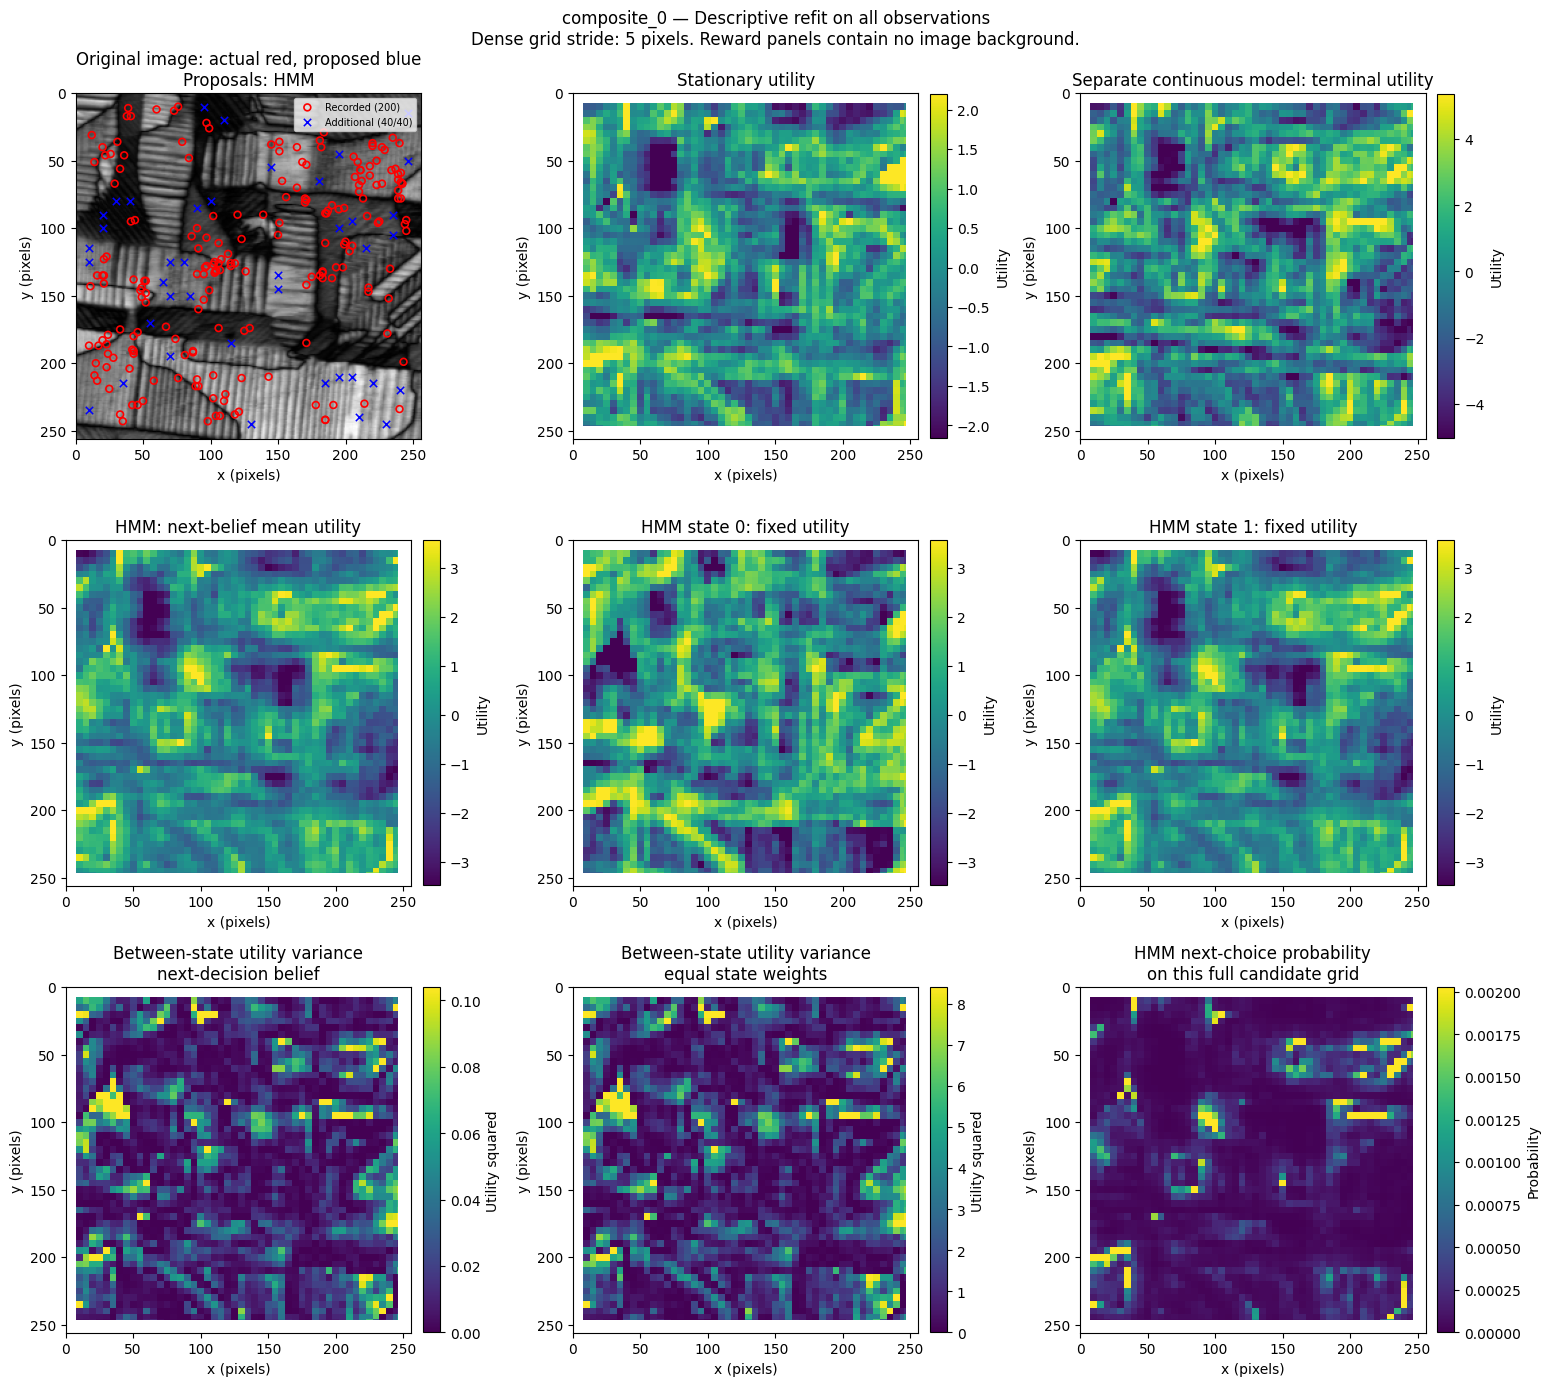

,rank,x,y,full_grid_probability,distance_to_nearest_recorded,grid_index,model
0,1,205.0,95.0,0.021730,11.661904,872,HMM
1,2,35.0,215.0,0.007857,10.770330,2014,HMM
2,3,246.0,15.0,0.007584,21.095023,97,HMM
3,4,30.0,80.0,0.003189,13.038405,690,HMM
4,5,150.0,145.0,0.002818,21.213203,1351,HMM
5,6,85.0,150.0,0.002817,10.440307,1387,HMM
6,7,10.0,235.0,0.002225,21.931712,2205,HMM
7,8,230.0,245.0,0.002221,14.866069,2347,HMM
8,9,240.0,220.0,0.001958,14.000000,2104,HMM
9,10,40.0,80.0,0.001843,14.560220,692,HMM


In [ ]:
display_state_definitions(DETAIL, DETAIL["folder"], show=True)
plot_reward_atlas(DETAIL, PARENT_IMAGE, DETAIL["folder"], show=True)
display(DETAIL["proposals"][CONFIG["proposal_model"]])

### Continuous-model snapshot definitions before its maps

These time-specific definitions belong to the continuous model, not to the discrete HMM states above.
The original top-left panel for this figure uses the continuous model's proposed locations.

,decision,fit_scope,higher_values_favored,higher_values_disfavored,kernel_coefficient_norm
0,1,Descriptive refit on all observations,"laplacian_rms (+2.904), gradient_std (+1.237),...","p05 (-1.028), laplacian_abs (-0.991), feature_...",1.538129
1,100,Descriptive refit on all observations,"laplacian_rms (+3.114), corr_y (+0.876), mean ...","gradient_energy (-1.954), laplacian_abs (-1.19...",0.796051
2,101,Descriptive refit on all observations,"laplacian_rms (+3.102), corr_y (+0.822), mean ...","gradient_energy (-1.980), autocorr2 (-1.175), ...",0.807924
3,200,Descriptive refit on all observations,"feature_novelty (+1.327), high_frequency (+0.6...","gradient_energy (-2.254), skew (-2.220), autoc...",2.222303


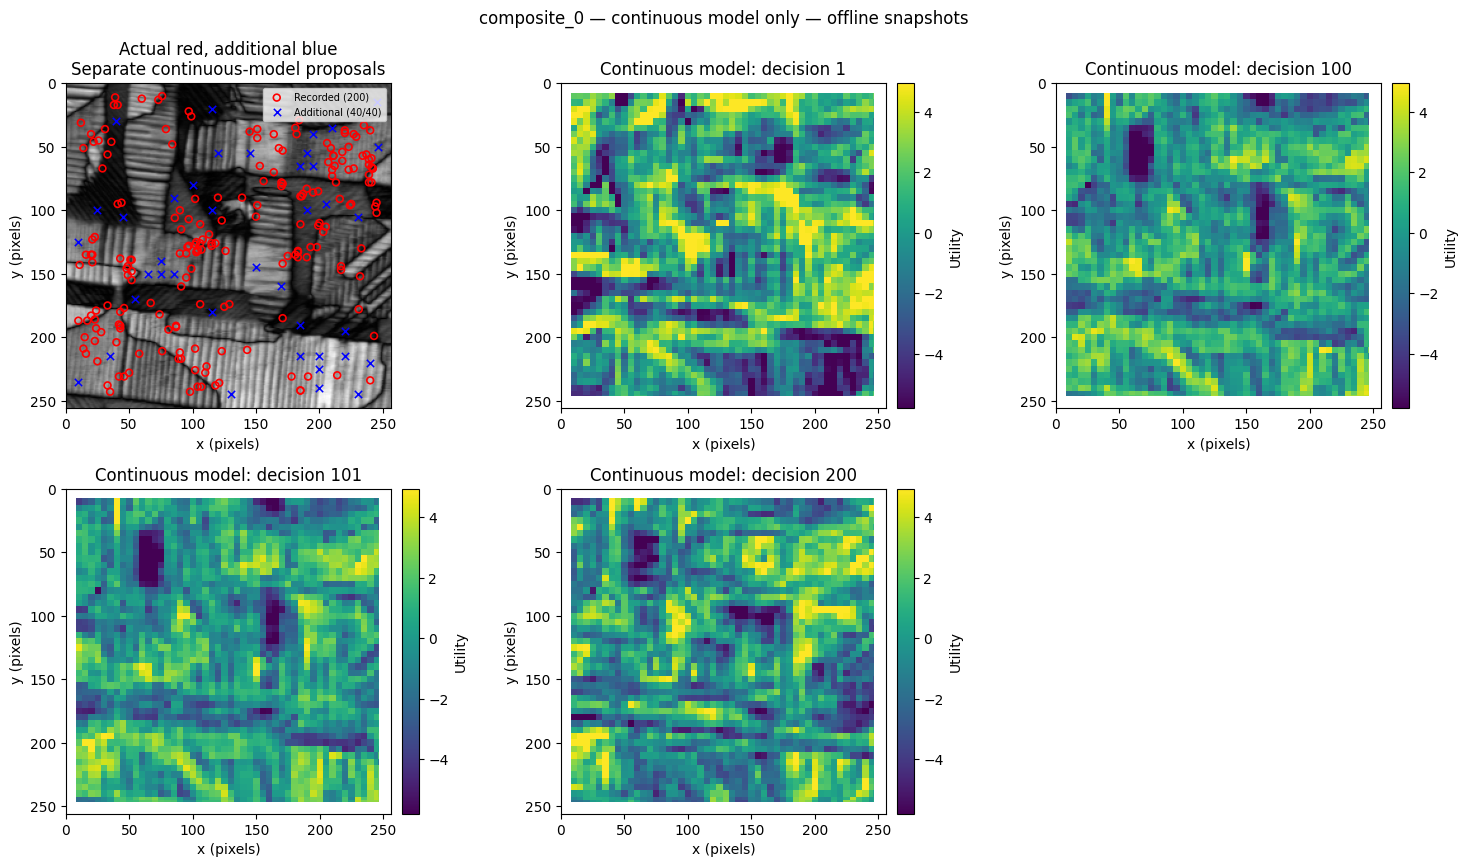

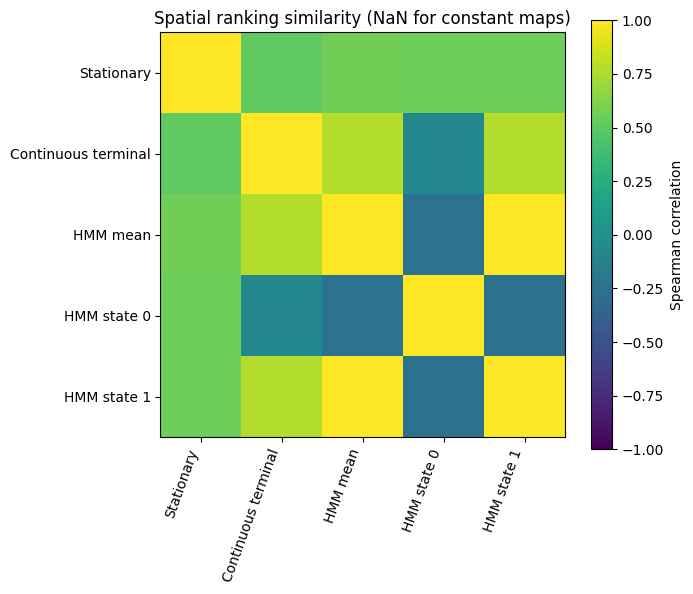

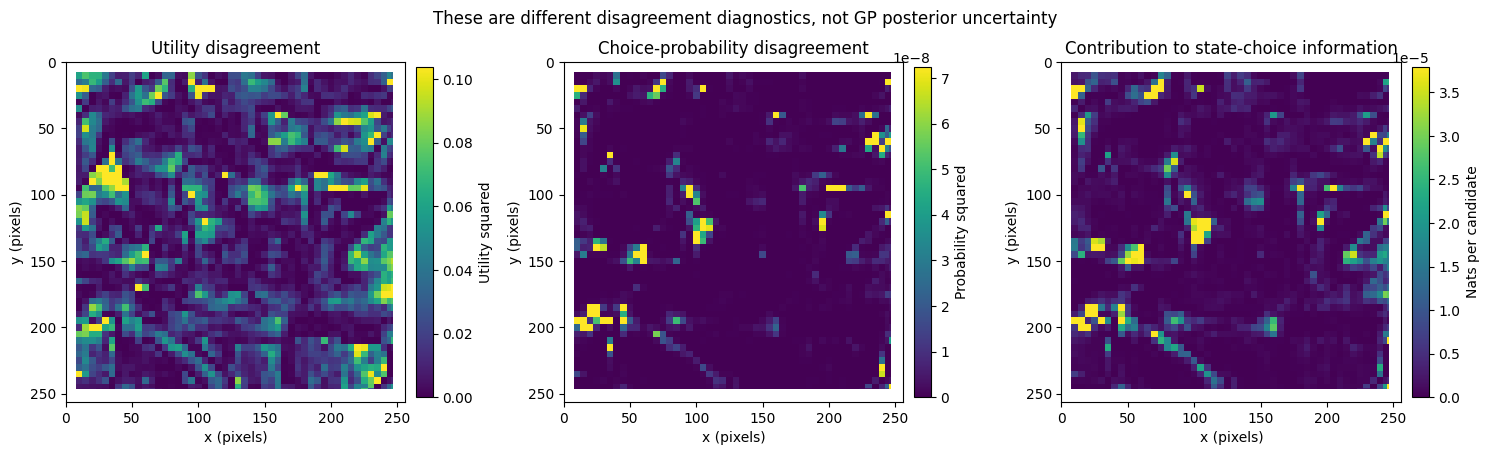

In [ ]:
display(continuous_definitions(DETAIL))
plot_continuous_spatial_snapshots(DETAIL, PARENT_IMAGE, DETAIL["folder"], show=True)
plot_spatial_comparisons(DETAIL, PARENT_IMAGE, DETAIL["folder"], show=True)
write_trace_html(DETAIL)

# 12. Every original trace and all four composites

The loop below visits the complete catalog, not just the four composites or the first ten original traces.
It reuses the detailed fitted object and independently fits every other dataset. Full diagnostics are saved
for each one when `save_full_reports_for_all=True`. Condensed reports always include state definitions,
separate HMM/continuous evolution, dense maps, **between-state utility variance**, actual/additional locations,
and held-out prediction diagnostics. The dataset status is recorded even if a fit fails.

With the default source list, this runs 15 datasets. The autoencoder, multiple HMM restarts, K scans,
bootstrap refits, dense inference, and many figures can take appreciable time. To reduce cost without
removing datasets, reduce encoder epochs, bootstrap repeats, restarts, or K_values in the opening cell.

In [ ]:
for name, info in DATA.items():
    started = time.perf_counter()
    try:
        print(f"Analyzing {name}: {len(info['records'])} decisions")
        if name in RESULTS:
            current = RESULTS[name]
        else:
            current = analyze_dataset(info)
            calculate_spatial_maps(current, PARENT_IMAGE)
            export_result(current, PARENT_IMAGE, OUT / name)
            RESULTS[name] = current
        if CONFIG["save_full_reports_for_all"] and name != DETAILED_NAME:
            full_report(current, PARENT_IMAGE, show=False)
        condensed_report(current, PARENT_IMAGE, show=CONFIG["show_condensed_for_all"])
        RUN_STATUS.append({
            "dataset": name,
            "kind": info["kind"],
            "status": "OK",
            "K": current["K"],
            "actual_additional_count": len(current["proposals"][CONFIG["proposal_model"]]),
            "seconds_this_pass": time.perf_counter() - started,
            "detail": "See optimizer_status.csv for convergence checks",
        })
    except Exception as error:
        traceback.print_exc()
        RUN_STATUS.append({
            "dataset": name,
            "kind": info["kind"],
            "status": "ERROR",
            "K": np.nan,
            "actual_additional_count": np.nan,
            "seconds_this_pass": time.perf_counter() - started,
            "detail": f"{type(error).__name__}: {error}",
        })
        if CONFIG["fail_fast"]:
            raise
    pd.DataFrame(RUN_STATUS).to_csv(OUT / "run_status.csv", index=False)

ALL_METRICS, STATUS = cross_trace_summary(RESULTS, RUN_STATUS)
display(STATUS)
display(ALL_METRICS)
print("Expected dataset count:", len(DATA))
print("Datasets with fitted results:", len(RESULTS))
print("Report index:", (OUT / "index.html").resolve())

Output hidden; open in https://colab.research.google.com to view.

# 13. Output dictionary and limitations

| Saved output | Meaning |
|---|---|
| `state_interpretation.csv`, `state_definitions.csv` | Fixed HMM definitions, associations, occupancy and next-step belief |
| `state_evolution.csv` | Offline state probabilities, Viterbi path, marginal state and switch probability |
| `continuous_evolution.csv`, `continuous_snapshot_definitions.csv` | Separate continuous MAP trajectory and its time-specific definitions |
| `hmm_test_prior_and_posterior.csv` | Beliefs before and after each future choice, from training-only parameters |
| `decision_predictions.csv`, `candidate_choice_probabilities.csv` | Prospective decisions and complete within-set distributions |
| `stationary_bootstrap_intervals.csv` | Exploratory block-bootstrap coefficient stability |
| `state_similarity.csv`, `restart_alignment.csv` | Behavioral redundancy and label-aligned restart comparison |
| `spatial_maps.npz` | Dense utilities, both state variances, probability disagreement, next belief and exact grids |
| `proposed_additional_*.csv`, `recorded_locations.csv` | Blue proposals and red recorded coordinates |
| `model_parameters.npz`, `metadata.json` | Predictive/descriptive parameters, scaling, scope and geometry |
| `report.html`, root `index.html` | Definitions-first browsing of complete per-trace outputs |
| `optimizer_status.csv`, `run_status.csv` | Convergence and dataset-processing status, not hidden warnings |

**Interpretive boundaries.** State labels are arbitrary across independently fitted traces. Composites reuse
original decisions and cannot be counted as independent replication. The concatenation boundary is not given
to a fitted policy and does not itself establish a change in human objectives. A flexible representation,
small sample size, highly correlated descriptors, or changing menus can explain apparent state structure.
Small variance may reflect similar states or a concentrated state belief. Utility scales and color ranges
are not calibrated across models or traces. Full-grid choice probabilities may not transfer unchanged to a
20-patch viewing interface. Proposed points imitate learned interest and are not guarantees of scientific value.

The retained `dkl` representation is an unsupervised autoencoder followed by a finite-rank Nyström RBF map.
It is **not** joint preference-DKL training and does not provide a GP posterior uncertainty. The three downstream
families remain stationary softmax, discrete HMM softmax, and continuous MAP softmax. A genuine GP preference
likelihood would be a separate extension.

### Source and implementation notes

The first 20 Day 20 source cells are copied from `ATHENA_Day20_Original_Preserved_Optimized_Analysis_(2).ipynb`.
The expanded descriptor and learned-kernel definitions are based on
`ATHENA_CAMM_Day21_Configurable_DKL_Composite_Traces.ipynb` with the edge-density correction disclosed above.
The diagnostic inventory and dense stride follow `ATHENA_CAMM_Day21_Detailed_One_Trace_All_Traces.ipynb`
and the later discussion in this chat.

Implementation references: scikit-learn's official
[Nystroem documentation](https://scikit-learn.org/stable/modules/generated/sklearn.kernel_approximation.Nystroem.html)
and Matplotlib's official
[grid and shading documentation](https://matplotlib.org/stable/gallery/images_contours_and_fields/pcolormesh_grids.html).
They describe the library operations used here, not validation of the scientific preference model.